# Online PCA: Baseline Experiments

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import time


# Find the project when Jupyter starts from either its root or notebooks folder
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / 'methods.py').is_file() and (p / 'data_generators.py').is_file()), None)
if PROJECT_ROOT is None:
    raise RuntimeError('Start Jupyter from online_pca_thesis or its notebooks folder.')
sys.path.insert(0, str(PROJECT_ROOT))

import data_generators
import methods
import metrics
import plots as ut
import benchmark
from data_generators import generate_stationary, generate_abrupt, covariance_at
from methods import leading_direction, cumulative_pca, forgetting_pca, incremental_pca, rank1_svd_pca
from metrics import axis_error, axis_angle_error, trailing_mean, recovery_delay
from benchmark import save_results


This notebook has four baseline method sections:

1. Cumulative covariance PCA
2. Fixed-gain forgetting PCA
3. Incremental PCA (rank-1 SVD update, $\alpha_n=1/n$)
4. Fixed-gain rank1 SVD forgetting PCA

Sliding-window PCA has its own notebook, `02_sliding_window.ipynb`.

Regime changes considered are:
1. Stationary regime
2. Abrupt angle change regime
3. Smooth angle rotation regime
4. Random angle drift regime


### Parameters

These values are arbitrary choices to define a common protocol, so that all methods and notebooks (01, 02, 03) are compared on the same data and with
the same measurements.

- **Data:** `n_samples`, `lam1`, `lam2`, `theta0`, `theta1`, `switch_step` (and `omega`, `q`, `dt` below).
  `lam1 = 5`, `lam2 = 0.5` give a clear spectral gap; the change at `switch_step` is a large jump of 60° in the middle of the stream.
- **Methods:** `gains` are three memory levels, from short (0.1) to long (0.005).
- **Evaluation:** `warmup`, `smooth_window`, `recovery_threshold`, `recovery_hold` define how errors and recovery are summarized; `seeds` is the number of independent streams.

**Sensitivity.** `04_sensitivity_analysis` checks how the conclusions depend on these choices:
- evaluation settings (threshold, hold, trailing window, warm-up): Part A, one at a time;
- the gain: Part B, a sweep from 0.002 to 0.3 at equal noise (see also `02_sliding_window`, Section 8);
- the number of seeds: Part A3, seed-by-seed comparison;
- the initial axis `theta0`: only a check at 1 rad for Oja and TW-API (`03_oja`, Section 3).

**Future work:** the data settings (`lam1`, `lam2`, `theta1`, `switch_step`, `n_samples`, `omega`, `q`). The results of these notebooks hold for this spectral gap and these changes; other gaps and noise levels (thesis proposal, Section 7.1) are left for a later sensitivity study.


In [2]:
n_samples = 2000
lam1 = 5.0
lam2 = 0.5
theta0 = 0.0
theta1 = np.pi / 3
switch_step = 1000

gains = [0.005, 0.02, 0.1]
seed = 0
seeds = range(20)
warmup = 200
smooth_window = 50
recovery_threshold = 0.05
recovery_hold = 50

steps = np.arange(1, n_samples + 1)
assert lam1 > lam2 >= 0
assert 0 < warmup < switch_step < n_samples
assert seed in seeds


# Common tools

These functions and measurements are shared by all four methods and all four regimes.
Cumulative and fixed-gain forgetting PCA assume a known zero population mean, so their second-moment matrices estimate covariance. Incremental PCA and rank-1 SVD PCA make the same assumption, but update a truncated SVD instead of a covariance matrix.

METRICS CONSIDERED:

- **Raw axis error:** $E_n=1-(\hat q_n^\top q_{\star,n})^2=\sin^2\phi_n$. Zero means the estimated axis is correct; one means it is perpendicular. Opposite vectors describe the same axis.
- **Trailing average error:** the mean of the latest `smooth_window` raw errors, including the current observation. In abrupt experiments, smoothing restarts after the change so pre-change errors are not mixed into the post-change average.
- **Cumulative error:** the sum of raw errors from observation 1 onward; every method has an estimate from the first observation. Its slope shows how quickly error accumulates. A flatter curve means smaller recent errors.
- **Signed angular error:** the estimated angle minus the current true angle, wrapped into $[-90^\circ,90^\circ)$ so opposite vectors represent the same axis, and expressed in degrees. For rotation and drift the reference changes at every observation.
- **Angular-error variability:** the temporal standard deviation of signed angular errors. A small SD means the error is consistent. In stationary data this describes fluctuations around a fixed true axis; in rotation and drift it describes variation in tracking error.
- **Captured variance:** the population variance captured by the estimated axis is
  $V_n=\hat q_n^\top\Sigma_n\hat q_n=\lambda_1\cos^2\phi_n+\lambda_2\sin^2\phi_n=\lambda_1-(\lambda_1-\lambda_2)E_n$.
  The plots show $100V_n/(\lambda_1+\lambda_2)$. The best possible percentage is $100\lambda_1/(\lambda_1+\lambda_2)$, approximately 90.91% with the current settings.
- **Repeated-run plot:** the line is the mean raw error at each observation across seeds. Shading shows the pointwise 10th-90th percentiles. For drift, the band reflects different angle trajectories as well as different observation noise.

In [3]:
# Rerunning the same method with the same settings updates its row
#  Changing settings or adding a method adds a row

results_csv = PROJECT_ROOT / 'results' / 'baselines' / 'pca_benchmark_results.csv'
results_csv.parent.mkdir(parents=True, exist_ok=True)
benchmark_settings = {
    'n_samples': n_samples, 'seeds': seeds, 'lam1': lam1, 'lam2': lam2,
    'theta0': theta0, 'theta1': theta1, 'switch_step': switch_step,
    'warmup': warmup, 'smooth_window': smooth_window,
    'recovery_threshold': recovery_threshold, 'recovery_hold': recovery_hold,
    'results_csv': results_csv,
}

### Metrics

**Evaluation periods**

- `warmup` observations are excluded from the usual mean-error and temporal-SD summaries: `errors[warmup:]` starts at observation `warmup + 1`. Warmup observations depend on the arbitrary initial state of the system rather on the gain, and for this they were excluded.
- Cumulative-error plots and the CSV common-period cumulative total start at observation 1 and include initial learning. The CSV also reports cumulative error after warm-up.
- The final segment is the last `warmup` observations. Final-sample error refers only to the last observation.

**Single-run and repeated-run summaries**

The single-run table describes the displayed seed. Repeated-run tables and CSV rows summarize the seed list, currently 20 runs. All methods use the same stored observations for a given regime and seed. Forgetting PCA keeps one row per gain, with its own 20 runs and runtimes.

- **Mean error:** average the raw errors over the evaluation period within each run, then average those run means.
- **SD of run means:** the standard deviation of those per-run mean errors. This measures differences between runs and uses `ddof=1`.
- **Mean temporal error SD:** calculate the raw-error SD over time within each run, then average those SDs. This measures within-run variation and uses `ddof=0`.
- **Final-segment summaries:** average errors over the final segment within each run; report the mean and, where shown, SD across runs.
- **Signed angular error:** for each run, the signed angular error is summarized over a period by its
  **mean** (the systematic offset or lag, with its sign), its **SD** (the oscillation around that mean) and its **RMS** (the total angular error); each is then averaged across seeds.

**Differences between regimes**

Stationary, smooth-rotation, and random-drift tables use the common summaries after warm-up. Rotation and drift compare each estimate with the changing true direction. Abrupt tables additionally separate pre-change errors (`warmup:switch_step`) and post-change errors (`switch_step:`), and report recovery. There is no single jump in the other regimes, so their recovery fields are left blank.

Recovery is confirmed only after a complete post-change trailing-average window is available and that average stays at or below `recovery_threshold` for `recovery_hold` consecutive values. The delay is the post-change observation at which this stable period starts (the first post-change observation is 1). The smallest possible delay is `smooth_window`. A run that does not meet this rule before the stream ends has no recorded delay; it is not assigned zero.

**Computational cost**

Runtime tables report mean, shortest, longest, and sample SD of runtime per complete stream across seeds. Only the PCA calculation is timed; generation, evaluation, plotting, and CSV writing are excluded. Background activity can affect runtime. Computational cost is presented as a table.

Rerunning the same experiment replaces its matching CSV row. Missing or inapplicable recovery values remain blank.

# Data

### Stationary Regime

In [4]:
stationary_streams = {}
for run_seed in seeds:
    X_run, theta_run, truth_run = generate_stationary(run_seed, n_samples=n_samples, lam1=lam1, lam2=lam2, theta0=theta0)
    # read-only arrays for accidental modification
    X_run.setflags(write=False)
    theta_run.setflags(write=False)
    truth_run.setflags(write=False)
    stationary_streams[run_seed] = (X_run, theta_run, truth_run)

X_stationary, theta_stationary, truth_stationary = stationary_streams[seed]

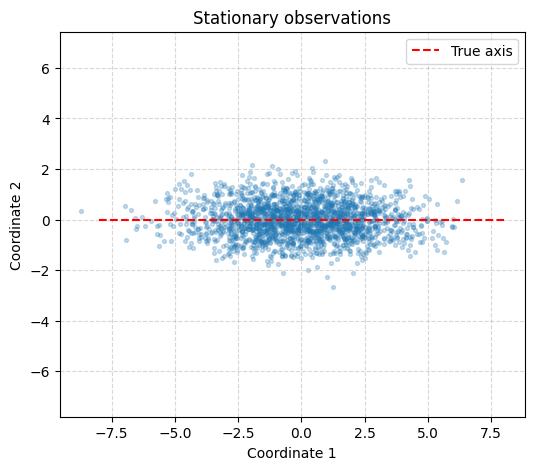

Empirical covariance:
[[ 5.024 -0.055]
 [-0.055  0.494]]
Theoretical covariance:
[[5.  0. ]
 [0.  0.5]]


In [5]:
# Shared stationary observations and empirical/theoretical covariance check.
ut.plot_stationary_data(X_stationary, theta0)

print('Empirical covariance:')
print(np.round(X_stationary.T @ X_stationary / len(X_stationary), 3))
print('Theoretical covariance:')
print(np.round(covariance_at(theta0, lam1, lam2), 3))

### Abrupt regime
At about half timesteps, the angle changes abruptly

In [6]:
abrupt_streams = {}
for run_seed in seeds:
    X_run, theta_run, truth_run = generate_abrupt(run_seed, n_samples=n_samples, lam1=lam1, lam2=lam2, theta0=theta0, theta1=theta1, switch_step=switch_step)
    X_run.setflags(write=False)
    theta_run.setflags(write=False)
    truth_run.setflags(write=False)
    abrupt_streams[run_seed] = (X_run, theta_run, truth_run)

X_abrupt, theta_abrupt, truth_abrupt = abrupt_streams[seed]

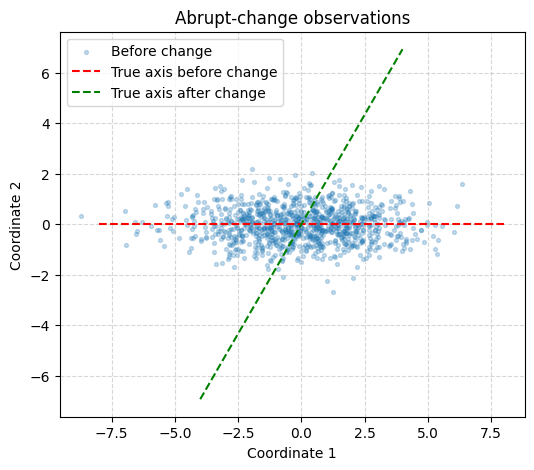

Before: empirical covariance, then theoretical covariance
[[ 5.199 -0.031]
 [-0.031  0.481]]
[[5.  0. ]
 [0.  0.5]]
After: empirical covariance, then theoretical covariance
[[1.661 1.92 ]
 [1.92  3.696]]
[[1.625 1.949]
 [1.949 3.875]]


In [7]:
# Shared observations before/after the jump, with covariance checks.
ut.plot_abrupt_data(X_abrupt, switch_step, theta0, theta1)
before = X_abrupt[:switch_step]
after = X_abrupt[switch_step:]

print('Before: empirical covariance, then theoretical covariance')
print(np.round(before.T @ before / len(before), 3))
print(np.round(covariance_at(theta0, lam1, lam2), 3))
print('After: empirical covariance, then theoretical covariance')
print(np.round(after.T @ after / len(after), 3))
print(np.round(covariance_at(theta1, lam1, lam2), 3))

### Continuous rotation

Angle rotates with constant angular speed `omega`. 

In [8]:
from data_generators import generate_smooth_rotation, generate_drift

omega = 0.001
q = 0.0001
dt = 1.0

rotation_streams = {}
for run_seed in seeds:
    X_run, theta_run, truth_run = generate_smooth_rotation(
        run_seed, n_samples=n_samples, lam1=lam1, lam2=lam2,
        theta0=theta0, omega=omega, dt=dt
    )
    # read-only arrays for accidental modification
    X_run.setflags(write=False)
    theta_run.setflags(write=False)
    truth_run.setflags(write=False)
    rotation_streams[run_seed] = (X_run, theta_run, truth_run)

X_rotation, theta_rotation, truth_rotation = rotation_streams[seed]

# Separate exports record the changing-direction parameters in the filename.
rotation_settings = dict(benchmark_settings)
rotation_settings.update(theta1='', switch_step='', recovery_threshold='', recovery_hold='')
rotation_settings['results_csv'] = results_csv.with_name(
    f'pca_rotation_results_omega={omega:g}_dt={dt:g}.csv'
)

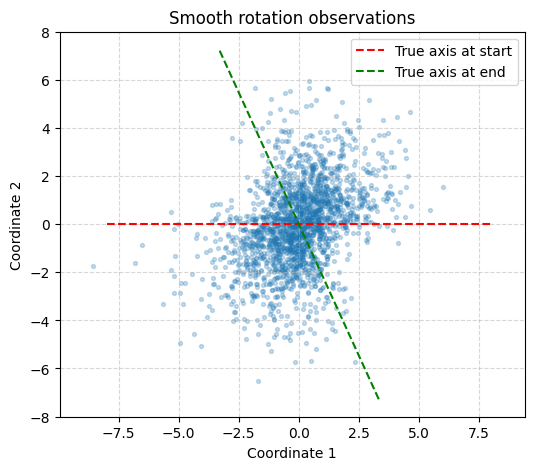

(<Figure size 600x500 with 1 Axes>,
 <Axes: title={'center': 'Smooth rotation observations'}, xlabel='Coordinate 1', ylabel='Coordinate 2'>)

In [9]:
ut.plot_smooth_rotation_data(X_rotation, theta0, omega, dt)
# NOTE
# idk how to compute the real and theoretical covariance for the rotation case, so just show the data and the changing direction for now

### Random drift

In [10]:
drift_streams = {}
for run_seed in seeds:
    X_run, theta_run, truth_run = generate_drift(
        run_seed, n_samples=n_samples, lam1=lam1, lam2=lam2,
        theta0=theta0, Q=q, dt=dt
    )
    # read-only arrays for accidental modification
    X_run.setflags(write=False)
    theta_run.setflags(write=False)
    truth_run.setflags(write=False)
    drift_streams[run_seed] = (X_run, theta_run, truth_run)

X_drift, theta_drift, truth_drift = drift_streams[seed]

# Separate exports record the changing-direction parameters in the filename.
drift_settings = dict(benchmark_settings)
drift_settings.update(theta1='', switch_step='', recovery_threshold='', recovery_hold='')
drift_settings['results_csv'] = results_csv.with_name(
    f'pca_drift_results_Q={q:g}_dt={dt:g}.csv'
)

In [11]:
# NOTE: random drift plot

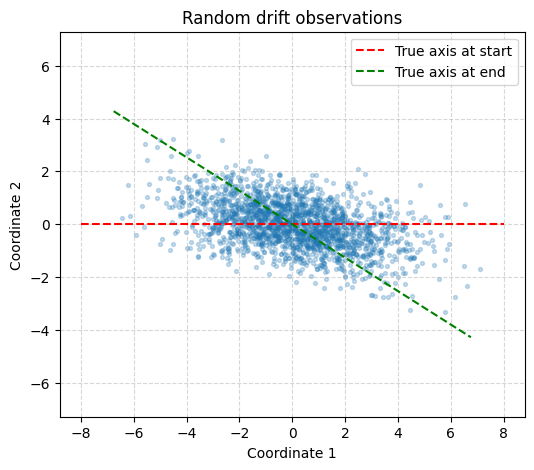

(<Figure size 600x500 with 1 Axes>,
 <Axes: title={'center': 'Random drift observations'}, xlabel='Coordinate 1', ylabel='Coordinate 2'>)

In [12]:
ut.plot_drift_data(X_drift, theta_drift)

# Methods

## 1. Cumulative PCA

All previous observations have equal weight. Once a new observation arrives, the covariance matrix is updated as `previous_avg + (new_value - previous_avg) / n`. 
With known zero population mean, $C_n=n^{-1}\sum_{i=1}^n x_ix_i^\top$ estimates covariance.

NOTE: this is cumulative in its weighting and incremental in its computation, distinct from the truncated SVD-based Incremental PCA of section 3. Section 3 (Incremental PCA) uses the same equal weights, but updates a truncated SVD instead of the covariance matrix.

**Sources.** Recursive sample covariance with equal weights; its estimation error is the classical result of
Anderson (1963). See `docs/literature_review.md`, Sections 2 and 6.


### Stationary data

In [13]:
directions, state = cumulative_pca(X_stationary)
cumulative_stationary_errors = axis_error(directions, truth_stationary)
cumulative_stationary_directions = directions.copy()

#### Single-run measurements

In [14]:
rows = []
errors = cumulative_stationary_errors
label = 'Cumulative PCA'
mean_error = errors[warmup:].mean()
temporal_sd = errors[warmup:].std()
rows.append([label, f'{mean_error:.5f}', f'{temporal_sd:.5f}'])
ut.show_table(['Method', 'Mean error after warm-up', 'Temporal error SD'], rows)

| Method | Mean error after warm-up | Temporal error SD |
| --- | --- | --- |
| Cumulative PCA | 0.00008 | 0.00007 |


#### Repeat with 20 seeds

In [15]:
runs = []
runtimes = []
angles = []
for run_seed in seeds:
    X_run, theta_run, truth_run = stationary_streams[run_seed]
    # Time only the PCA calculation, not generation or evaluation.
    start = time.perf_counter()
    directions, state = cumulative_pca(X_run)
    runtimes.append(time.perf_counter() - start)
    runs.append(axis_error(directions, truth_run))
    angles.append(axis_angle_error(directions, theta_run))
cumulative_stationary_runs = np.array(runs)
cumulative_stationary_runtimes = np.array(runtimes)
cumulative_stationary_angles = np.array(angles)

save_results('Cumulative PCA', 'stationary',
             cumulative_stationary_runs, cumulative_stationary_runtimes,
             angle_runs=cumulative_stationary_angles, settings=benchmark_settings)

Saved Cumulative PCA, stationary, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\baselines\pca_benchmark_results.csv


#### Computational cost

In [16]:
rows = []
runtimes = cumulative_stationary_runtimes
label = 'Cumulative PCA'
rows.append([label, runtimes.mean(), runtimes.min(), runtimes.max(), runtimes.std(ddof=1)])
ut.show_table(['Method', 'Mean seconds', 'Shortest seconds', 'Longest seconds', 'SD seconds'], rows)

| Method | Mean seconds | Shortest seconds | Longest seconds | SD seconds |
| --- | --- | --- | --- | --- |
| Cumulative PCA | 0.16628361500625033 | 0.12036569998599589 | 0.31928230001358315 | 0.06017249683465989 |


#### Repeated-run plot

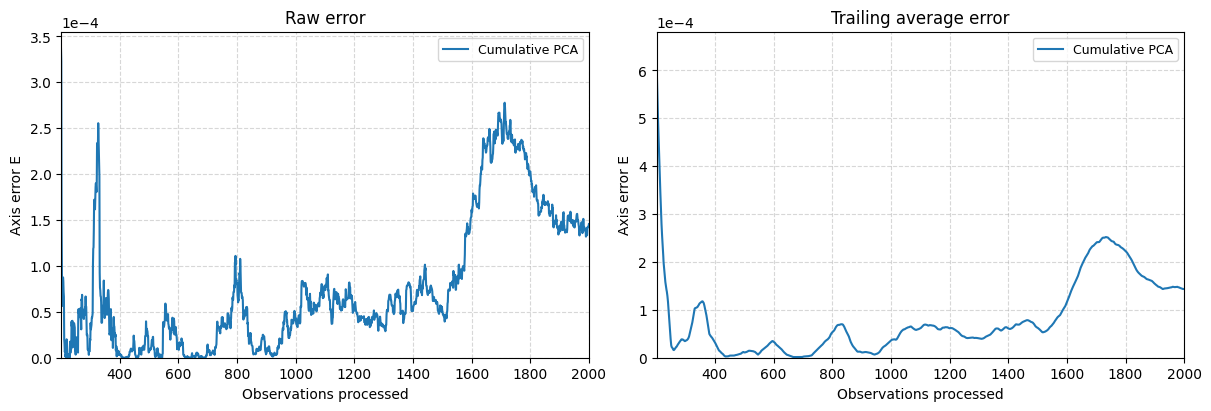

Cumulative PCA cumulative error from observation 1: 0.9979667728579482


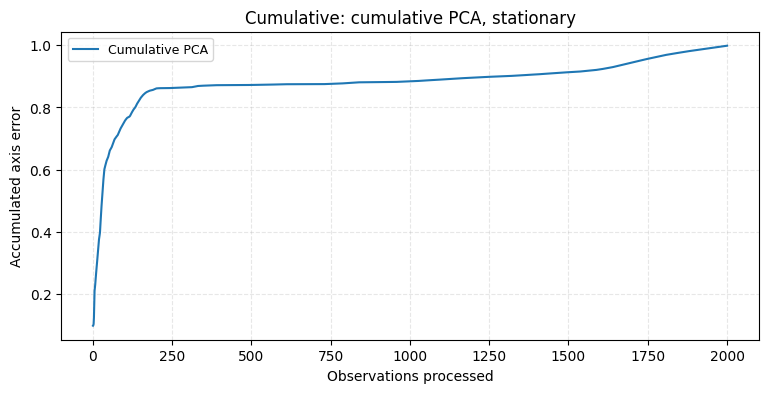

Cumulative PCA stationary angle SD (degrees): 0.3922225550861895


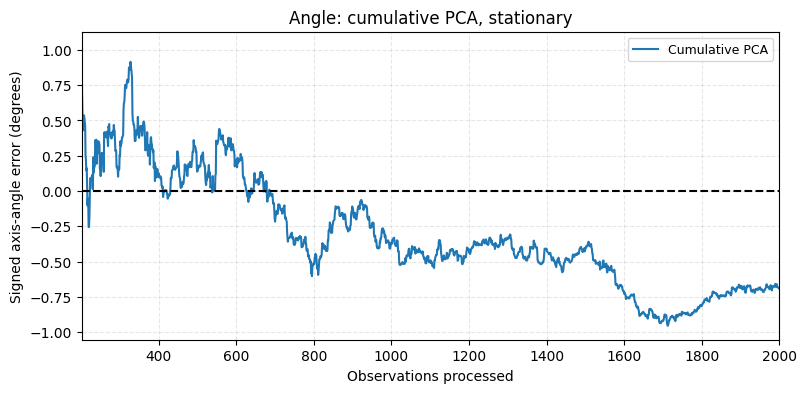

Cumulative PCA mean captured variance after warm-up (%): 90.90284929035059


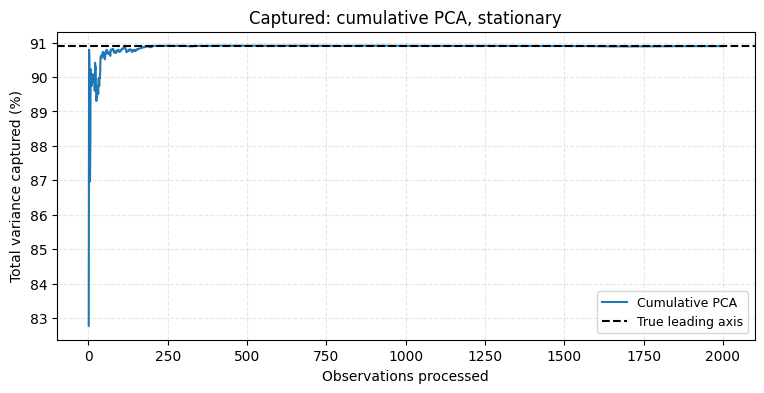

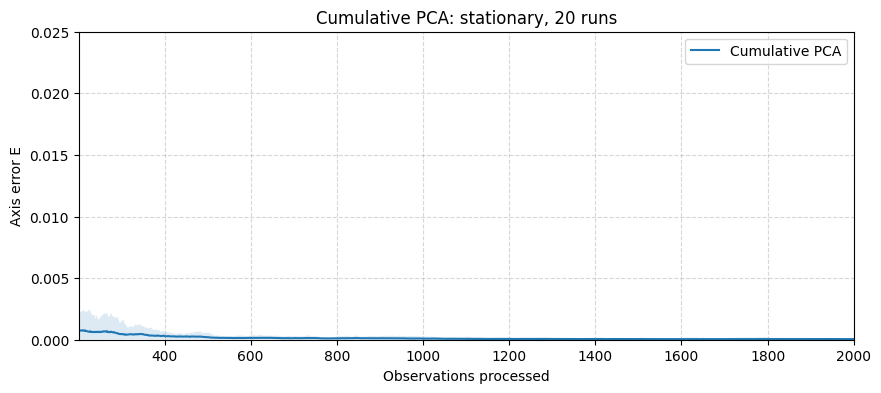

(<Figure size 1000x400 with 1 Axes>,
 <Axes: title={'center': 'Cumulative PCA: stationary, 20 runs'}, xlabel='Observations processed', ylabel='Axis error E'>)

In [17]:
# Raw axis error and its trailing average: one seed, two panels.
ut.plot_stationary_errors(
    [cumulative_stationary_errors], ['Cumulative PCA'],
    warmup, smooth_window
)

# Accumulated raw error from observation 1, including the initial learning period.
total_curves = [np.cumsum(errors) for errors in [cumulative_stationary_errors]]
labels = ['Cumulative PCA']
for total_error, label in zip(total_curves, labels):
    print(label, 'cumulative error from observation 1:', total_error[-1])
ut.plot_cumulative_error(total_curves, labels,
                      'Cumulative: cumulative PCA, stationary')

# Signed angular error in degrees; stationary SD excludes warm-up and any jump.
angle_curves = [axis_angle_error(directions, theta_stationary)
                for directions in [cumulative_stationary_directions]]
labels = ['Cumulative PCA']
for angles, label in zip(angle_curves, labels):
    print(label, 'stationary angle SD (degrees):', angles[warmup:].std())
ut.plot_angle_error(angle_curves, labels,
                 'Angle: cumulative PCA, stationary', warmup)

# Ground-truth population variance captured by the estimated axis, as a percentage.
percent_curves = [100 * (lam1 - (lam1 - lam2) * errors) / (lam1 + lam2)
                  for errors in [cumulative_stationary_errors]]
labels = ['Cumulative PCA']
for percentages, label in zip(percent_curves, labels):
    print(label, 'mean captured variance after warm-up (%):',
          np.nanmean(percentages[warmup:]))
best_percent = 100 * lam1 / (lam1 + lam2)
ut.plot_captured_variance(percent_curves, labels,
                       'Captured: cumulative PCA, stationary', best_percent)

# Across-seed mean raw error and 10th-90th percentile band, not a confidence interval.
ut.plot_repeated_errors(
    [cumulative_stationary_runs], ['Cumulative PCA'],
    'Cumulative PCA: stationary, 20 runs', start=0, warmup=warmup, upper_limit=0.025
)

In [18]:
# Theory (Anderson, 1963): E[E_n] ~ lam1*lam2 / (n*(lam1-lam2)^2) for equal weights
# can be applied here because of the equal weights to past observations assumption
c = lam1 * lam2 / (lam1 - lam2)**2
n = np.arange(warmup + 1, n_samples + 1)
print(f'constant lam1*lam2/(lam1-lam2)^2 = {c:.3f}')
print(f'predicted mean E after warm-up:  {np.mean(c / n):.5f}')
print(f'measured mean E after warm-up:   {cumulative_stationary_runs[:, warmup:].mean():.5f}')

constant lam1*lam2/(lam1-lam2)^2 = 0.123
predicted mean E after warm-up:  0.00016
measured mean E after warm-up:   0.00014


**Plots.**
- The error is of order $10^{-4}$, the smallest of the notebook. Its expected value decreases like
  $\lambda_1\lambda_2/\big(n(\lambda_1-\lambda_2)^2\big)=0.123/n$ (Anderson, 1963): about $6\cdot10^{-4}$ at
  observation $200$ (start of the trailing average), and $0.00016$ averaged over observations $201$–$2000$,
  against $0.00014$ measured over 20 seeds.
- Within one run the error does not decrease smoothly: each observation moves the estimate by only $1/n$, so
  the signed angle drifts slowly ($+0.9^\circ$ to $-0.9^\circ$) instead of oscillating around zero. The bump
  around observation $1700$ is in the data of this seed: it appears for every method.
- Most of the cumulative error comes from the first $\sim200$ observations, where the captured variance also
  reaches its maximum ($90.91\%$). In the 20-run plot the vertical limit ($0.025$) flattens the curve.

#### Repeated-run measurements

In [19]:
rows = []
runs = cumulative_stationary_runs
label = 'Cumulative PCA'
run_means = runs[:, warmup:].mean(axis=1)
mean_error = run_means.mean()
sd_error = run_means.std(ddof=1)
temporal_sd = runs[:, warmup:].std(axis=1).mean()
rows.append([label, f'{mean_error:.5f}', f'{sd_error:.5f}', f'{temporal_sd:.5f}'])
ut.show_table(['Method', 'Mean E', 'SD of run means', 'Mean temporal SD'], rows)

| Method | Mean E | SD of run means | Mean temporal SD |
| --- | --- | --- | --- |
| Cumulative PCA | 0.00014 | 0.00012 | 0.00020 |


### Abrupt-change data

Indices before `switch_step` use `theta0`. Index `switch_step` is the first changed sample and uses `theta1`. On plots it is observation `switch_step + 1`.

In [20]:
directions, state = cumulative_pca(X_abrupt)
cumulative_abrupt_errors = axis_error(directions, truth_abrupt)
cumulative_abrupt_directions = directions.copy()

#### Single-run measurements

In [21]:
rows = []
errors = cumulative_abrupt_errors
label = 'Cumulative PCA'
pre_error = errors[warmup:switch_step].mean()
post_error = errors[switch_step:].mean()
final_error = errors[-warmup:].mean()
delay = recovery_delay(errors, switch_step, threshold=recovery_threshold, window=smooth_window, hold=recovery_hold)
rows.append([label, f'{pre_error:.5f}', f'{post_error:.5f}', f'{final_error:.5f}', delay])
ut.show_table(['Method', 'Pre-change mean E', 'Post-change mean E', 'Final-segment mean E', 'Recovery delay'], rows)

| Method | Pre-change mean E | Post-change mean E | Final-segment mean E | Recovery delay |
| --- | --- | --- | --- | --- |
| Cumulative PCA | 0.00003 | 0.52746 | 0.33730 | nan |


#### Repeat with 20 seeds

Use a new stream for each seed. All baseline method sections use the same seed list. Rows in the saved array are runs, and columns are timesteps.

In [22]:
runs = []
runtimes = []
angles = []
for run_seed in seeds:
    X_run, theta_run, truth_run = abrupt_streams[run_seed]
    # Time only the PCA calculation, not generation or evaluation.
    start = time.perf_counter()
    directions, state = cumulative_pca(X_run)
    runtimes.append(time.perf_counter() - start)
    runs.append(axis_error(directions, truth_run))
    angles.append(axis_angle_error(directions, theta_run))
cumulative_abrupt_runs = np.array(runs)
cumulative_abrupt_runtimes = np.array(runtimes)
cumulative_abrupt_angles = np.array(angles)

save_results('Cumulative PCA', 'abrupt',
             cumulative_abrupt_runs, cumulative_abrupt_runtimes,
             angle_runs=cumulative_abrupt_angles, settings=benchmark_settings)

Saved Cumulative PCA, abrupt, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\baselines\pca_benchmark_results.csv


#### Computational cost

In [23]:
rows = []
runtimes = cumulative_abrupt_runtimes
label = 'Cumulative PCA'
rows.append([label, runtimes.mean(), runtimes.min(), runtimes.max(), runtimes.std(ddof=1)])
ut.show_table(['Method', 'Mean seconds', 'Shortest seconds', 'Longest seconds', 'SD seconds'], rows)

| Method | Mean seconds | Shortest seconds | Longest seconds | SD seconds |
| --- | --- | --- | --- | --- |
| Cumulative PCA | 1.0307629700080725 | 0.3196147999842651 | 1.6313004000112414 | 0.35701045748396587 |


#### Repeated-run plot

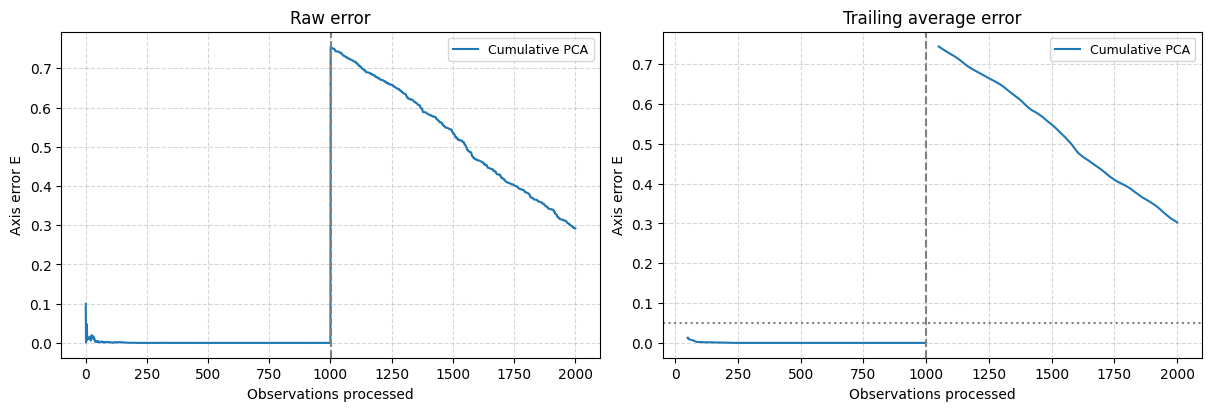

Cumulative PCA cumulative error from observation 1: 528.3397214716218


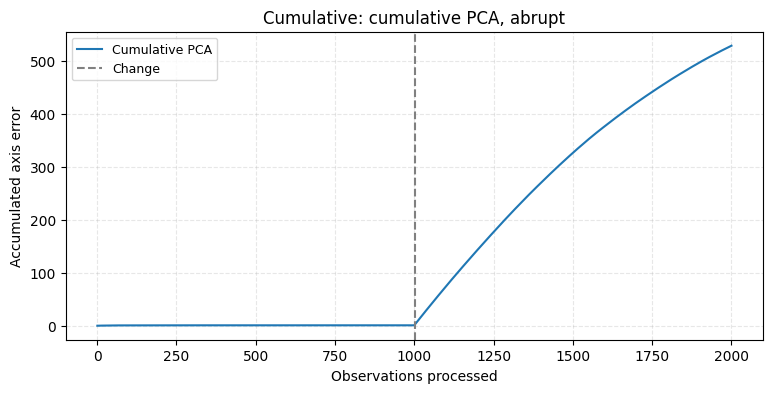

Cumulative PCA stationary angle SD (degrees): 0.3043935485034359


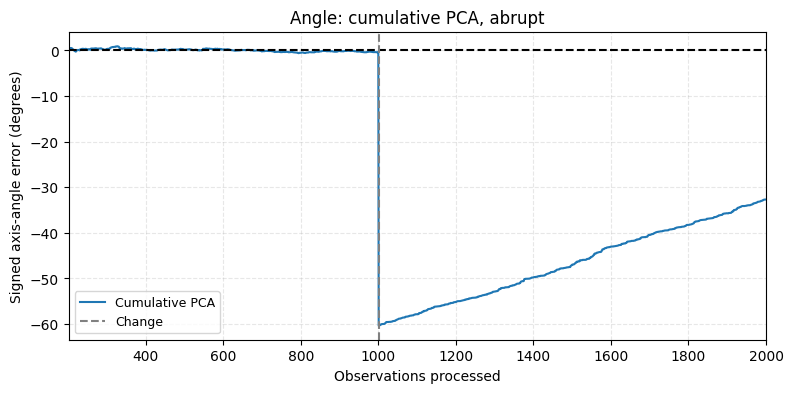

Cumulative PCA mean captured variance after warm-up (%): 66.93276953131583


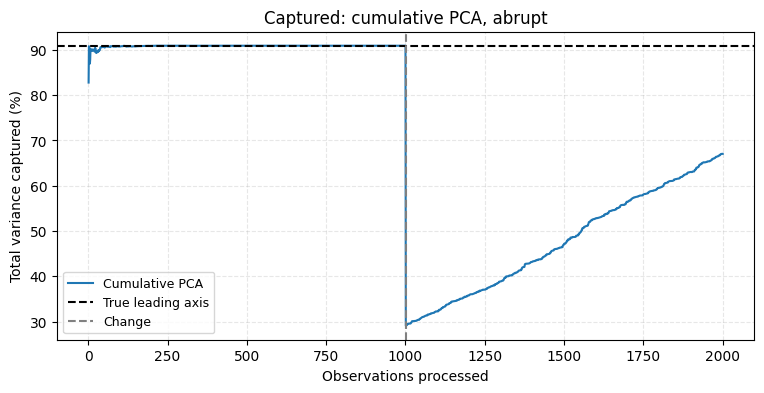

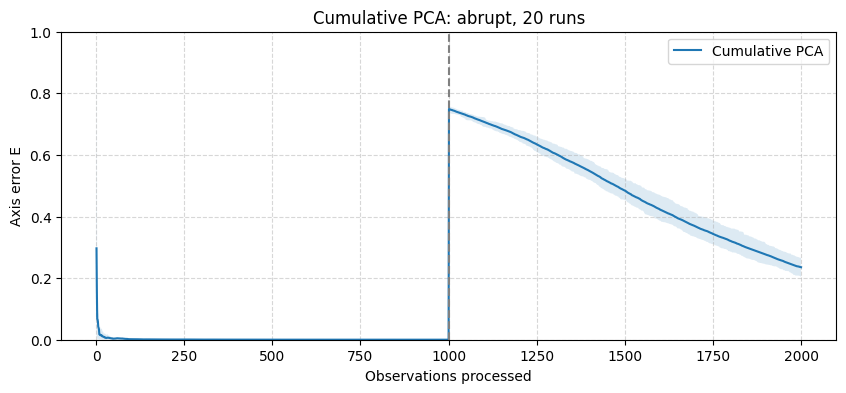

(<Figure size 1000x400 with 1 Axes>,
 <Axes: title={'center': 'Cumulative PCA: abrupt, 20 runs'}, xlabel='Observations processed', ylabel='Axis error E'>)

In [24]:
# Raw axis error and its trailing average: one seed, two panels.
ut.plot_abrupt_errors(
    [cumulative_abrupt_errors], ['Cumulative PCA'],
    switch_step, smooth_window, recovery_threshold, recovery_hold
)

# Accumulated raw error from observation 1, including the initial learning period.
total_curves = [np.cumsum(errors) for errors in [cumulative_abrupt_errors]]
labels = ['Cumulative PCA']
for total_error, label in zip(total_curves, labels):
    print(label, 'cumulative error from observation 1:', total_error[-1])
ut.plot_cumulative_error(total_curves, labels,
                      'Cumulative: cumulative PCA, abrupt', switch_step=switch_step)

# Signed angular error in degrees; stationary SD excludes warm-up and any jump.
angle_curves = [axis_angle_error(directions, theta_abrupt)
                for directions in [cumulative_abrupt_directions]]
labels = ['Cumulative PCA']
for angles, label in zip(angle_curves, labels):
    print(label, 'stationary angle SD (degrees):', angles[warmup:switch_step].std())
ut.plot_angle_error(angle_curves, labels,
                 'Angle: cumulative PCA, abrupt', warmup, switch_step=switch_step)

# Ground-truth population variance captured by the estimated axis, as a percentage.
percent_curves = [100 * (lam1 - (lam1 - lam2) * errors) / (lam1 + lam2)
                  for errors in [cumulative_abrupt_errors]]
labels = ['Cumulative PCA']
for percentages, label in zip(percent_curves, labels):
    print(label, 'mean captured variance after warm-up (%):',
          np.nanmean(percentages[warmup:]))
best_percent = 100 * lam1 / (lam1 + lam2)
ut.plot_captured_variance(percent_curves, labels,
                       'Captured: cumulative PCA, abrupt', best_percent, switch_step=switch_step)

# Across-seed mean raw error and 10th-90th percentile band, not a confidence interval.
ut.plot_repeated_errors(
    [cumulative_abrupt_runs], ['Cumulative PCA'],
    'Cumulative PCA: abrupt, 20 runs', start=0, switch_step=switch_step, upper_limit=1
)

**Plots.**
- Previous to the change, the error is extremely low, with a sharp spike at the beginning (just like the previous stationary regime); at the change the error jumps to $\sin^2 60^\circ=0.75$ (the estimate is still at around 0 and hasn't catched up) and then decreases only slowly: the trailing average
  never reaches the threshold (though it shows a clear downwards trend).
- The angle goes from $-60^\circ$ to about $-32^\circ$ at the end of the stream, approaching the $30^\circ$ of an
  equal mix of the two regimes; the captured variance falls to $\sim30\%$ and recovers only to $\sim67\%$.
- The 20-run band is narrow: after the change the error is set by the weights of the two regimes, not by noise.

#### Repeated-run measurements

Read the median recovery delay together with the recovered-run count: the median includes only runs that recovered.

In [25]:
rows = []
runs = cumulative_abrupt_runs
label = 'Cumulative PCA'
pre_means = runs[:, warmup:switch_step].mean(axis=1)
post_means = runs[:, switch_step:].mean(axis=1)
final_means = runs[:, -warmup:].mean(axis=1)
delays = []
for errors in runs:
    delays.append(recovery_delay(errors, switch_step, threshold=recovery_threshold, window=smooth_window, hold=recovery_hold))
delays = np.array(delays)
recovered = np.isfinite(delays)
median_delay = 'Not confirmed'
if recovered.any():
    median_delay = float(np.median(delays[recovered]))
rows.append([label,
             f'{pre_means.mean():.5f} +/- {pre_means.std(ddof=1):.5f}',
             f'{post_means.mean():.5f} +/- {post_means.std(ddof=1):.5f}',
             f'{final_means.mean():.5f} +/- {final_means.std(ddof=1):.5f}',
             f'{recovered.sum()}/{len(delays)}', median_delay])
ut.show_table(['Method', 'Pre-change E: mean +/- SD', 'Post-change E: mean +/- SD', 'Final E: mean +/- SD', 'Recovered runs', 'Median delay'], rows)

| Method | Pre-change E: mean +/- SD | Post-change E: mean +/- SD | Final E: mean +/- SD | Recovered runs | Median delay |
| --- | --- | --- | --- | --- | --- |
| Cumulative PCA | 0.00024 +/- 0.00025 | 0.48821 +/- 0.02267 | 0.27634 +/- 0.02875 | 0/20 | Not confirmed |


No seed recovers (0/20), so there is no delay to report ("Not
confirmed"): at the end of the stream the error is about five times the threshold ($0.276$ against $0.05$),
and the estimated axis is still about $30^\circ$ from the new direction. With equal weights the new regime
would dominate only after roughly $2500$ post-change observations, despite the lax angle requirement for recovery.

### Smooth rotation data

In [26]:
directions, state = cumulative_pca(X_rotation)
cumulative_rotation_errors = axis_error(directions, truth_rotation)
cumulative_rotation_directions = directions.copy()

#### Single-run measurements

In [27]:
rows = []
errors = cumulative_rotation_errors
label = 'Cumulative PCA'
mean_error = errors[warmup:].mean()
temporal_sd = errors[warmup:].std()
rows.append([label, f'{mean_error:.5f}', f'{temporal_sd:.5f}'])
ut.show_table(['Method', 'Mean error after warm-up', 'Temporal error SD'], rows)

| Method | Mean error after warm-up | Temporal error SD |
| --- | --- | --- |
| Cumulative PCA | 0.30528 | 0.22353 |


#### Repeat with 20 seeds

In [28]:
runs = []
runtimes = []
angles = []
for run_seed in seeds:
    X_run, theta_run, truth_run = rotation_streams[run_seed]
    # Time only the PCA calculation, not generation or evaluation.
    start = time.perf_counter()
    directions, state = cumulative_pca(X_run)
    runtimes.append(time.perf_counter() - start)
    runs.append(axis_error(directions, truth_run))
    angles.append(axis_angle_error(directions, theta_run))
cumulative_rotation_runs = np.array(runs)
cumulative_rotation_runtimes = np.array(runtimes)
cumulative_rotation_angles = np.array(angles)

save_results('Cumulative PCA', 'rotation',
             cumulative_rotation_runs, cumulative_rotation_runtimes,
             angle_runs=cumulative_rotation_angles, settings=rotation_settings)

Saved Cumulative PCA, rotation, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\baselines\pca_rotation_results_omega=0.001_dt=1.csv


#### Computational cost

In [29]:
rows = []
runtimes = cumulative_rotation_runtimes
label = 'Cumulative PCA'
rows.append([label, runtimes.mean(), runtimes.min(), runtimes.max(), runtimes.std(ddof=1)])
ut.show_table(['Method', 'Mean seconds', 'Shortest seconds', 'Longest seconds', 'SD seconds'], rows)

| Method | Mean seconds | Shortest seconds | Longest seconds | SD seconds |
| --- | --- | --- | --- | --- |
| Cumulative PCA | 0.3292195350019028 | 0.10124899999937043 | 2.211135599995032 | 0.4978247190719236 |


#### Repeated-run plot

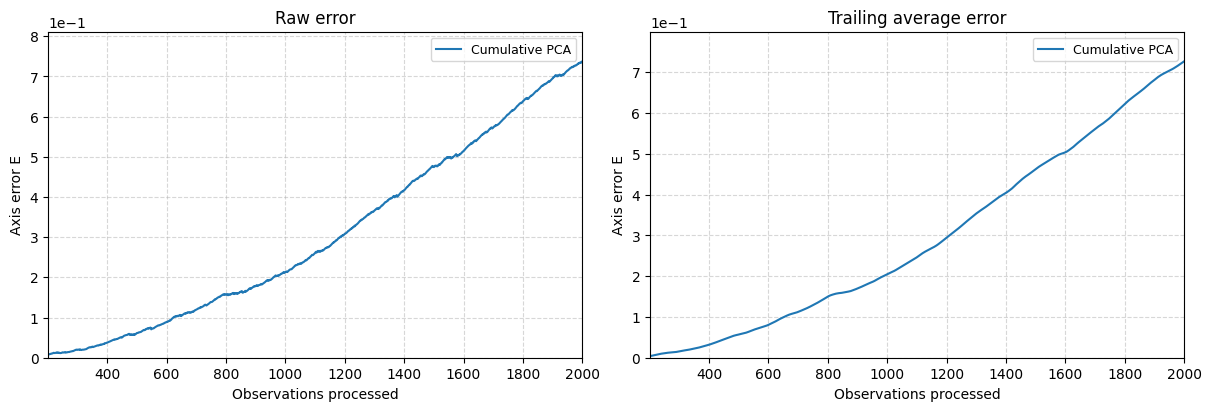

Cumulative PCA cumulative error from observation 1: 550.2800322481896


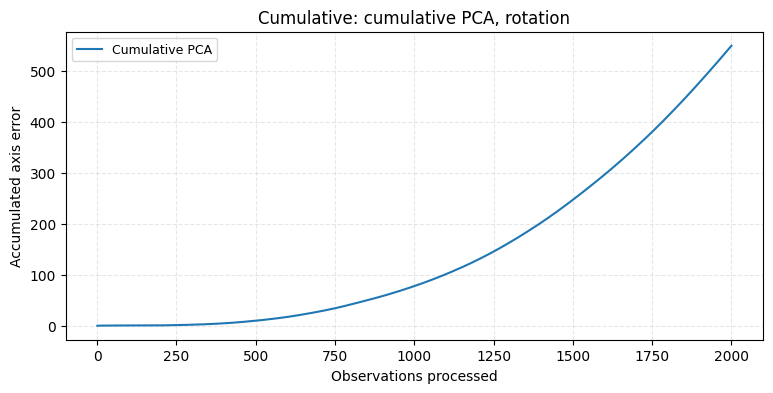

Cumulative PCA tracking angle-error SD (degrees): 15.411315102498008


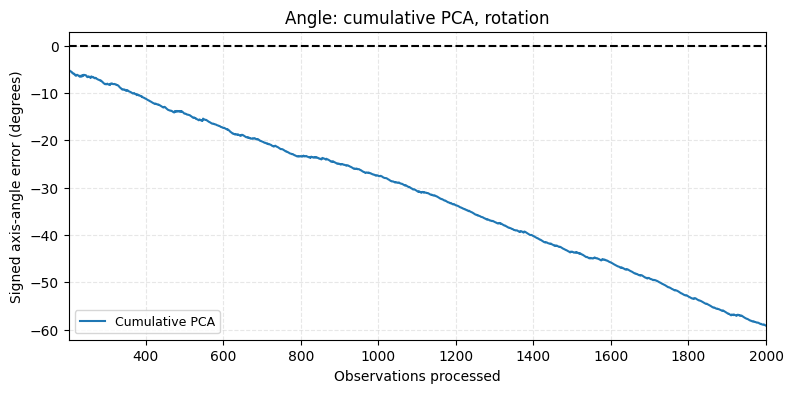

Cumulative PCA mean captured variance after warm-up (%): 65.93176450164378


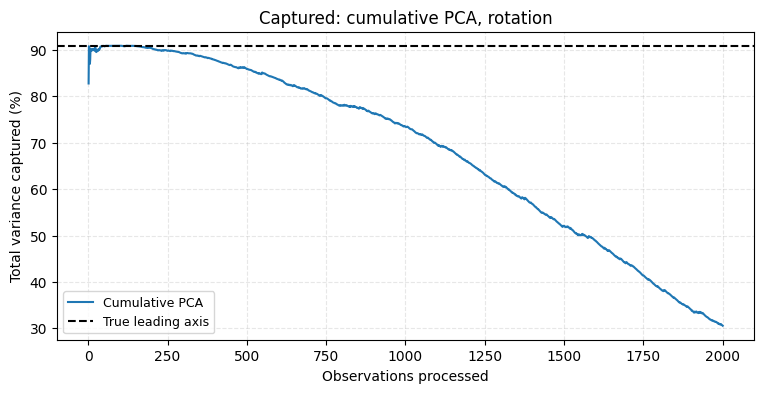

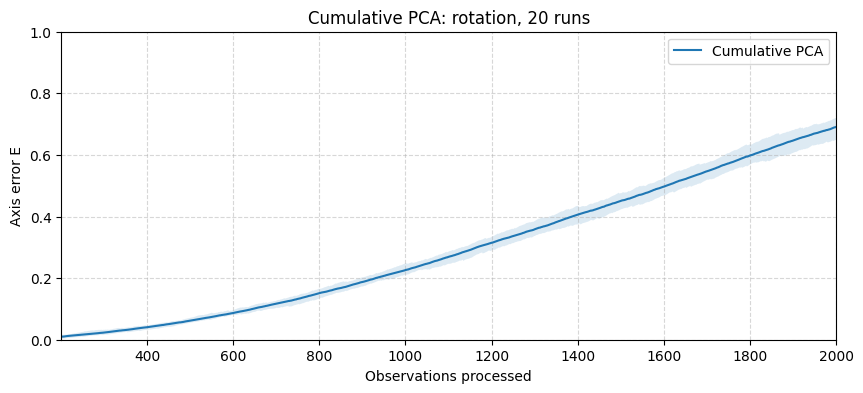

(<Figure size 1000x400 with 1 Axes>,
 <Axes: title={'center': 'Cumulative PCA: rotation, 20 runs'}, xlabel='Observations processed', ylabel='Axis error E'>)

In [30]:
# Raw axis error and its trailing average: one seed, two panels.
ut.plot_stationary_errors(
    [cumulative_rotation_errors], ['Cumulative PCA'],
    warmup, smooth_window
)

# Accumulated raw error from observation 1, including the initial learning period.
total_curves = [np.cumsum(errors) for errors in [cumulative_rotation_errors]]
labels = ['Cumulative PCA']
for total_error, label in zip(total_curves, labels):
    print(label, 'cumulative error from observation 1:', total_error[-1])
ut.plot_cumulative_error(total_curves, labels,
                      'Cumulative: cumulative PCA, rotation')

# Signed angular tracking error in degrees; SD excludes warm-up.
angle_curves = [axis_angle_error(directions, theta_rotation)
                for directions in [cumulative_rotation_directions]]
labels = ['Cumulative PCA']
for angles, label in zip(angle_curves, labels):
    print(label, 'tracking angle-error SD (degrees):', angles[warmup:].std())
ut.plot_angle_error(angle_curves, labels,
                 'Angle: cumulative PCA, rotation', warmup)

# Ground-truth population variance captured by the estimated axis, as a percentage.
percent_curves = [100 * (lam1 - (lam1 - lam2) * errors) / (lam1 + lam2)
                  for errors in [cumulative_rotation_errors]]
labels = ['Cumulative PCA']
for percentages, label in zip(percent_curves, labels):
    print(label, 'mean captured variance after warm-up (%):',
          np.nanmean(percentages[warmup:]))
best_percent = 100 * lam1 / (lam1 + lam2)
ut.plot_captured_variance(percent_curves, labels,
                       'Captured: cumulative PCA, rotation', best_percent)

# Across-seed mean raw error and 10th-90th percentile band, not a confidence interval.
ut.plot_repeated_errors(
    [cumulative_rotation_runs], ['Cumulative PCA'],
    'Cumulative PCA: rotation, 20 runs', start=0, warmup=warmup, upper_limit=1
)

**Plots.**
- In smooth rotation (and without the presence of external errors) the error of cumulative PCA grows linearly: equal weights estimate the axis of the average covariance, which lies halfway between the first and the
current direction, about $\omega n/2$
  behind the true one ($57^\circ$ at $n=2000$; $-59^\circ$ measured). The error reaches $\sim0.7$ and the captured
  variance falls to $\sim30\%$. Conversely, the captured variance falls steadily from almost the maximum to about $33%$ (though it's steadily moving downwards)
- The cumulative error is convex (it grows faster and faster), as mentioned before. The narrow 20-run band shows that this is a
  deterministic lag, not noise.
- The repeated runs demonstrate a similar mean error behaviour to the seed 0 experiment, with very little variation; this is because the variation is mostly dependent on $\omega$ and $n$ and not on the data itself.

#### Repeated-run measurements

In [31]:
rows = []
runs = cumulative_rotation_runs
label = 'Cumulative PCA'
run_means = runs[:, warmup:].mean(axis=1)
mean_error = run_means.mean()
sd_error = run_means.std(ddof=1)
temporal_sd = runs[:, warmup:].std(axis=1).mean()
rows.append([label, f'{mean_error:.5f}', f'{sd_error:.5f}', f'{temporal_sd:.5f}'])
ut.show_table(['Method', 'Mean E', 'SD of run means', 'Mean temporal SD'], rows)

| Method | Mean E | SD of run means | Mean temporal SD |
| --- | --- | --- | --- |
| Cumulative PCA | 0.29627 | 0.01304 | 0.20864 |


### Random drift data

In [32]:
directions, state = cumulative_pca(X_drift)
cumulative_drift_errors = axis_error(directions, truth_drift)
cumulative_drift_directions = directions.copy()

#### Single-run measurements

In [33]:
rows = []
errors = cumulative_drift_errors
label = 'Cumulative PCA'
mean_error = errors[warmup:].mean()
temporal_sd = errors[warmup:].std()
rows.append([label, f'{mean_error:.5f}', f'{temporal_sd:.5f}'])
ut.show_table(['Method', 'Mean error after warm-up', 'Temporal error SD'], rows)

| Method | Mean error after warm-up | Temporal error SD |
| --- | --- | --- |
| Cumulative PCA | 0.03610 | 0.04359 |


#### Repeat with 20 seeds

In [34]:
runs = []
runtimes = []
angles = []
for run_seed in seeds:
    X_run, theta_run, truth_run = drift_streams[run_seed]
    # Time only the PCA calculation, not generation or evaluation.
    start = time.perf_counter()
    directions, state = cumulative_pca(X_run)
    runtimes.append(time.perf_counter() - start)
    runs.append(axis_error(directions, truth_run))
    angles.append(axis_angle_error(directions, theta_run))
cumulative_drift_runs = np.array(runs)
cumulative_drift_runtimes = np.array(runtimes)
cumulative_drift_angles = np.array(angles)

save_results('Cumulative PCA', 'drift',
             cumulative_drift_runs, cumulative_drift_runtimes,
             angle_runs=cumulative_drift_angles, settings=drift_settings)

Saved Cumulative PCA, drift, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\baselines\pca_drift_results_Q=0.0001_dt=1.csv


#### Computational cost

In [35]:
rows = []
runtimes = cumulative_drift_runtimes
label = 'Cumulative PCA'
rows.append([label, runtimes.mean(), runtimes.min(), runtimes.max(), runtimes.std(ddof=1)])
ut.show_table(['Method', 'Mean seconds', 'Shortest seconds', 'Longest seconds', 'SD seconds'], rows)

| Method | Mean seconds | Shortest seconds | Longest seconds | SD seconds |
| --- | --- | --- | --- | --- |
| Cumulative PCA | 0.2530326000007335 | 0.11240609997184947 | 0.8877091000322253 | 0.23322007139044656 |


#### Repeated-run plot

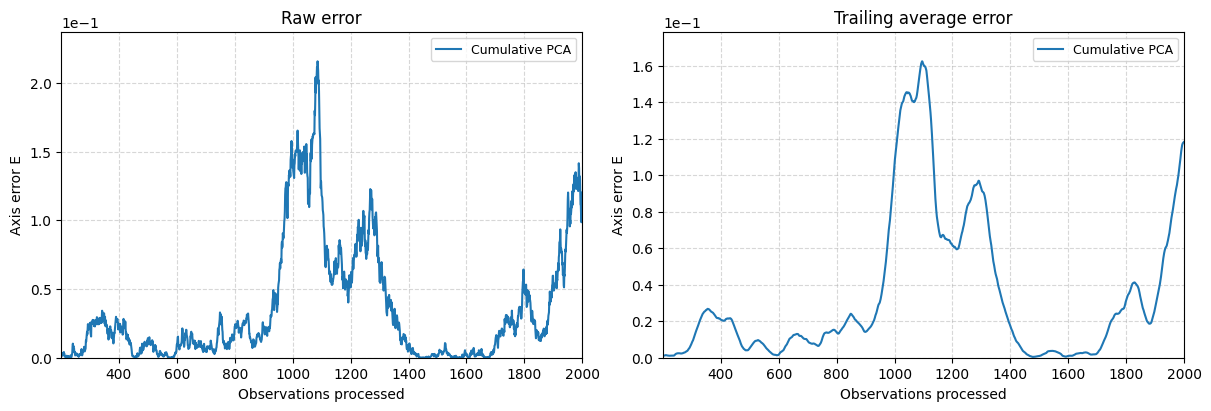

Cumulative PCA cumulative error from observation 1: 66.62187270672491


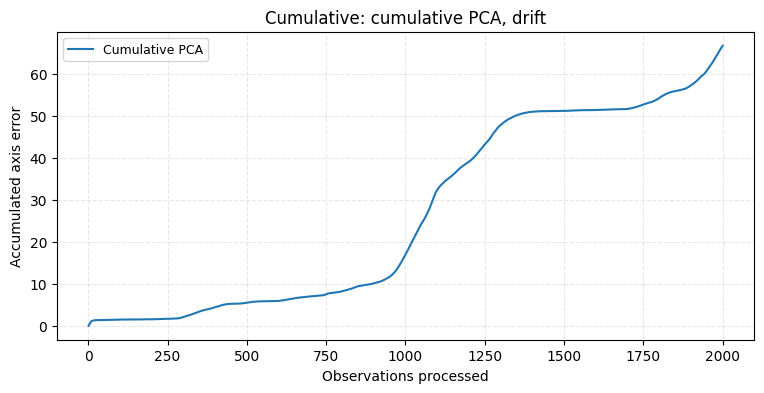

Cumulative PCA tracking angle-error SD (degrees): 6.667020779294183


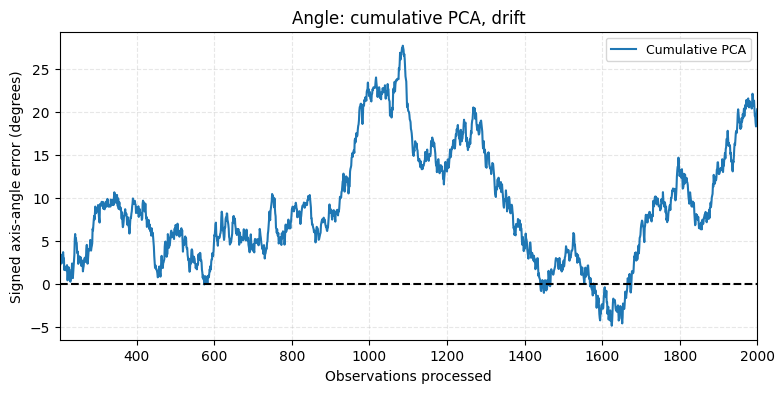

Cumulative PCA mean captured variance after warm-up (%): 87.9554873855357


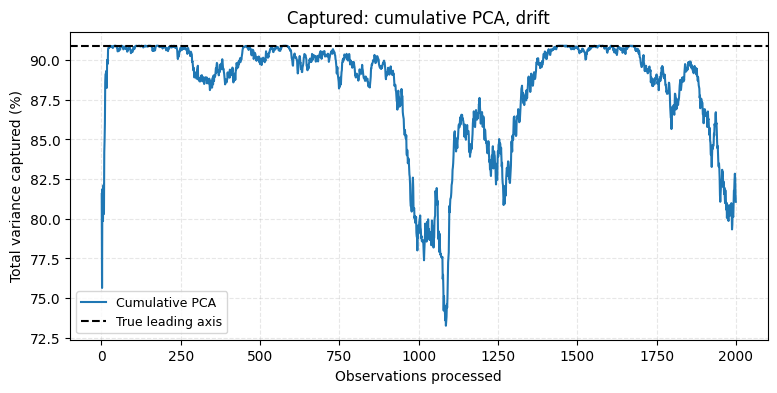

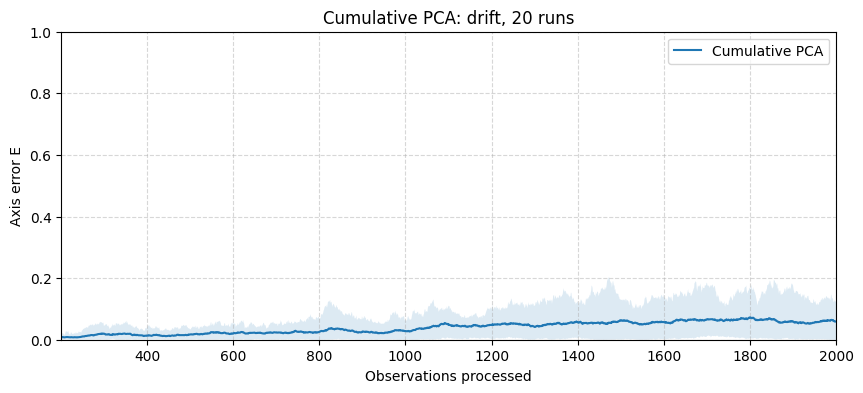

(<Figure size 1000x400 with 1 Axes>,
 <Axes: title={'center': 'Cumulative PCA: drift, 20 runs'}, xlabel='Observations processed', ylabel='Axis error E'>)

In [36]:
# Raw axis error and its trailing average: one seed, two panels.
ut.plot_stationary_errors(
    [cumulative_drift_errors], ['Cumulative PCA'],
    warmup, smooth_window
)

# Accumulated raw error from observation 1, including the initial learning period.
total_curves = [np.cumsum(errors) for errors in [cumulative_drift_errors]]
labels = ['Cumulative PCA']
for total_error, label in zip(total_curves, labels):
    print(label, 'cumulative error from observation 1:', total_error[-1])
ut.plot_cumulative_error(total_curves, labels,
                      'Cumulative: cumulative PCA, drift')

# Signed angular tracking error in degrees; SD excludes warm-up.
angle_curves = [axis_angle_error(directions, theta_drift)
                for directions in [cumulative_drift_directions]]
labels = ['Cumulative PCA']
for angles, label in zip(angle_curves, labels):
    print(label, 'tracking angle-error SD (degrees):', angles[warmup:].std())
ut.plot_angle_error(angle_curves, labels,
                 'Angle: cumulative PCA, drift', warmup)

# Ground-truth population variance captured by the estimated axis, as a percentage.
percent_curves = [100 * (lam1 - (lam1 - lam2) * errors) / (lam1 + lam2)
                  for errors in [cumulative_drift_errors]]
labels = ['Cumulative PCA']
for percentages, label in zip(percent_curves, labels):
    print(label, 'mean captured variance after warm-up (%):',
          np.nanmean(percentages[warmup:]))
best_percent = 100 * lam1 / (lam1 + lam2)
ut.plot_captured_variance(percent_curves, labels,
                       'Captured: cumulative PCA, drift', best_percent)

# Across-seed mean raw error and 10th-90th percentile band, not a confidence interval.
ut.plot_repeated_errors(
    [cumulative_drift_runs], ['Cumulative PCA'],
    'Cumulative PCA: drift, 20 runs', start=0, warmup=warmup, upper_limit=1
)

**Plots.**
- The error follows the path of the drift: it is large when the direction has moved far from its long-run
  average (around observations $1000$–$1300$ and at the end in this seed, up to $27^\circ$) and small when it
  comes back. It is still a quite low error (about $0.2$) for this specific set of data, but exhibits no informative trends.
- The signed error plot wanders as well; there's no systematic lag, unlike the smooth rotation regime.
- Unlike abrupt and rotation regimes, the band is wide, up to about 0.15. Each seed follows a different path, so the error depends on how far that particular path wanders.

#### Repeated-run measurements

In [37]:
rows = []
runs = cumulative_drift_runs
label = 'Cumulative PCA'
run_means = runs[:, warmup:].mean(axis=1)
mean_error = run_means.mean()
sd_error = run_means.std(ddof=1)
temporal_sd = runs[:, warmup:].std(axis=1).mean()
rows.append([label, f'{mean_error:.5f}', f'{sd_error:.5f}', f'{temporal_sd:.5f}'])
ut.show_table(['Method', 'Mean E', 'SD of run means', 'Mean temporal SD'], rows)

| Method | Mean E | SD of run means | Mean temporal SD |
| --- | --- | --- | --- |
| Cumulative PCA | 0.03948 | 0.02571 | 0.04060 |


## 2. Fixed-gain forgetting PCA

The update is `C = (1-alpha)*C + alpha*outer(x, x)`, where `alpha` is the parameter representing the gain itself.

- `(1-alpha)` represents how much the older covariance estimate remains. 
- `alpha` represents the contribution of the current observation.

As updates continue, an observation's weight decreases exponentially, indeed we can write the geometric formula as :

$$
C_n = \sum_{i=1}^{n} \alpha (1-\alpha)^{n-i} x_i x_i^\top
$$
so an observation of age $k$ has weight $\alpha(1-\alpha)^k$, which decreases geometrically (**exponentially
weighted** covariance). It's the same recursion as cumulative PCA (section 1), with one difference. There the gain was αₙ = 1/n, so it kept shrinking.

Small gains generally produce smoother estimations but slower adaptations, because they tend to give less importance to newer observations, so that when a new, sudden spike appears, the direction is not immediately updated towards that direction. Conversely, larger gains tend to show quicker adaptation to new direction changes, but they tend to fluctuate a lot more and may not prove as stable. 

**Sources.** Eq. (1) of the thesis proposal; exponential forgetting is the classical tool of recursive estimation for
tracking (Ljung and Gunnarsson, 1990). See `docs/literature_review.md`, Section 2.

### Stationary data

In [39]:
forgetting_stationary_errors = {}
forgetting_stationary_directions = {}
for alpha in gains:
    directions, covariance = forgetting_pca(X_stationary, alpha)
    forgetting_stationary_directions[alpha] = directions.copy()
    errors = axis_error(directions, truth_stationary)
    forgetting_stationary_errors[alpha] = errors

#### Single-run measurements

In [40]:
rows = []
for alpha in gains:
    errors = forgetting_stationary_errors[alpha]
    label = f'alpha={alpha:g}'
    mean_error = errors[warmup:].mean()
    temporal_sd = errors[warmup:].std()
    rows.append([label, f'{mean_error:.5f}', f'{temporal_sd:.5f}'])
ut.show_table(['Method', 'Mean error after warm-up', 'Temporal error SD'], rows)

| Method | Mean error after warm-up | Temporal error SD |
| --- | --- | --- |
| alpha=0.005 | 0.00040 | 0.00068 |
| alpha=0.02 | 0.00129 | 0.00201 |
| alpha=0.1 | 0.00679 | 0.01040 |


#### Repeat with 20 seeds

In [41]:
forgetting_stationary_runs = {}
forgetting_stationary_runtimes = {}
forgetting_stationary_angles = {}
for alpha in gains:
    runs = []
    runtimes = []
    angles = []
    for run_seed in seeds:
        X_run, theta_run, truth_run = stationary_streams[run_seed]
        # Time only the PCA calculation, not generation or evaluation.
        start = time.perf_counter()
        directions, covariance = forgetting_pca(X_run, alpha)
        runtimes.append(time.perf_counter() - start)
        runs.append(axis_error(directions, truth_run))
        angles.append(axis_angle_error(directions, theta_run))
    forgetting_stationary_runs[alpha] = np.array(runs)
    forgetting_stationary_runtimes[alpha] = np.array(runtimes)
    forgetting_stationary_angles[alpha] = np.array(angles)
    # Select this gain's arrays, rather than passing the entire dictionary.
    save_results('Forgetting PCA', 'stationary',
                 forgetting_stationary_runs[alpha], forgetting_stationary_runtimes[alpha],
                 alpha=alpha, angle_runs=forgetting_stationary_angles[alpha], settings=benchmark_settings)

Saved Forgetting PCA, stationary, alpha=0.005 to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\baselines\pca_benchmark_results.csv
Saved Forgetting PCA, stationary, alpha=0.02 to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\baselines\pca_benchmark_results.csv
Saved Forgetting PCA, stationary, alpha=0.1 to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\baselines\pca_benchmark_results.csv


#### Computational cost

In [42]:
rows = []
for alpha in gains:
    runtimes = forgetting_stationary_runtimes[alpha]
    label = f'alpha={alpha:g}'
    rows.append([label, runtimes.mean(), runtimes.min(), runtimes.max(), runtimes.std(ddof=1)])
ut.show_table(['Method', 'Mean seconds', 'Shortest seconds', 'Longest seconds', 'SD seconds'], rows)

| Method | Mean seconds | Shortest seconds | Longest seconds | SD seconds |
| --- | --- | --- | --- | --- |
| alpha=0.005 | 0.3105665149865672 | 0.11023229995043948 | 0.9336229999898933 | 0.22479057417881734 |
| alpha=0.02 | 0.2445921700040344 | 0.11875219998182729 | 0.7008551000035368 | 0.1480420869679454 |
| alpha=0.1 | 0.3898684699990554 | 0.1335696000023745 | 1.062587100022938 | 0.2513027165706735 |


#### Repeated-run plot

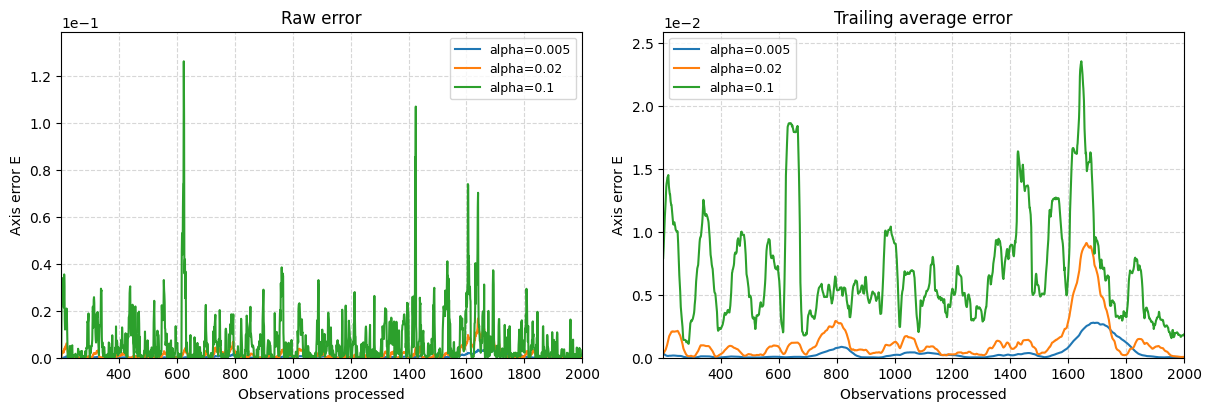

alpha=0.005 cumulative error from observation 1: 1.5416725751971274
alpha=0.02 cumulative error from observation 1: 3.0935831845391544
alpha=0.1 cumulative error from observation 1: 13.946166111630584


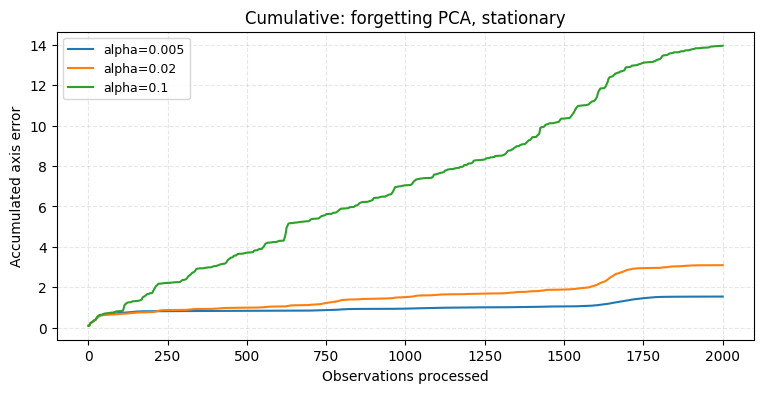

alpha=0.005 stationary angle SD (degrees): 0.8320758596886747
alpha=0.02 stationary angle SD (degrees): 1.8824936311171754
alpha=0.1 stationary angle SD (degrees): 4.657826503059915


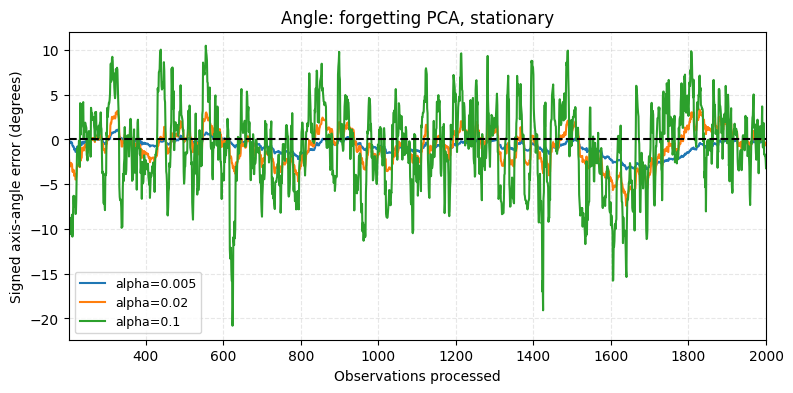

alpha=0.005 mean captured variance after warm-up (%): 90.87612401269193
alpha=0.02 mean captured variance after warm-up (%): 90.80340617842239
alpha=0.1 mean captured variance after warm-up (%): 90.35314105674013


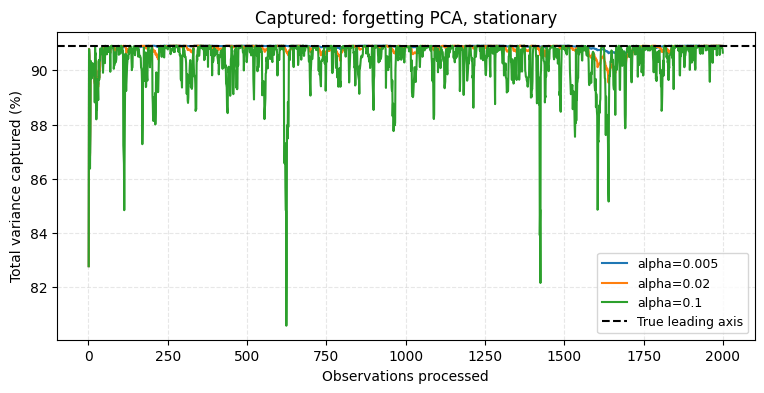

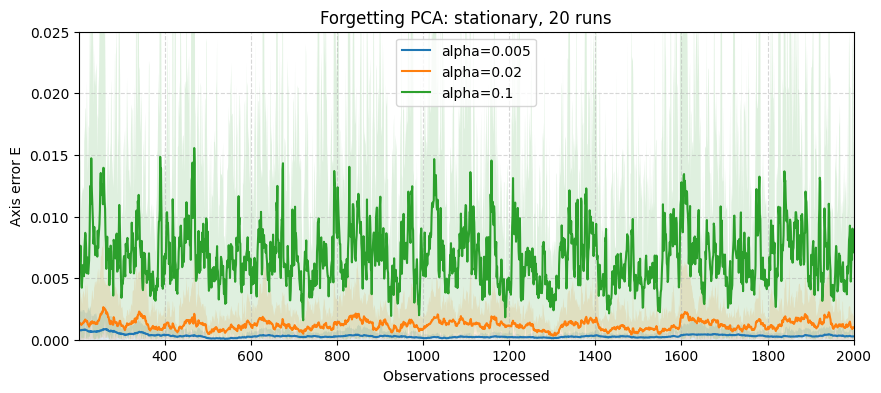

(<Figure size 1000x400 with 1 Axes>,
 <Axes: title={'center': 'Forgetting PCA: stationary, 20 runs'}, xlabel='Observations processed', ylabel='Axis error E'>)

In [43]:
# Raw axis error and its trailing average: one seed, two panels.
ut.plot_stationary_errors(
    [forgetting_stationary_errors[alpha] for alpha in gains],
    [f'alpha={alpha:g}' for alpha in gains],
    warmup, smooth_window
)

# Accumulated raw error from observation 1, including the initial learning period.
total_curves = [np.cumsum(errors) for errors in [forgetting_stationary_errors[alpha] for alpha in gains]]
labels = [f'alpha={alpha:g}' for alpha in gains]
for total_error, label in zip(total_curves, labels):
    print(label, 'cumulative error from observation 1:', total_error[-1])
ut.plot_cumulative_error(total_curves, labels,
                      'Cumulative: forgetting PCA, stationary')

# Signed angular error in degrees; stationary SD excludes warm-up and any jump.
angle_curves = [axis_angle_error(directions, theta_stationary)
                for directions in [forgetting_stationary_directions[alpha] for alpha in gains]]
labels = [f'alpha={alpha:g}' for alpha in gains]
for angles, label in zip(angle_curves, labels):
    print(label, 'stationary angle SD (degrees):', angles[warmup:].std())
ut.plot_angle_error(angle_curves, labels,
                 'Angle: forgetting PCA, stationary', warmup)

# Ground-truth population variance captured by the estimated axis, as a percentage.
percent_curves = [100 * (lam1 - (lam1 - lam2) * errors) / (lam1 + lam2)
                  for errors in [forgetting_stationary_errors[alpha] for alpha in gains]]
labels = [f'alpha={alpha:g}' for alpha in gains]
for percentages, label in zip(percent_curves, labels):
    print(label, 'mean captured variance after warm-up (%):',
          np.nanmean(percentages[warmup:]))
best_percent = 100 * lam1 / (lam1 + lam2)
ut.plot_captured_variance(percent_curves, labels,
                       'Captured: forgetting PCA, stationary', best_percent)

# Across-seed mean raw error and 10th-90th percentile band, not a confidence interval.
ut.plot_repeated_errors(
    [forgetting_stationary_runs[alpha] for alpha in gains], [f'alpha={alpha:g}' for alpha in gains],
    'Forgetting PCA: stationary, 20 runs', start=0, warmup=warmup, upper_limit=0.025
)

**Plots.**
- The noise grows with $\alpha$: $\alpha=0.1$ is very irregular and has isolated spikes, while
  $\alpha=0.005$ is smooth and with a much lower error scale. The captured variance stays within $\sim1\%$ of the maximum except at those spikes.
- The bump around observation $1600$–$1700$ appears for every gain (and in cumulative PCA): it comes from the data.
- The cumulative error grows linearly, with a slope that grows with $\alpha$. In the 20-run plot the band of
  $\alpha=0.1$ goes beyond the vertical limit.
- For the signed angle error, as with cumulative PCA, the error oscillates around 0, with $\alpha=0.1$ exhibiting the strongest fluctuations.

#### Repeated-run measurements

In [44]:
rows = []
for alpha in gains:
    runs = forgetting_stationary_runs[alpha]
    label = f'alpha={alpha:g}'
    run_means = runs[:, warmup:].mean(axis=1)
    mean_error = run_means.mean()
    sd_error = run_means.std(ddof=1)
    temporal_sd = runs[:, warmup:].std(axis=1).mean()
    rows.append([label, f'{mean_error:.5f}', f'{sd_error:.5f}', f'{temporal_sd:.5f}'])
ut.show_table(['Method', 'Mean E', 'SD of run means', 'Mean temporal SD'], rows)

| Method | Mean E | SD of run means | Mean temporal SD |
| --- | --- | --- | --- |
| alpha=0.005 | 0.00030 | 0.00012 | 0.00041 |
| alpha=0.02 | 0.00121 | 0.00036 | 0.00167 |
| alpha=0.1 | 0.00680 | 0.00083 | 0.01044 |


### Abrupt-change data

In [45]:
forgetting_abrupt_errors = {}
forgetting_abrupt_directions = {}
for alpha in gains:
    directions, covariance = forgetting_pca(X_abrupt, alpha)
    forgetting_abrupt_directions[alpha] = directions.copy()
    errors = axis_error(directions, truth_abrupt)
    forgetting_abrupt_errors[alpha] = errors

#### Single-run measurements

In [46]:
rows = []
for alpha in gains:
    errors = forgetting_abrupt_errors[alpha]
    label = f'alpha={alpha:g}'
    pre_error = errors[warmup:switch_step].mean()
    post_error = errors[switch_step:].mean()
    final_error = errors[-warmup:].mean()
    delay = recovery_delay(errors, switch_step, threshold=recovery_threshold, window=smooth_window, hold=recovery_hold)
    rows.append([label, f'{pre_error:.5f}', f'{post_error:.5f}', f'{final_error:.5f}', delay])
ut.show_table(['Method', 'Pre-change mean E', 'Post-change mean E', 'Final-segment mean E', 'Recovery delay'], rows)

| Method | Pre-change mean E | Post-change mean E | Final-segment mean E | Recovery delay |
| --- | --- | --- | --- | --- |
| alpha=0.005 | 0.00016 | 0.10290 | 0.00027 | 305.0 |
| alpha=0.02 | 0.00093 | 0.02726 | 0.00067 | 97.0 |
| alpha=0.1 | 0.00666 | 0.01090 | 0.00338 | 53.0 |


#### Repeat with 20 seeds

In [47]:
forgetting_abrupt_runs = {}
forgetting_abrupt_runtimes = {}
forgetting_abrupt_angles = {}
for alpha in gains:
    runs = []
    runtimes = []
    angles = []
    for run_seed in seeds:
        X_run, theta_run, truth_run = abrupt_streams[run_seed]
        # Time only the PCA calculation, not generation or evaluation.
        start = time.perf_counter()
        directions, covariance = forgetting_pca(X_run, alpha)
        runtimes.append(time.perf_counter() - start)
        runs.append(axis_error(directions, truth_run))
        angles.append(axis_angle_error(directions, theta_run))
    forgetting_abrupt_runs[alpha] = np.array(runs)
    forgetting_abrupt_runtimes[alpha] = np.array(runtimes)
    forgetting_abrupt_angles[alpha] = np.array(angles)
    # Select this gain's arrays, rather than passing the entire dictionary.
    save_results('Forgetting PCA', 'abrupt',
                 forgetting_abrupt_runs[alpha], forgetting_abrupt_runtimes[alpha],
                 alpha=alpha, angle_runs=forgetting_abrupt_angles[alpha], settings=benchmark_settings)

Saved Forgetting PCA, abrupt, alpha=0.005 to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\baselines\pca_benchmark_results.csv
Saved Forgetting PCA, abrupt, alpha=0.02 to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\baselines\pca_benchmark_results.csv
Saved Forgetting PCA, abrupt, alpha=0.1 to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\baselines\pca_benchmark_results.csv


#### Computational cost

In [48]:
rows = []
for alpha in gains:
    runtimes = forgetting_abrupt_runtimes[alpha]
    label = f'alpha={alpha:g}'
    rows.append([label, runtimes.mean(), runtimes.min(), runtimes.max(), runtimes.std(ddof=1)])
ut.show_table(['Method', 'Mean seconds', 'Shortest seconds', 'Longest seconds', 'SD seconds'], rows)

| Method | Mean seconds | Shortest seconds | Longest seconds | SD seconds |
| --- | --- | --- | --- | --- |
| alpha=0.005 | 0.18293782000255304 | 0.09872180002275854 | 0.6798281999654137 | 0.1321748732213668 |
| alpha=0.02 | 0.17327262500475626 | 0.10988080000970513 | 0.29832090000854805 | 0.06375174907483808 |
| alpha=0.1 | 0.1583854800031986 | 0.10936479998053983 | 0.32052519998978823 | 0.053119244231575366 |


#### Repeated-run plot

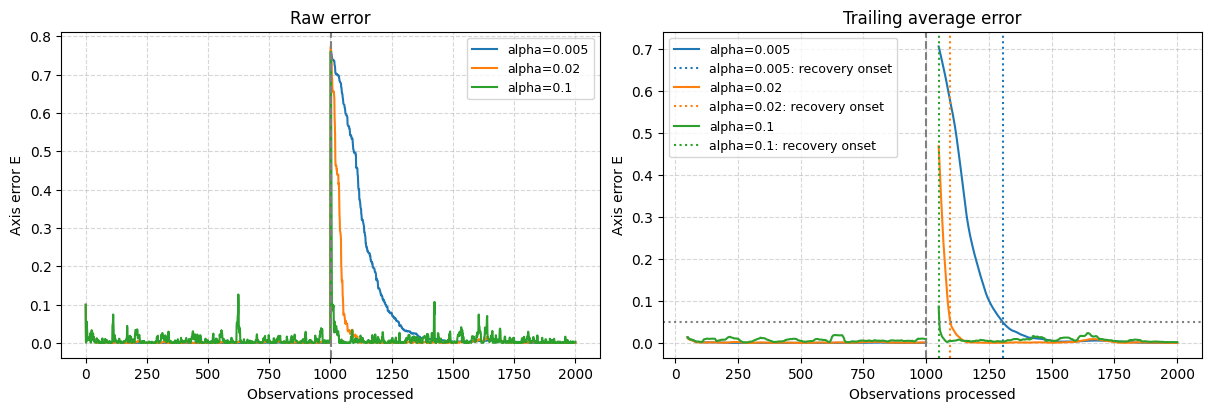

alpha=0.005 cumulative error from observation 1: 103.84564256649715
alpha=0.02 cumulative error from observation 1: 28.776326970864787
alpha=0.1 cumulative error from observation 1: 17.94625298588887


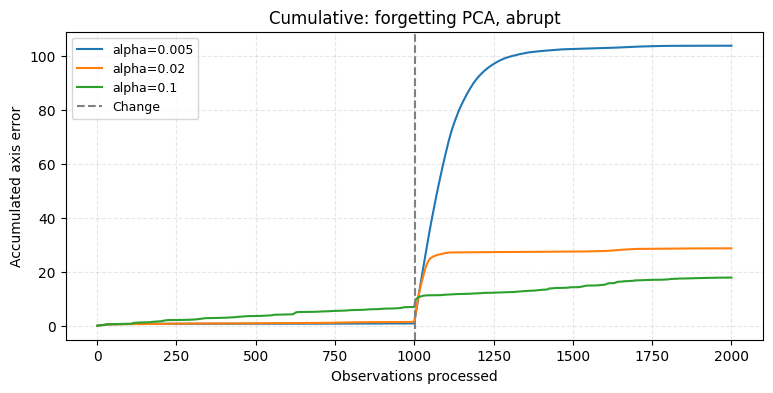

alpha=0.005 stationary angle SD (degrees): 0.6014139939353086
alpha=0.02 stationary angle SD (degrees): 1.6202456932777514
alpha=0.1 stationary angle SD (degrees): 4.612279762594857


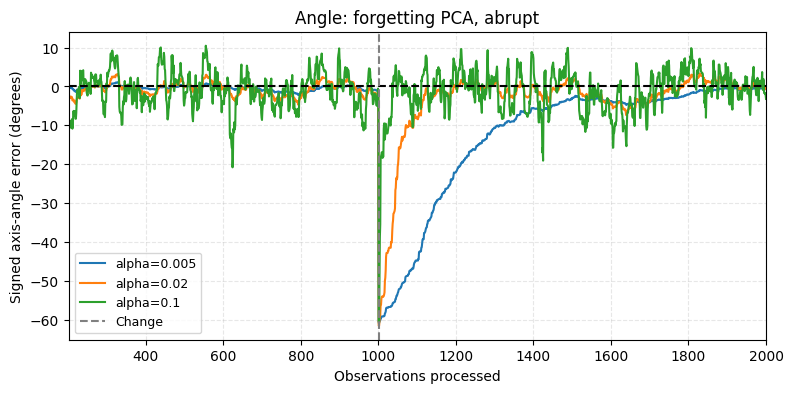

alpha=0.005 mean captured variance after warm-up (%): 86.22594355854193
alpha=0.02 mean captured variance after warm-up (%): 89.63600873358942
alpha=0.1 mean captured variance after warm-up (%): 90.17131892609203


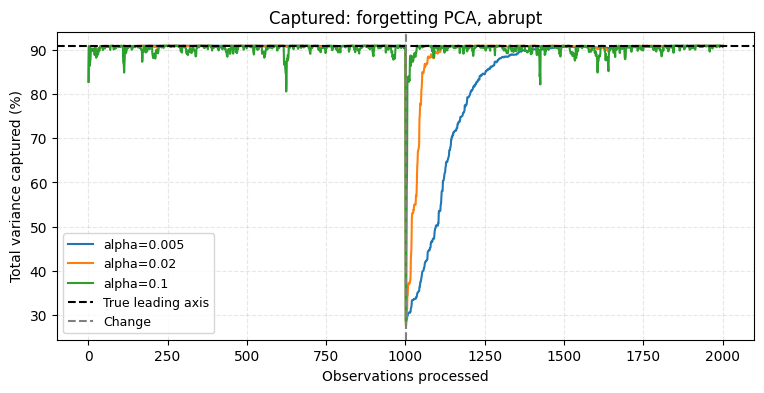

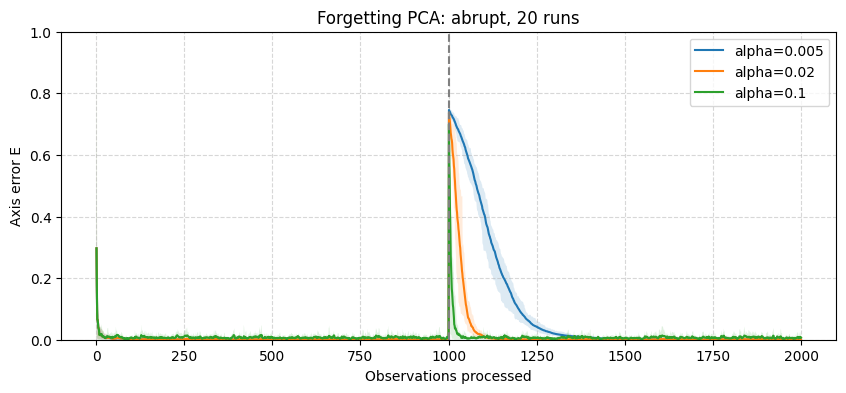

(<Figure size 1000x400 with 1 Axes>,
 <Axes: title={'center': 'Forgetting PCA: abrupt, 20 runs'}, xlabel='Observations processed', ylabel='Axis error E'>)

In [49]:
# Raw axis error and its trailing average: one seed, two panels.
ut.plot_abrupt_errors(
    [forgetting_abrupt_errors[alpha] for alpha in gains],
    [f'alpha={alpha:g}' for alpha in gains],
    switch_step, smooth_window, recovery_threshold, recovery_hold
)

# Accumulated raw error from observation 1, including the initial learning period.
total_curves = [np.cumsum(errors) for errors in [forgetting_abrupt_errors[alpha] for alpha in gains]]
labels = [f'alpha={alpha:g}' for alpha in gains]
for total_error, label in zip(total_curves, labels):
    print(label, 'cumulative error from observation 1:', total_error[-1])
ut.plot_cumulative_error(total_curves, labels,
                      'Cumulative: forgetting PCA, abrupt', switch_step=switch_step)

# Signed angular error in degrees; stationary SD excludes warm-up and any jump.
angle_curves = [axis_angle_error(directions, theta_abrupt)
                for directions in [forgetting_abrupt_directions[alpha] for alpha in gains]]
labels = [f'alpha={alpha:g}' for alpha in gains]
for angles, label in zip(angle_curves, labels):
    print(label, 'stationary angle SD (degrees):', angles[warmup:switch_step].std())
ut.plot_angle_error(angle_curves, labels,
                 'Angle: forgetting PCA, abrupt', warmup, switch_step=switch_step)

# Ground-truth population variance captured by the estimated axis, as a percentage.
percent_curves = [100 * (lam1 - (lam1 - lam2) * errors) / (lam1 + lam2)
                  for errors in [forgetting_abrupt_errors[alpha] for alpha in gains]]
labels = [f'alpha={alpha:g}' for alpha in gains]
for percentages, label in zip(percent_curves, labels):
    print(label, 'mean captured variance after warm-up (%):',
          np.nanmean(percentages[warmup:]))
best_percent = 100 * lam1 / (lam1 + lam2)
ut.plot_captured_variance(percent_curves, labels,
                       'Captured: forgetting PCA, abrupt', best_percent, switch_step=switch_step)

# Across-seed mean raw error and 10th-90th percentile band, not a confidence interval.
ut.plot_repeated_errors(
    [forgetting_abrupt_runs[alpha] for alpha in gains], [f'alpha={alpha:g}' for alpha in gains],
    'Forgetting PCA: abrupt, 20 runs', start=0, switch_step=switch_step, upper_limit=1
)

**Plots.**
- After the change, all the old observations are still in the estimate, but their total weight shrinks by a factor (1 − α) at every step. After k new observations the new regime has weight w = 1 − (1 − α)ᵏ. With that weight, the estimated axis is the axis of the mix of the two regimes, as for cumulative PCA. Note that for the abrupt regime, a forgetting factor drastically improves performance (with respect to the cumulative regime).
- Before switch, the cumulative error is almost flat for the small gains, while $\alpha=0.1$ keeps accumulating
  noise; the opposite happens after.
- The 20-run band widens during the transient of $\alpha=0.005$.

#### Repeated-run measurements

In [50]:
rows = []
for alpha in gains:
    runs = forgetting_abrupt_runs[alpha]
    label = f'alpha={alpha:g}'
    pre_means = runs[:, warmup:switch_step].mean(axis=1)
    post_means = runs[:, switch_step:].mean(axis=1)
    final_means = runs[:, -warmup:].mean(axis=1)
    delays = []
    for errors in runs:
        delays.append(recovery_delay(errors, switch_step, threshold=recovery_threshold, window=smooth_window, hold=recovery_hold))
    delays = np.array(delays)
    recovered = np.isfinite(delays)
    median_delay = 'Not confirmed'
    if recovered.any():
        median_delay = float(np.median(delays[recovered]))
    rows.append([label,
                 f'{pre_means.mean():.5f} +/- {pre_means.std(ddof=1):.5f}',
                 f'{post_means.mean():.5f} +/- {post_means.std(ddof=1):.5f}',
                 f'{final_means.mean():.5f} +/- {final_means.std(ddof=1):.5f}',
                 f'{recovered.sum()}/{len(delays)}', median_delay])
ut.show_table(['Method', 'Pre-change E: mean +/- SD', 'Post-change E: mean +/- SD', 'Final E: mean +/- SD', 'Recovered runs', 'Median delay'], rows)

| Method | Pre-change E: mean +/- SD | Post-change E: mean +/- SD | Final E: mean +/- SD | Recovered runs | Median delay |
| --- | --- | --- | --- | --- | --- |
| alpha=0.005 | 0.00034 +/- 0.00015 | 0.08937 +/- 0.00914 | 0.00035 +/- 0.00032 | 20/20 | 260.5 |
| alpha=0.02 | 0.00123 +/- 0.00045 | 0.02343 +/- 0.00573 | 0.00135 +/- 0.00115 | 20/20 | 91.5 |
| alpha=0.1 | 0.00695 +/- 0.00139 | 0.01096 +/- 0.00279 | 0.00705 +/- 0.00261 | 20/20 | 53.5 |


- **Pre-change:** the stationary noise (0.0003, 0.0012, 0.007), as expected: the first 1000 observations are the stationary data.
- **Post-change**: this column inverts the ranking. α = 0.1 is now the best (0.011) and α = 0.005 the worst (0.089, 8 times as much). It's almost all transient, as the predictions show.
- **Final segment**: back to the stationary values, so the change has been completely forgotten for every gain.
- **Recovered and median delay**: all seeds recover, with delays matching the noise-free predictions. For α = 0.1 the delay (53.5) is almost at its floor of 50, because the trailing average needs 50 post-change observations.

### Smooth rotation data

In [51]:
forgetting_rotation_errors = {}
forgetting_rotation_directions = {}
for alpha in gains:
    directions, covariance = forgetting_pca(X_rotation, alpha)
    forgetting_rotation_directions[alpha] = directions.copy()
    errors = axis_error(directions, truth_rotation)
    forgetting_rotation_errors[alpha] = errors

#### Single-run measurements

In [52]:
rows = []
for alpha in gains:
    errors = forgetting_rotation_errors[alpha]
    label = f'alpha={alpha:g}'
    mean_error = errors[warmup:].mean()
    temporal_sd = errors[warmup:].std()
    rows.append([label, f'{mean_error:.5f}', f'{temporal_sd:.5f}'])
ut.show_table(['Method', 'Mean error after warm-up', 'Temporal error SD'], rows)

| Method | Mean error after warm-up | Temporal error SD |
| --- | --- | --- |
| alpha=0.005 | 0.03686 | 0.01253 |
| alpha=0.02 | 0.00519 | 0.00503 |
| alpha=0.1 | 0.00719 | 0.01123 |


#### Repeat with 20 seeds

In [53]:
forgetting_rotation_runs = {}
forgetting_rotation_runtimes = {}
forgetting_rotation_angles = {}
for alpha in gains:
    runs = []
    runtimes = []
    angles = []
    for run_seed in seeds:
        X_run, theta_run, truth_run = rotation_streams[run_seed]
        # Time only the PCA calculation, not generation or evaluation.
        start = time.perf_counter()
        directions, covariance = forgetting_pca(X_run, alpha)
        runtimes.append(time.perf_counter() - start)
        runs.append(axis_error(directions, truth_run))
        angles.append(axis_angle_error(directions, theta_run))
    forgetting_rotation_runs[alpha] = np.array(runs)
    forgetting_rotation_runtimes[alpha] = np.array(runtimes)
    forgetting_rotation_angles[alpha] = np.array(angles)
    # Select this gain's arrays, rather than passing the entire dictionary.
    save_results('Forgetting PCA', 'rotation',
                 forgetting_rotation_runs[alpha], forgetting_rotation_runtimes[alpha],
                 alpha=alpha, angle_runs=forgetting_rotation_angles[alpha], settings=rotation_settings)

Saved Forgetting PCA, rotation, alpha=0.005 to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\baselines\pca_rotation_results_omega=0.001_dt=1.csv
Saved Forgetting PCA, rotation, alpha=0.02 to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\baselines\pca_rotation_results_omega=0.001_dt=1.csv
Saved Forgetting PCA, rotation, alpha=0.1 to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\baselines\pca_rotation_results_omega=0.001_dt=1.csv


#### Computational cost

In [54]:
rows = []
for alpha in gains:
    runtimes = forgetting_rotation_runtimes[alpha]
    label = f'alpha={alpha:g}'
    rows.append([label, runtimes.mean(), runtimes.min(), runtimes.max(), runtimes.std(ddof=1)])
ut.show_table(['Method', 'Mean seconds', 'Shortest seconds', 'Longest seconds', 'SD seconds'], rows)

| Method | Mean seconds | Shortest seconds | Longest seconds | SD seconds |
| --- | --- | --- | --- | --- |
| alpha=0.005 | 0.1374161099898629 | 0.09701169998152182 | 0.2287361000198871 | 0.043139214479222705 |
| alpha=0.02 | 0.3703965200053062 | 0.1110082000377588 | 1.2647521999897435 | 0.30682872289131613 |
| alpha=0.1 | 0.22503422500449233 | 0.11198869999498129 | 0.9313258999609388 | 0.20200769449431727 |


#### Repeated-run plot

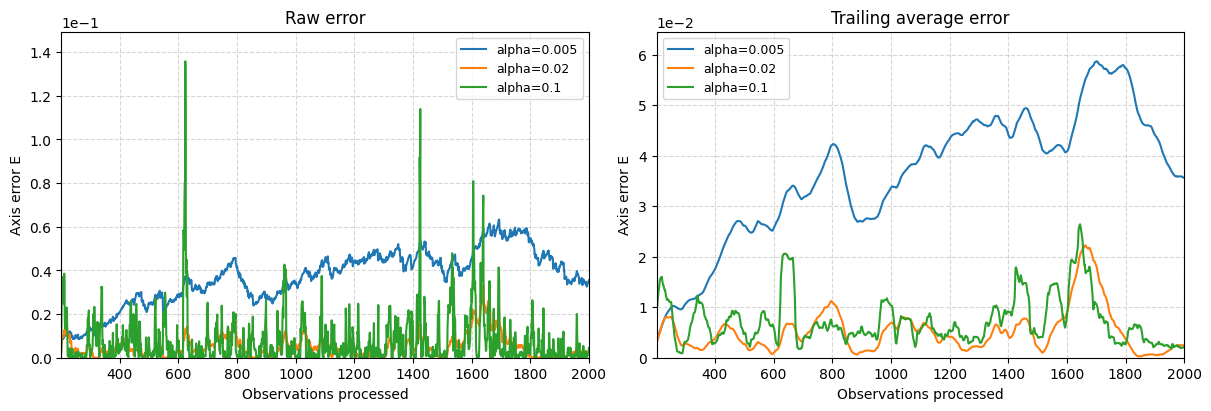

alpha=0.005 cumulative error from observation 1: 67.0984659090613
alpha=0.02 cumulative error from observation 1: 10.070850184506611
alpha=0.1 cumulative error from observation 1: 14.686566265374395


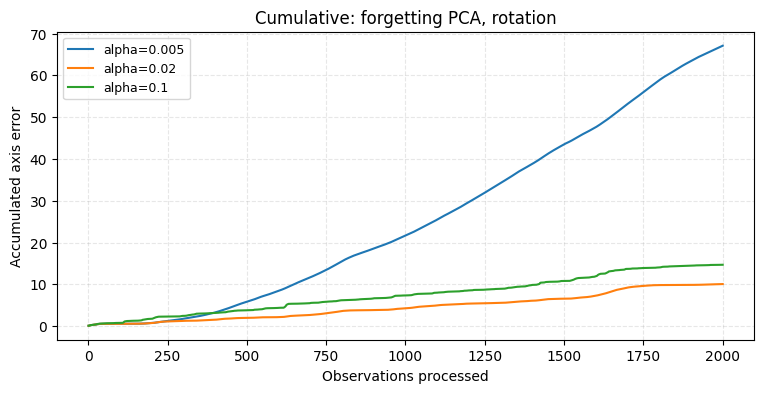

alpha=0.005 tracking angle-error SD (degrees): 2.0942967592034187
alpha=0.02 tracking angle-error SD (degrees): 1.9375095518739078
alpha=0.1 tracking angle-error SD (degrees): 4.66506143562788


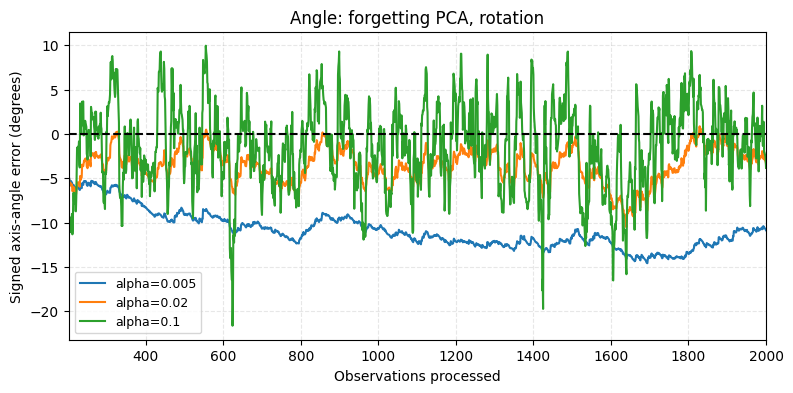

alpha=0.005 mean captured variance after warm-up (%): 87.89307015527342
alpha=0.02 mean captured variance after warm-up (%): 90.48411962150686
alpha=0.1 mean captured variance after warm-up (%): 90.32107678298664


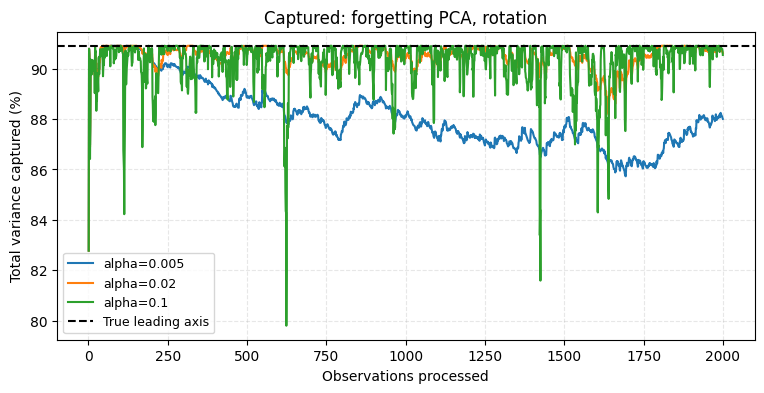

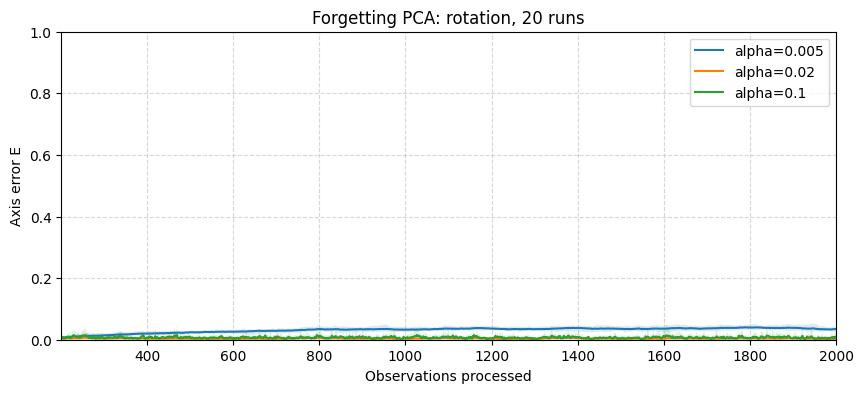

(<Figure size 1000x400 with 1 Axes>,
 <Axes: title={'center': 'Forgetting PCA: rotation, 20 runs'}, xlabel='Observations processed', ylabel='Axis error E'>)

In [55]:
# Raw axis error and its trailing average: one seed, two panels.
ut.plot_stationary_errors(
    [forgetting_rotation_errors[alpha] for alpha in gains],
    [f'alpha={alpha:g}' for alpha in gains],
    warmup, smooth_window
)

# Accumulated raw error from observation 1, including the initial learning period.
total_curves = [np.cumsum(errors) for errors in [forgetting_rotation_errors[alpha] for alpha in gains]]
labels = [f'alpha={alpha:g}' for alpha in gains]
for total_error, label in zip(total_curves, labels):
    print(label, 'cumulative error from observation 1:', total_error[-1])
ut.plot_cumulative_error(total_curves, labels,
                      'Cumulative: forgetting PCA, rotation')

# Signed angular tracking error in degrees; SD excludes warm-up.
angle_curves = [axis_angle_error(directions, theta_rotation)
                for directions in [forgetting_rotation_directions[alpha] for alpha in gains]]
labels = [f'alpha={alpha:g}' for alpha in gains]
for angles, label in zip(angle_curves, labels):
    print(label, 'tracking angle-error SD (degrees):', angles[warmup:].std())
ut.plot_angle_error(angle_curves, labels,
                 'Angle: forgetting PCA, rotation', warmup)

# Ground-truth population variance captured by the estimated axis, as a percentage.
percent_curves = [100 * (lam1 - (lam1 - lam2) * errors) / (lam1 + lam2)
                  for errors in [forgetting_rotation_errors[alpha] for alpha in gains]]
labels = [f'alpha={alpha:g}' for alpha in gains]
for percentages, label in zip(percent_curves, labels):
    print(label, 'mean captured variance after warm-up (%):',
          np.nanmean(percentages[warmup:]))
best_percent = 100 * lam1 / (lam1 + lam2)
ut.plot_captured_variance(percent_curves, labels,
                       'Captured: forgetting PCA, rotation', best_percent)

# Across-seed mean raw error and 10th-90th percentile band, not a confidence interval.
ut.plot_repeated_errors(
    [forgetting_rotation_runs[alpha] for alpha in gains], [f'alpha={alpha:g}' for alpha in gains],
    'Forgetting PCA: rotation, 20 runs', start=0, warmup=warmup, upper_limit=1
)

**Plots.**
- $\alpha=0.005$ lags for the whole run; a parameter that gives $95%$ of the influence to past observations can't keep up with a steadily moving angle; . $\alpha=0.02$ lags with moderate noise; $\alpha=0.1$ is centred but noisy.
- $\alpha=0.02$ has the lowest cumulative error: with both lag and noise, the intermediate gain is best. 

#### Repeated-run measurements

In [56]:
rows = []
for alpha in gains:
    runs = forgetting_rotation_runs[alpha]
    label = f'alpha={alpha:g}'
    run_means = runs[:, warmup:].mean(axis=1)
    mean_error = run_means.mean()
    sd_error = run_means.std(ddof=1)
    temporal_sd = runs[:, warmup:].std(axis=1).mean()
    rows.append([label, f'{mean_error:.5f}', f'{sd_error:.5f}', f'{temporal_sd:.5f}'])
ut.show_table(['Method', 'Mean E', 'SD of run means', 'Mean temporal SD'], rows)

| Method | Mean E | SD of run means | Mean temporal SD |
| --- | --- | --- | --- |
| alpha=0.005 | 0.03141 | 0.00259 | 0.00980 |
| alpha=0.02 | 0.00383 | 0.00097 | 0.00394 |
| alpha=0.1 | 0.00693 | 0.00091 | 0.01063 |


### Random drift data

In [57]:
forgetting_drift_errors = {}
forgetting_drift_directions = {}
for alpha in gains:
    directions, covariance = forgetting_pca(X_drift, alpha)
    forgetting_drift_directions[alpha] = directions.copy()
    errors = axis_error(directions, truth_drift)
    forgetting_drift_errors[alpha] = errors

#### Single-run measurements

In [58]:
rows = []
for alpha in gains:
    errors = forgetting_drift_errors[alpha]
    label = f'alpha={alpha:g}'
    mean_error = errors[warmup:].mean()
    temporal_sd = errors[warmup:].std()
    rows.append([label, f'{mean_error:.5f}', f'{temporal_sd:.5f}'])
ut.show_table(['Method', 'Mean error after warm-up', 'Temporal error SD'], rows)

| Method | Mean error after warm-up | Temporal error SD |
| --- | --- | --- |
| alpha=0.005 | 0.01296 | 0.01741 |
| alpha=0.02 | 0.00511 | 0.00771 |
| alpha=0.1 | 0.00840 | 0.01352 |


#### Repeat with 20 seeds

In [59]:
forgetting_drift_runs = {}
forgetting_drift_runtimes = {}
forgetting_drift_angles = {}
for alpha in gains:
    runs = []
    runtimes = []
    angles = []
    for run_seed in seeds:
        X_run, theta_run, truth_run = drift_streams[run_seed]
        # Time only the PCA calculation, not generation or evaluation.
        start = time.perf_counter()
        directions, covariance = forgetting_pca(X_run, alpha)
        runtimes.append(time.perf_counter() - start)
        runs.append(axis_error(directions, truth_run))
        angles.append(axis_angle_error(directions, theta_run))
    forgetting_drift_runs[alpha] = np.array(runs)
    forgetting_drift_runtimes[alpha] = np.array(runtimes)
    forgetting_drift_angles[alpha] = np.array(angles)
    # Select this gain's arrays, rather than passing the entire dictionary.
    save_results('Forgetting PCA', 'drift',
                 forgetting_drift_runs[alpha], forgetting_drift_runtimes[alpha],
                 alpha=alpha, angle_runs=forgetting_drift_angles[alpha], settings=drift_settings)

Saved Forgetting PCA, drift, alpha=0.005 to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\baselines\pca_drift_results_Q=0.0001_dt=1.csv
Saved Forgetting PCA, drift, alpha=0.02 to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\baselines\pca_drift_results_Q=0.0001_dt=1.csv
Saved Forgetting PCA, drift, alpha=0.1 to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\baselines\pca_drift_results_Q=0.0001_dt=1.csv


#### Computational cost

In [60]:
rows = []
for alpha in gains:
    runtimes = forgetting_drift_runtimes[alpha]
    label = f'alpha={alpha:g}'
    rows.append([label, runtimes.mean(), runtimes.min(), runtimes.max(), runtimes.std(ddof=1)])
ut.show_table(['Method', 'Mean seconds', 'Shortest seconds', 'Longest seconds', 'SD seconds'], rows)

| Method | Mean seconds | Shortest seconds | Longest seconds | SD seconds |
| --- | --- | --- | --- | --- |
| alpha=0.005 | 0.1705000349902548 | 0.11795909999636933 | 0.3573441000189632 | 0.06172408974620424 |
| alpha=0.02 | 0.27926453500404025 | 0.12609850004082546 | 1.5127459000214003 | 0.30982203078545556 |
| alpha=0.1 | 0.16211586499994154 | 0.10749889997532591 | 0.4030401999480091 | 0.08086518993075628 |


#### Repeated-run plot

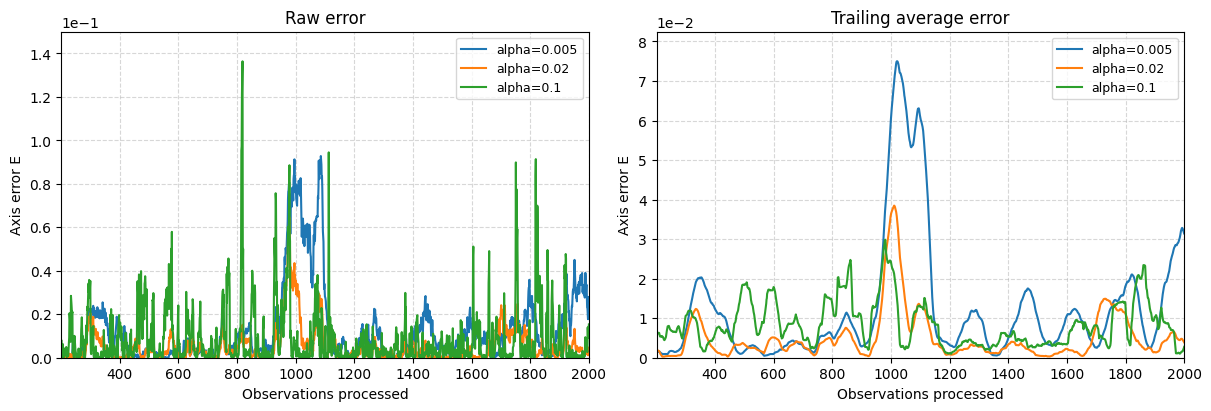

alpha=0.005 cumulative error from observation 1: 24.971858913318616
alpha=0.02 cumulative error from observation 1: 10.86811380425989
alpha=0.1 cumulative error from observation 1: 17.50477701985876


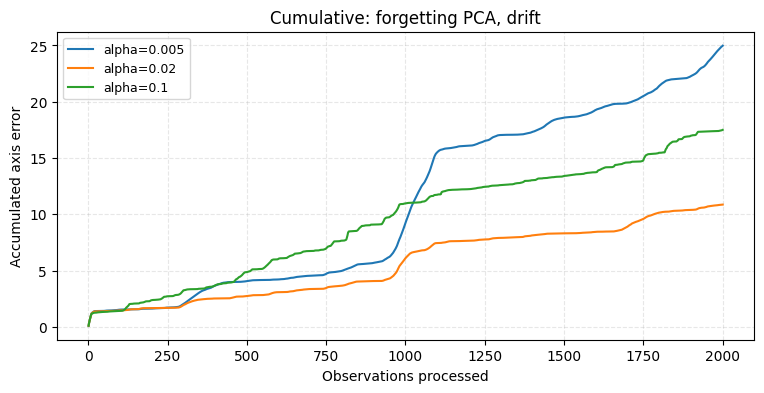

alpha=0.005 tracking angle-error SD (degrees): 5.53577699550741
alpha=0.02 tracking angle-error SD (degrees): 3.7509489843940558
alpha=0.1 tracking angle-error SD (degrees): 5.178457810224601


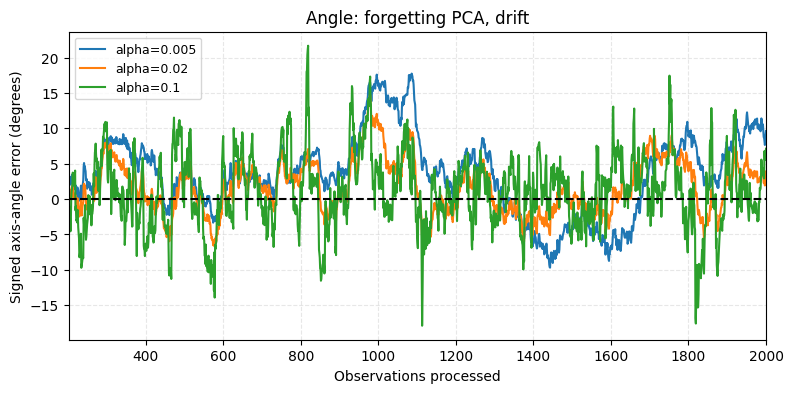

alpha=0.005 mean captured variance after warm-up (%): 89.8484294411772
alpha=0.02 mean captured variance after warm-up (%): 90.49130758781244
alpha=0.1 mean captured variance after warm-up (%): 90.22164703295927


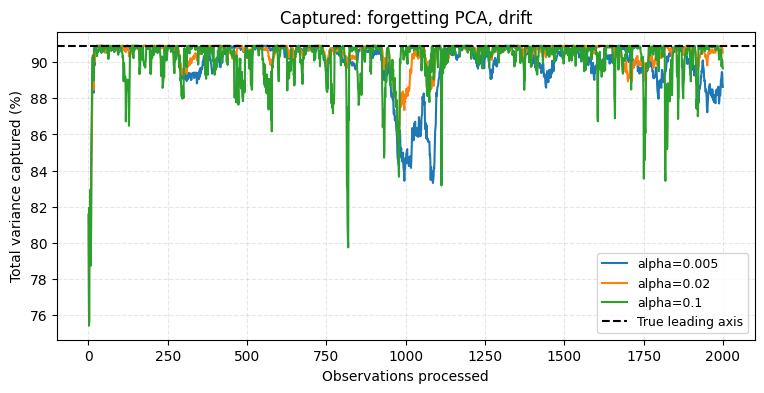

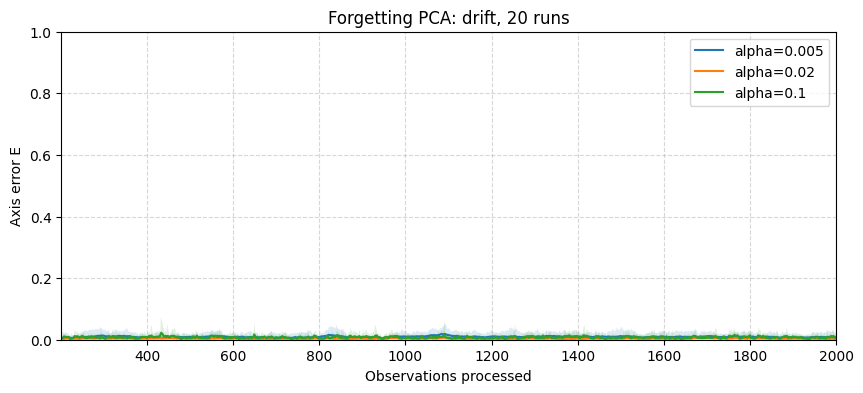

(<Figure size 1000x400 with 1 Axes>,
 <Axes: title={'center': 'Forgetting PCA: drift, 20 runs'}, xlabel='Observations processed', ylabel='Axis error E'>)

In [61]:
# Raw axis error and its trailing average: one seed, two panels.
ut.plot_stationary_errors(
    [forgetting_drift_errors[alpha] for alpha in gains],
    [f'alpha={alpha:g}' for alpha in gains],
    warmup, smooth_window
)

# Accumulated raw error from observation 1, including the initial learning period.
total_curves = [np.cumsum(errors) for errors in [forgetting_drift_errors[alpha] for alpha in gains]]
labels = [f'alpha={alpha:g}' for alpha in gains]
for total_error, label in zip(total_curves, labels):
    print(label, 'cumulative error from observation 1:', total_error[-1])
ut.plot_cumulative_error(total_curves, labels,
                      'Cumulative: forgetting PCA, drift')

# Signed angular tracking error in degrees; SD excludes warm-up.
angle_curves = [axis_angle_error(directions, theta_drift)
                for directions in [forgetting_drift_directions[alpha] for alpha in gains]]
labels = [f'alpha={alpha:g}' for alpha in gains]
for angles, label in zip(angle_curves, labels):
    print(label, 'tracking angle-error SD (degrees):', angles[warmup:].std())
ut.plot_angle_error(angle_curves, labels,
                 'Angle: forgetting PCA, drift', warmup)

# Ground-truth population variance captured by the estimated axis, as a percentage.
percent_curves = [100 * (lam1 - (lam1 - lam2) * errors) / (lam1 + lam2)
                  for errors in [forgetting_drift_errors[alpha] for alpha in gains]]
labels = [f'alpha={alpha:g}' for alpha in gains]
for percentages, label in zip(percent_curves, labels):
    print(label, 'mean captured variance after warm-up (%):',
          np.nanmean(percentages[warmup:]))
best_percent = 100 * lam1 / (lam1 + lam2)
ut.plot_captured_variance(percent_curves, labels,
                       'Captured: forgetting PCA, drift', best_percent)

# Across-seed mean raw error and 10th-90th percentile band, not a confidence interval.
ut.plot_repeated_errors(
    [forgetting_drift_runs[alpha] for alpha in gains], [f'alpha={alpha:g}' for alpha in gains],
    'Forgetting PCA: drift, 20 runs', start=0, warmup=warmup, upper_limit=1
)

**Plots.**
- The errors peak where the drift is fast (around observation $1000$ in this seed, where the angle starts changing more abruptly). The slow gain suffers most
  there (trailing average up to $0.075$); the fast gain is noisy everywhere.
- $\alpha=0.02$ has the lowest cumulative error.

#### Repeated-run measurements

In [62]:
rows = []
for alpha in gains:
    runs = forgetting_drift_runs[alpha]
    label = f'alpha={alpha:g}'
    run_means = runs[:, warmup:].mean(axis=1)
    mean_error = run_means.mean()
    sd_error = run_means.std(ddof=1)
    temporal_sd = runs[:, warmup:].std(axis=1).mean()
    rows.append([label, f'{mean_error:.5f}', f'{sd_error:.5f}', f'{temporal_sd:.5f}'])
ut.show_table(['Method', 'Mean E', 'SD of run means', 'Mean temporal SD'], rows)

| Method | Mean E | SD of run means | Mean temporal SD |
| --- | --- | --- | --- |
| alpha=0.005 | 0.00926 | 0.00301 | 0.01158 |
| alpha=0.02 | 0.00366 | 0.00064 | 0.00490 |
| alpha=0.1 | 0.00757 | 0.00092 | 0.01134 |


### Results for this method

Mean axis error after warm-up over 20 seeds (abrupt: after the change, recovered runs, median delay).

| Gain | Stationary | Abrupt, after the change | Rotation | Drift |
|---|---|---|---|---|
| $\alpha=0.1$ | 0.00680 | 0.0110 (20/20, 53.5) | 0.00693 | 0.00757 |
| $\alpha=0.02$ | 0.00121 | 0.0234 (20/20, 91.5) | 0.00383 | 0.00366 |
| $\alpha=0.005$ | 0.00030 | 0.0894 (20/20, 260.5) | 0.0314 | 0.00926 |

- **Adding a gain makes the method recover**: every run recovers after the change, for every gain, unlike
  cumulative PCA.
- **The gain trades noise for speed.** The stationary error grows about linearly with $\alpha$, as
  predicted by $\frac{\alpha}{2-\alpha}\,\frac{\lambda_1\lambda_2}{(\lambda_1-\lambda_2)^2}$ ($0.00031$,
  $0.00125$, $0.0065$ for the three gains; derivation and check in `03_oja`, Section 2). The median recovery
  delay shrinks as $\alpha$ grows ($260.5$, $91.5$, $53.5$). The delay cannot go below the trailing window
  ($50$ steps, see `metrics.recovery_delay`), so for $\alpha=0.1$ it is close to its floor.
- **In rotation and drift the best of the three gains is the intermediate one** ($\alpha=0.02$). The small
  gain lags behind the moving direction (rotation error $0.0314$), the large one is noisy ($0.0069$): both
  noise and lag contribute, and the optimum is in between.
- **The best gain depends on the regime**: the smallest in stationary data, the largest after the abrupt
  change, the intermediate one in rotation and drift.

## 3. Incremental PCA (SVD update)

All observations have equal weight, as in cumulative PCA, but the estimate is obtained by updating a truncated SVD instead of the covariance matrix. It is `svd_pca` with the gain $\alpha_n = 1/n$:

$$A_n=\operatorname{rank}_1\Big(\big(1-\tfrac{1}{n}\big)A_{n-1}+\tfrac{1}{n}\,x_nx_n^\top\Big).$$

Each update discounts the retained eigenvalue by $(1-\alpha_n)$, scales the new observation by $\sqrt{\alpha_n}$, splits it into a part along the retained axis $q$ and a perpendicular residual $r$, diagonalizes a $2\times2$ matrix in the basis $\{q, r/\lVert r\rVert\}$ and keeps only the largest eigenpair (Brand, 2006). This truncated incremental update of the second-moment matrix, $C_t=P_{\text{rank-}k}(C_{t-1}+x_tx_t^\top)$, is the incremental PCA algorithm of Arora et al. (2012); they also give an example of orthogonal data for which the truncated update converges to the wrong direction, so truncation can change the result and not only its accuracy. The past is never recomputed. The population mean is assumed known to be zero, as for the other methods, and an estimate is available from the first observation.

The same function with a fixed gain is the rank-1 SVD forgetting PCA of section 4: cumulative PCA corresponds to the gain schedule $\alpha_n=1/n$.

`sklearn.decomposition.IncrementalPCA` also updates an SVD summary rather than recomputing it (Ross et al., 2008). It is not used here because it has no forgetting factor (the gain cannot be controlled), it centres with the sample mean, and one-observation `partial_fit` calls are dominated by library overhead. With one retained component, this implementation gives essentially the same errors on the abrupt streams (mean post-change error 0.5624, against 0.5625 for scikit-learn in the earlier benchmark).

[IncrementalPCA documentation](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.IncrementalPCA.html)
**Sources.** Rank-one SVD update of Brand (2006); incremental PCA of Arora et al. (2012); scikit-learn's
`IncrementalPCA` follows Ross et al. (2008). See `docs/literature_review.md`, Sections 3.1–3.2.


#### SVD Truncation

With full rank (two retained components in 2D) the SVD update is exact and reproduces cumulative PCA; this is verified in the tests and in the basic checks below. With one retained component, the perpendicular part of the retained information is discarded after every update. Differences from cumulative PCA are therefore due only to truncation, not to centering. The effect is strongest after an abrupt change: variance along the new direction cannot accumulate in the discarded component, so the estimate moves more slowly than exact cumulative PCA.

### Stationary data

In [63]:
directions, state = incremental_pca(X_stationary)
incremental_stationary_errors = axis_error(directions, truth_stationary)
incremental_stationary_directions = directions.copy()

#### Single-run measurements

In [64]:
rows = []
errors = incremental_stationary_errors
label = 'Incremental PCA'
mean_error = errors[warmup:].mean()
temporal_sd = errors[warmup:].std()
rows.append([label, f'{mean_error:.5f}', f'{temporal_sd:.5f}'])
ut.show_table(['Method', 'Mean error after warm-up', 'Temporal error SD'], rows)

| Method | Mean error after warm-up | Temporal error SD |
| --- | --- | --- |
| Incremental PCA | 0.00006 | 0.00006 |


#### Repeat with 20 seeds

Use a new stream for each seed. All baseline method sections use the same seed list. Rows in the saved array are runs, and columns are timesteps.

In [65]:
runs = []
runtimes = []
angles = []
for run_seed in seeds:
    X_run, theta_run, truth_run = stationary_streams[run_seed]
    # Time only the PCA calculation, not generation or evaluation.
    start = time.perf_counter()
    directions, state = incremental_pca(X_run)
    runtimes.append(time.perf_counter() - start)
    runs.append(axis_error(directions, truth_run))
    angles.append(axis_angle_error(directions, theta_run))
incremental_stationary_runs = np.array(runs)
incremental_stationary_runtimes = np.array(runtimes)
incremental_stationary_angles = np.array(angles)

save_results('Incremental PCA (rank-1 SVD)', 'stationary',
             incremental_stationary_runs, incremental_stationary_runtimes,
             angle_runs=incremental_stationary_angles, settings=benchmark_settings)

Saved Incremental PCA (rank-1 SVD), stationary, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\baselines\pca_benchmark_results.csv


#### Computational cost

In [66]:
rows = []
runtimes = incremental_stationary_runtimes
label = 'Incremental PCA'
rows.append([label, runtimes.mean(), runtimes.min(), runtimes.max(), runtimes.std(ddof=1)])
ut.show_table(['Method', 'Mean seconds', 'Shortest seconds', 'Longest seconds', 'SD seconds'], rows)

| Method | Mean seconds | Shortest seconds | Longest seconds | SD seconds |
| --- | --- | --- | --- | --- |
| Incremental PCA | 0.4021996500028763 | 0.11070170003222302 | 1.224495999980718 | 0.31261847854989866 |


#### Repeated-run plot

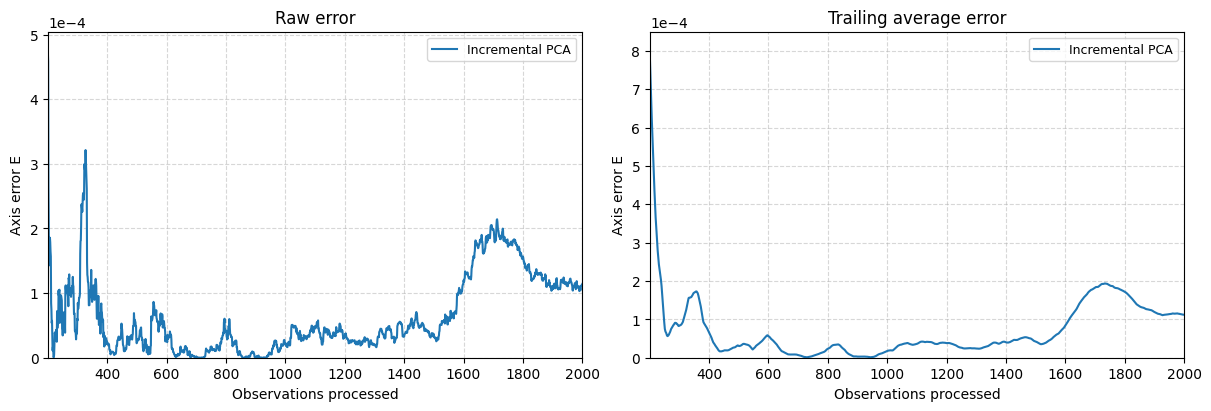

Incremental PCA cumulative error from observation 1: 1.0162539738821774


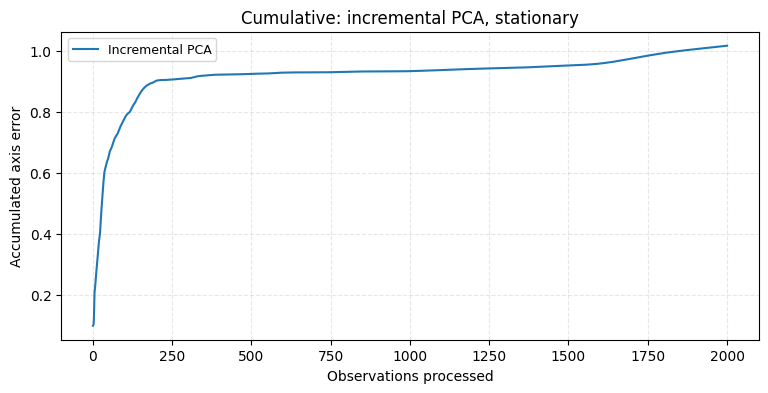

Incremental PCA stationary angle SD (degrees): 0.4126031933101206


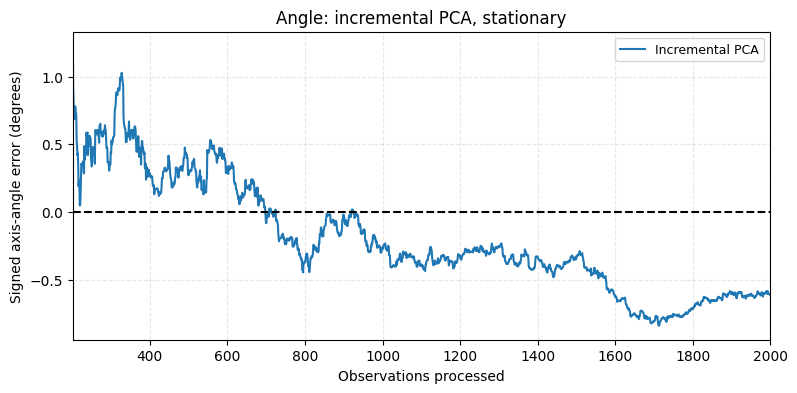

Incremental PCA mean captured variance after warm-up (%): 90.90387357535855


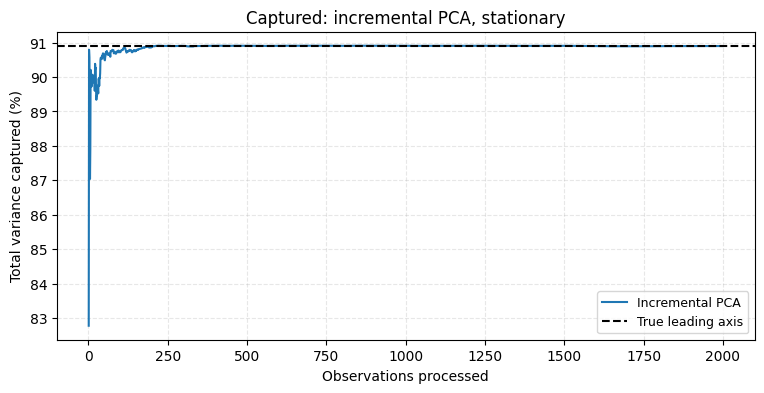

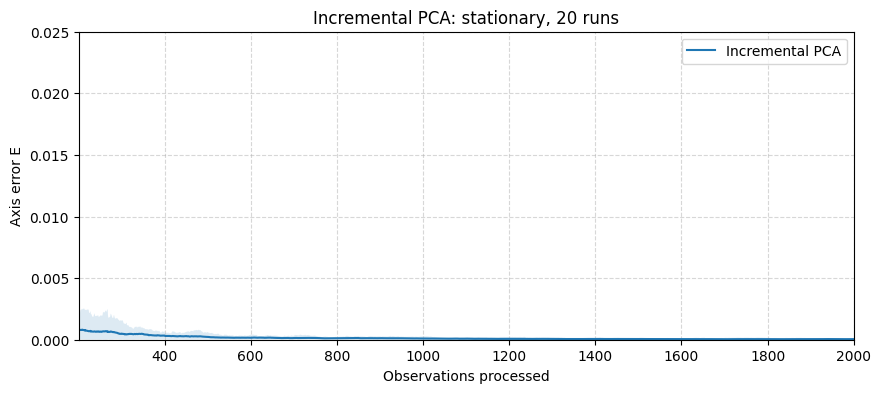

(<Figure size 1000x400 with 1 Axes>,
 <Axes: title={'center': 'Incremental PCA: stationary, 20 runs'}, xlabel='Observations processed', ylabel='Axis error E'>)

In [67]:
# Raw axis error and its trailing average: one seed, two panels.
ut.plot_stationary_errors(
    [incremental_stationary_errors], ['Incremental PCA'],
    warmup, smooth_window
)

# Accumulated raw error from observation 1, including the initial learning period.
total_curves = [np.cumsum(errors) for errors in [incremental_stationary_errors]]
labels = ['Incremental PCA']
for total_error, label in zip(total_curves, labels):
    print(label, 'cumulative error from observation 1:', total_error[-1])
ut.plot_cumulative_error(total_curves, labels,
                      'Cumulative: incremental PCA, stationary')

# Signed angular error in degrees; stationary SD excludes warm-up and any jump.
angle_curves = [axis_angle_error(directions, theta_stationary)
                for directions in [incremental_stationary_directions]]
labels = ['Incremental PCA']
for angles, label in zip(angle_curves, labels):
    print(label, 'stationary angle SD (degrees):', angles[warmup:].std())
ut.plot_angle_error(angle_curves, labels,
                 'Angle: incremental PCA, stationary', warmup)

# Ground-truth population variance captured by the estimated axis, as a percentage.
percent_curves = [100 * (lam1 - (lam1 - lam2) * errors) / (lam1 + lam2)
                  for errors in [incremental_stationary_errors]]
labels = ['Incremental PCA']
for percentages, label in zip(percent_curves, labels):
    print(label, 'mean captured variance after warm-up (%):',
          np.nanmean(percentages[warmup:]))
best_percent = 100 * lam1 / (lam1 + lam2)
ut.plot_captured_variance(percent_curves, labels,
                       'Captured: incremental PCA, stationary', best_percent)

# Across-seed mean raw error and 10th-90th percentile band, not a confidence interval.
ut.plot_repeated_errors(
    [incremental_stationary_runs], ['Incremental PCA'],
    'Incremental PCA: stationary, 20 runs', start=0, warmup=warmup, upper_limit=0.025
)

**Plots.** 
Almost indistinguishable from cumulative PCA (same scale, same bump around observation $1700$, same
slow drift of the angle). In stationary data the second principal component doesn't carry useful information: the true direction never moves, eeping it (cumulative) or discarding it (incremental) hardly changes where the leading axis points.

There are some differences (for example, cumulative error saturates at a higher error) but they represent very small numerical differences.

#### Repeated-run measurements

In [68]:
rows = []
runs = incremental_stationary_runs
label = 'Incremental PCA'
run_means = runs[:, warmup:].mean(axis=1)
mean_error = run_means.mean()
sd_error = run_means.std(ddof=1)
temporal_sd = runs[:, warmup:].std(axis=1).mean()
rows.append([label, f'{mean_error:.5f}', f'{sd_error:.5f}', f'{temporal_sd:.5f}'])
ut.show_table(['Method', 'Mean E', 'SD of run means', 'Mean temporal SD'], rows)

| Method | Mean E | SD of run means | Mean temporal SD |
| --- | --- | --- | --- |
| Incremental PCA | 0.00015 | 0.00015 | 0.00020 |


### Abrupt-change data

In [69]:
directions, state = incremental_pca(X_abrupt)
incremental_abrupt_errors = axis_error(directions, truth_abrupt)
incremental_abrupt_directions = directions.copy()

#### Single-run measurements

In [70]:
rows = []
errors = incremental_abrupt_errors
label = 'Incremental PCA'
pre_error = errors[warmup:switch_step].mean()
post_error = errors[switch_step:].mean()
final_error = errors[-warmup:].mean()
delay = recovery_delay(errors, switch_step, threshold=recovery_threshold, window=smooth_window, hold=recovery_hold)
rows.append([label, f'{pre_error:.5f}', f'{post_error:.5f}', f'{final_error:.5f}', delay])
ut.show_table(['Method', 'Pre-change mean E', 'Post-change mean E', 'Final-segment mean E', 'Recovery delay'], rows)

| Method | Pre-change mean E | Post-change mean E | Final-segment mean E | Recovery delay |
| --- | --- | --- | --- | --- |
| Incremental PCA | 0.00004 | 0.58675 | 0.45882 | nan |


#### Repeat with 20 seeds

Use a new stream for each seed. All baseline method sections use the same seed list. Rows in the saved array are runs, and columns are timesteps.

In [71]:
runs = []
runtimes = []
angles = []
for run_seed in seeds:
    X_run, theta_run, truth_run = abrupt_streams[run_seed]
    # Time only the PCA calculation, not generation or evaluation.
    start = time.perf_counter()
    directions, state = incremental_pca(X_run)
    runtimes.append(time.perf_counter() - start)
    runs.append(axis_error(directions, truth_run))
    angles.append(axis_angle_error(directions, theta_run))
incremental_abrupt_runs = np.array(runs)
incremental_abrupt_runtimes = np.array(runtimes)
incremental_abrupt_angles = np.array(angles)

save_results('Incremental PCA (rank-1 SVD)', 'abrupt',
             incremental_abrupt_runs, incremental_abrupt_runtimes,
             angle_runs=incremental_abrupt_angles, settings=benchmark_settings)

Saved Incremental PCA (rank-1 SVD), abrupt, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\baselines\pca_benchmark_results.csv


#### Computational cost

In [72]:
rows = []
runtimes = incremental_abrupt_runtimes
label = 'Incremental PCA'
rows.append([label, runtimes.mean(), runtimes.min(), runtimes.max(), runtimes.std(ddof=1)])
ut.show_table(['Method', 'Mean seconds', 'Shortest seconds', 'Longest seconds', 'SD seconds'], rows)

| Method | Mean seconds | Shortest seconds | Longest seconds | SD seconds |
| --- | --- | --- | --- | --- |
| Incremental PCA | 0.24084934999991675 | 0.1357970999670215 | 0.6656677999999374 | 0.14331315432436348 |


#### Repeated-run plot

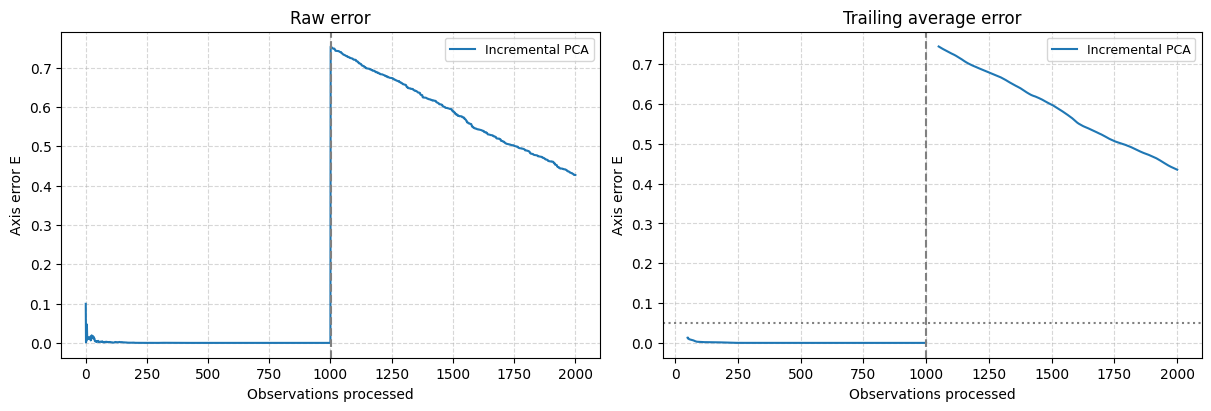

Incremental PCA cumulative error from observation 1: 587.6863222119322


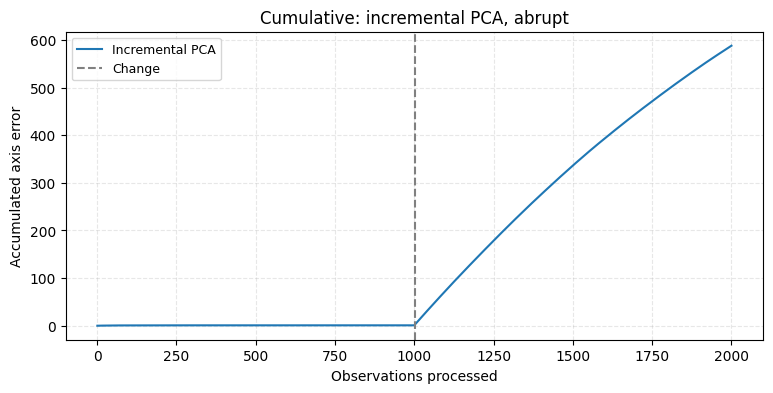

Incremental PCA stationary angle SD (degrees): 0.3165223130644206


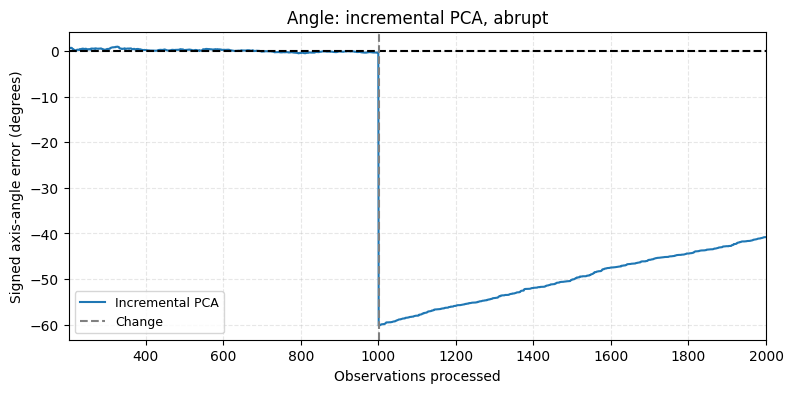

Incremental PCA mean captured variance after warm-up (%): 64.23705229181084


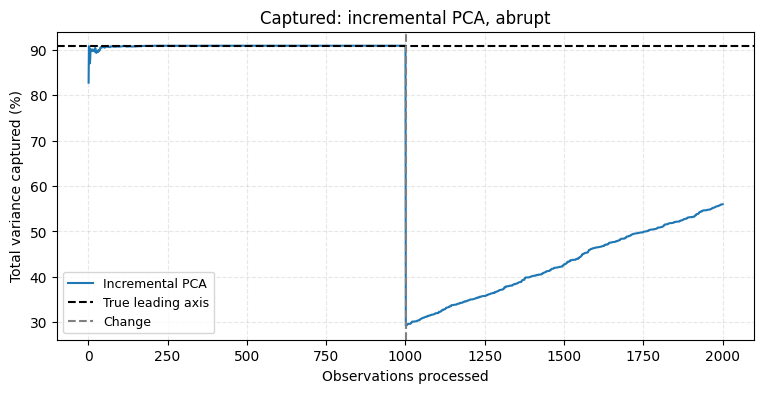

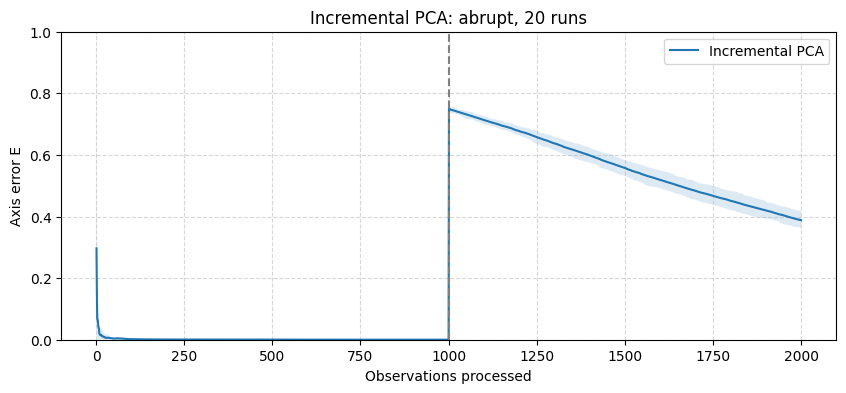

(<Figure size 1000x400 with 1 Axes>,
 <Axes: title={'center': 'Incremental PCA: abrupt, 20 runs'}, xlabel='Observations processed', ylabel='Axis error E'>)

In [73]:
# Raw axis error and its trailing average: one seed, two panels.
ut.plot_abrupt_errors(
    [incremental_abrupt_errors], ['Incremental PCA'],
    switch_step, smooth_window, recovery_threshold, recovery_hold
)

# Accumulated raw error from observation 1, including the initial learning period.
total_curves = [np.cumsum(errors) for errors in [incremental_abrupt_errors]]
labels = ['Incremental PCA']
for total_error, label in zip(total_curves, labels):
    print(label, 'cumulative error from observation 1:', total_error[-1])
ut.plot_cumulative_error(total_curves, labels,
                      'Cumulative: incremental PCA, abrupt', switch_step=switch_step)

# Signed angular error in degrees; stationary SD excludes warm-up and any jump.
angle_curves = [axis_angle_error(directions, theta_abrupt)
                for directions in [incremental_abrupt_directions]]
labels = ['Incremental PCA']
for angles, label in zip(angle_curves, labels):
    print(label, 'stationary angle SD (degrees):', angles[warmup:switch_step].std())
ut.plot_angle_error(angle_curves, labels,
                 'Angle: incremental PCA, abrupt', warmup, switch_step=switch_step)

# Ground-truth population variance captured by the estimated axis, as a percentage.
percent_curves = [100 * (lam1 - (lam1 - lam2) * errors) / (lam1 + lam2)
                  for errors in [incremental_abrupt_errors]]
labels = ['Incremental PCA']
for percentages, label in zip(percent_curves, labels):
    print(label, 'mean captured variance after warm-up (%):',
          np.nanmean(percentages[warmup:]))
best_percent = 100 * lam1 / (lam1 + lam2)
ut.plot_captured_variance(percent_curves, labels,
                       'Captured: incremental PCA, abrupt', best_percent, switch_step=switch_step)

# Across-seed mean raw error and 10th-90th percentile band, not a confidence interval.
ut.plot_repeated_errors(
    [incremental_abrupt_runs], ['Incremental PCA'],
    'Incremental PCA: abrupt, 20 runs', start=0, switch_step=switch_step, upper_limit=1
)

**Plots.**
- Error plots present the same shapes as the cumulative method ones, however we can clearly see this method has more difficulty in recovering from the sudden loss. Incremental PCA throws the variance provided by the second component at every step: the estimated rotation then changes more slowly with respect to the new axis, because it simply sees 'less' of the actual rotation. This represents a trade off between accuracy and computational complexity (which is not so easily seen in 2D, but which provides a huge difference in higher dimensions).
- **Raw error**: at the change, the error jumps to 0.75, then falls to only about 0.43 at the end (0.29 for cumulative).
- **Cumulative error**: flat until 1000, then a steady climb up to 588 (528 for cumulative).
- **Signed angle**: from −60° at the change to about −41° at the end (−32° for cumulative). The line rises more slowly.
- **Captured variance**: it drops to about 30% at the change, the same as cumulative, but rises only to about 56% (67% for cumulative). 

#### Repeated-run measurements

Read the median recovery delay together with the recovered-run count: the median includes only runs that recovered.

In [74]:
rows = []
runs = incremental_abrupt_runs
label = 'Incremental PCA'
pre_means = runs[:, warmup:switch_step].mean(axis=1)
post_means = runs[:, switch_step:].mean(axis=1)
final_means = runs[:, -warmup:].mean(axis=1)
delays = []
for errors in runs:
    delays.append(recovery_delay(errors, switch_step, threshold=recovery_threshold, window=smooth_window, hold=recovery_hold))
delays = np.array(delays)
recovered = np.isfinite(delays)
median_delay = 'Not confirmed'
if recovered.any():
    median_delay = float(np.median(delays[recovered]))
rows.append([label,
             f'{pre_means.mean():.5f} +/- {pre_means.std(ddof=1):.5f}',
             f'{post_means.mean():.5f} +/- {post_means.std(ddof=1):.5f}',
             f'{final_means.mean():.5f} +/- {final_means.std(ddof=1):.5f}',
             f'{recovered.sum()}/{len(delays)}', median_delay])
ut.show_table(['Method', 'Pre-change E: mean +/- SD', 'Post-change E: mean +/- SD', 'Final E: mean +/- SD', 'Recovered runs', 'Median delay'], rows)

| Method | Pre-change E: mean +/- SD | Post-change E: mean +/- SD | Final E: mean +/- SD | Recovered runs | Median delay |
| --- | --- | --- | --- | --- | --- |
| Incremental PCA | 0.00026 +/- 0.00030 | 0.56238 +/- 0.01807 | 0.41934 +/- 0.02269 | 0/20 | Not confirmed |


Before the change incremental and cumulative PCA are equivalent (pre-change error
$0.00026$ against $0.00024$). After the change both give the new regime the same weight and neither recovers, but
incremental PCA is slower: post-change error $0.562$ against $0.488$, final segment $0.419$ against $0.276$. The variance of the new observations perpendicular to the current axis is discarded at every step, so it cannot accumulate and turn the axis.

### Smooth rotation data

In [75]:
directions, state = incremental_pca(X_rotation)
incremental_rotation_errors = axis_error(directions, truth_rotation)
incremental_rotation_directions = directions.copy()

#### Single-run measurements

In [76]:
rows = []
errors = incremental_rotation_errors
label = 'Incremental PCA'
mean_error = errors[warmup:].mean()
temporal_sd = errors[warmup:].std()
rows.append([label, f'{mean_error:.5f}', f'{temporal_sd:.5f}'])
ut.show_table(['Method', 'Mean error after warm-up', 'Temporal error SD'], rows)

| Method | Mean error after warm-up | Temporal error SD |
| --- | --- | --- |
| Incremental PCA | 0.35410 | 0.26395 |


#### Repeat with 20 seeds

In [77]:
runs = []
runtimes = []
angles = []
for run_seed in seeds:
    X_run, theta_run, truth_run = rotation_streams[run_seed]
    # Time only the PCA calculation, not generation or evaluation.
    start = time.perf_counter()
    directions, state = incremental_pca(X_run)
    runtimes.append(time.perf_counter() - start)
    runs.append(axis_error(directions, truth_run))
    angles.append(axis_angle_error(directions, theta_run))
incremental_rotation_runs = np.array(runs)
incremental_rotation_runtimes = np.array(runtimes)
incremental_rotation_angles = np.array(angles)

save_results('Incremental PCA (rank-1 SVD)', 'rotation',
             incremental_rotation_runs, incremental_rotation_runtimes,
             angle_runs=incremental_rotation_angles, settings=rotation_settings)

Saved Incremental PCA (rank-1 SVD), rotation, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\baselines\pca_rotation_results_omega=0.001_dt=1.csv


#### Computational cost

In [78]:
rows = []
runtimes = incremental_rotation_runtimes
label = 'Incremental PCA'
rows.append([label, runtimes.mean(), runtimes.min(), runtimes.max(), runtimes.std(ddof=1)])
ut.show_table(['Method', 'Mean seconds', 'Shortest seconds', 'Longest seconds', 'SD seconds'], rows)

| Method | Mean seconds | Shortest seconds | Longest seconds | SD seconds |
| --- | --- | --- | --- | --- |
| Incremental PCA | 0.5323936300090282 | 0.17603480000980198 | 1.356150500010699 | 0.31793358894815615 |


#### Repeated-run plot

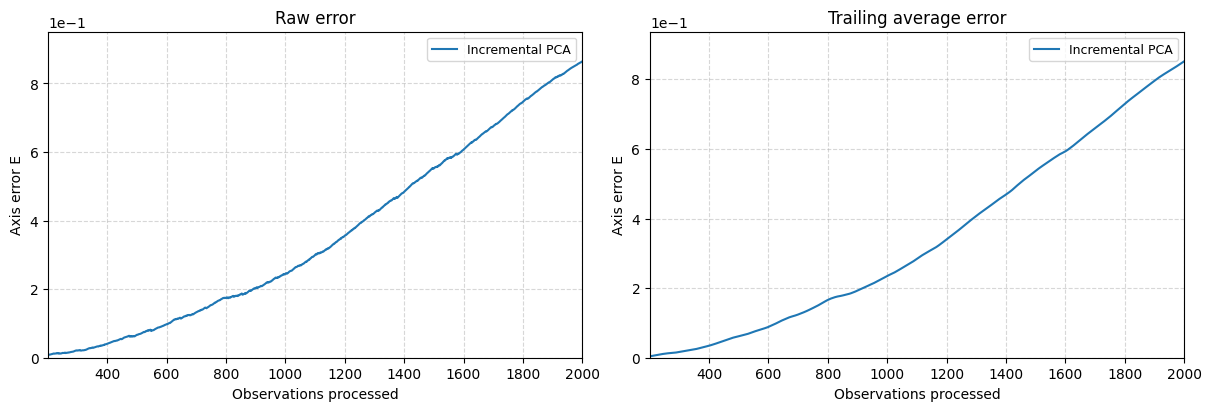

Incremental PCA cumulative error from observation 1: 638.1695895483756


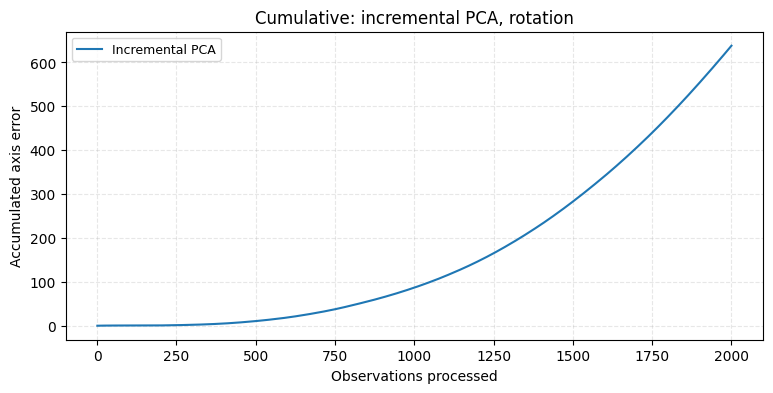

Incremental PCA tracking angle-error SD (degrees): 17.828009363530093


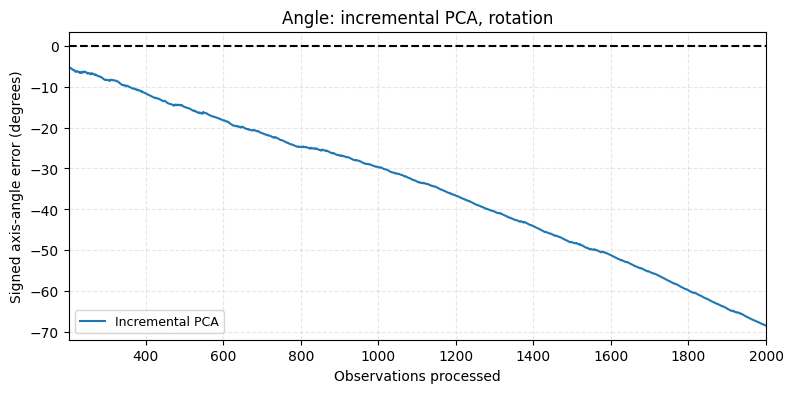

Incremental PCA mean captured variance after warm-up (%): 61.93744243499251


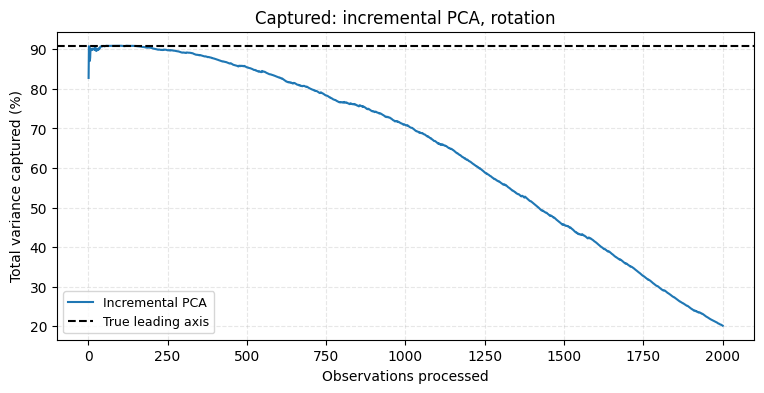

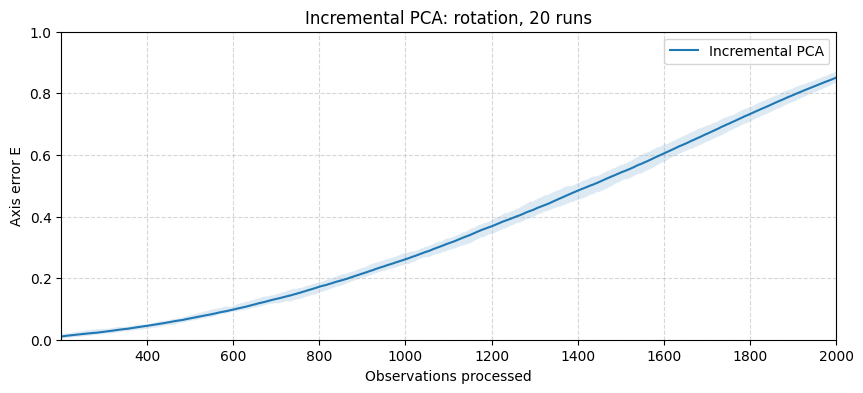

(<Figure size 1000x400 with 1 Axes>,
 <Axes: title={'center': 'Incremental PCA: rotation, 20 runs'}, xlabel='Observations processed', ylabel='Axis error E'>)

In [79]:
# Raw axis error and its trailing average: one seed, two panels.
ut.plot_stationary_errors(
    [incremental_rotation_errors], ['Incremental PCA'],
    warmup, smooth_window
)

# Accumulated raw error from observation 1, including the initial learning period.
total_curves = [np.cumsum(errors) for errors in [incremental_rotation_errors]]
labels = ['Incremental PCA']
for total_error, label in zip(total_curves, labels):
    print(label, 'cumulative error from observation 1:', total_error[-1])
ut.plot_cumulative_error(total_curves, labels,
                      'Cumulative: incremental PCA, rotation')

# Signed angular tracking error in degrees; SD excludes warm-up.
angle_curves = [axis_angle_error(directions, theta_rotation)
                for directions in [incremental_rotation_directions]]
labels = ['Incremental PCA']
for angles, label in zip(angle_curves, labels):
    print(label, 'tracking angle-error SD (degrees):', angles[warmup:].std())
ut.plot_angle_error(angle_curves, labels,
                 'Angle: incremental PCA, rotation', warmup)

# Ground-truth population variance captured by the estimated axis, as a percentage.
percent_curves = [100 * (lam1 - (lam1 - lam2) * errors) / (lam1 + lam2)
                  for errors in [incremental_rotation_errors]]
labels = ['Incremental PCA']
for percentages, label in zip(percent_curves, labels):
    print(label, 'mean captured variance after warm-up (%):',
          np.nanmean(percentages[warmup:]))
best_percent = 100 * lam1 / (lam1 + lam2)
ut.plot_captured_variance(percent_curves, labels,
                       'Captured: incremental PCA, rotation', best_percent)

# Across-seed mean raw error and 10th-90th percentile band, not a confidence interval.
ut.plot_repeated_errors(
    [incremental_rotation_runs], ['Incremental PCA'],
    'Incremental PCA: rotation, 20 runs', start=0, warmup=warmup, upper_limit=1
)

**Plots.**
- As before, the truncated component leaves the model with less information about the rotation, and lags even more than its cumulative counterpart, and more and more over time, compounding the effect.
- Raw error and trailing average: a steady rise with almost no noise, up to about 0.85 at the end (0.73 for cumulative). The two panels are almost identical, since there's no noise to smooth.
- Signed angle: a straight line falling to −68° (−59° for cumulative). It's also steeper.
- Captured variance: it falls steadily to about 20% at the end (30% for cumulative).

#### Repeated-run measurements

In [80]:
rows = []
runs = incremental_rotation_runs
label = 'Incremental PCA'
run_means = runs[:, warmup:].mean(axis=1)
mean_error = run_means.mean()
sd_error = run_means.std(ddof=1)
temporal_sd = runs[:, warmup:].std(axis=1).mean()
rows.append([label, f'{mean_error:.5f}', f'{sd_error:.5f}', f'{temporal_sd:.5f}'])
ut.show_table(['Method', 'Mean E', 'SD of run means', 'Mean temporal SD'], rows)

| Method | Mean E | SD of run means | Mean temporal SD |
| --- | --- | --- | --- |
| Incremental PCA | 0.35459 | 0.01312 | 0.25794 |


As with the two previous regimes, incremental PCA represents a lighter, but slower, update to the leading axis of rotation.

### Random drift data

In [81]:
directions, state = incremental_pca(X_drift)
incremental_drift_errors = axis_error(directions, truth_drift)
incremental_drift_directions = directions.copy()

#### Single-run measurements

In [82]:
rows = []
errors = incremental_drift_errors
label = 'Incremental PCA'
mean_error = errors[warmup:].mean()
temporal_sd = errors[warmup:].std()
rows.append([label, f'{mean_error:.5f}', f'{temporal_sd:.5f}'])
ut.show_table(['Method', 'Mean error after warm-up', 'Temporal error SD'], rows)

| Method | Mean error after warm-up | Temporal error SD |
| --- | --- | --- |
| Incremental PCA | 0.03947 | 0.04618 |


#### Repeat with 20 seeds

In [83]:
runs = []
runtimes = []
angles = []
for run_seed in seeds:
    X_run, theta_run, truth_run = drift_streams[run_seed]
    # Time only the PCA calculation, not generation or evaluation.
    start = time.perf_counter()
    directions, state = incremental_pca(X_run)
    runtimes.append(time.perf_counter() - start)
    runs.append(axis_error(directions, truth_run))
    angles.append(axis_angle_error(directions, theta_run))
incremental_drift_runs = np.array(runs)
incremental_drift_runtimes = np.array(runtimes)
incremental_drift_angles = np.array(angles)

save_results('Incremental PCA (rank-1 SVD)', 'drift',
             incremental_drift_runs, incremental_drift_runtimes,
             angle_runs=incremental_drift_angles, settings=drift_settings)

Saved Incremental PCA (rank-1 SVD), drift, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\baselines\pca_drift_results_Q=0.0001_dt=1.csv


#### Computational cost

In [84]:
rows = []
runtimes = incremental_drift_runtimes
label = 'Incremental PCA'
rows.append([label, runtimes.mean(), runtimes.min(), runtimes.max(), runtimes.std(ddof=1)])
ut.show_table(['Method', 'Mean seconds', 'Shortest seconds', 'Longest seconds', 'SD seconds'], rows)

| Method | Mean seconds | Shortest seconds | Longest seconds | SD seconds |
| --- | --- | --- | --- | --- |
| Incremental PCA | 0.43402390999544876 | 0.12114489998202771 | 1.4071755000040866 | 0.3715965523186305 |


#### Repeated-run plot

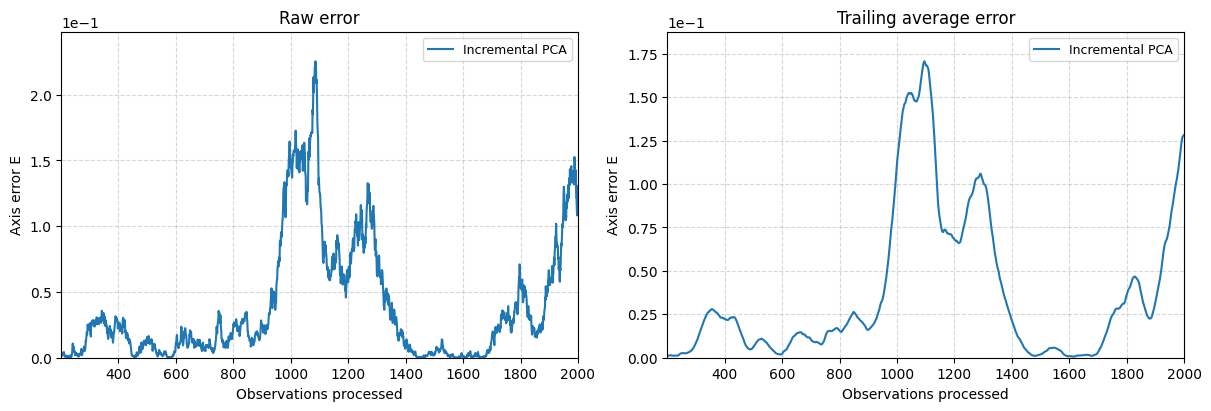

Incremental PCA cumulative error from observation 1: 72.7728118417549


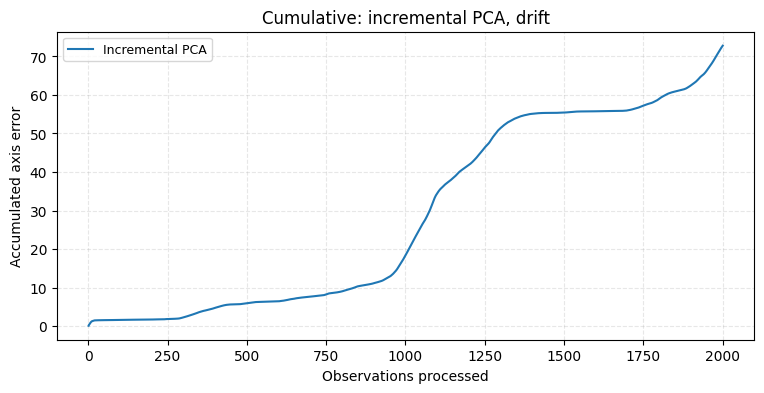

Incremental PCA tracking angle-error SD (degrees): 6.713508185853379


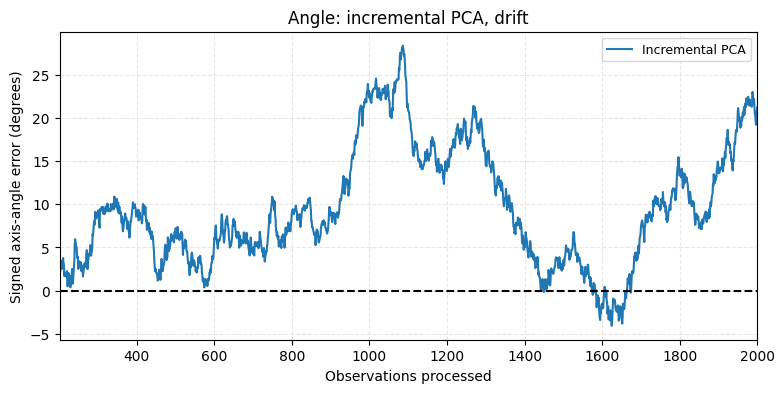

Incremental PCA mean captured variance after warm-up (%): 87.67958039863895


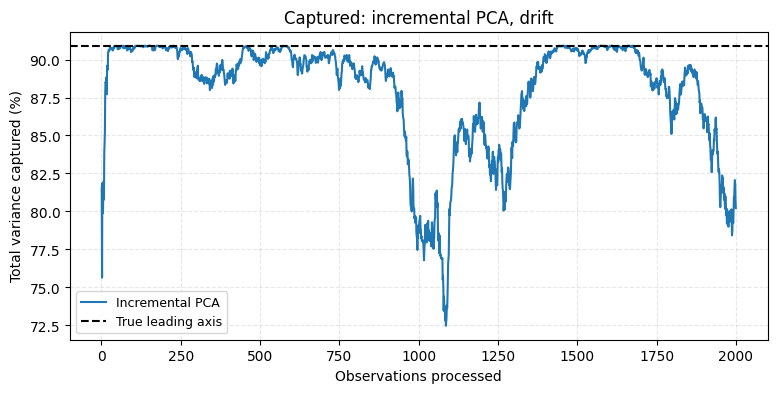

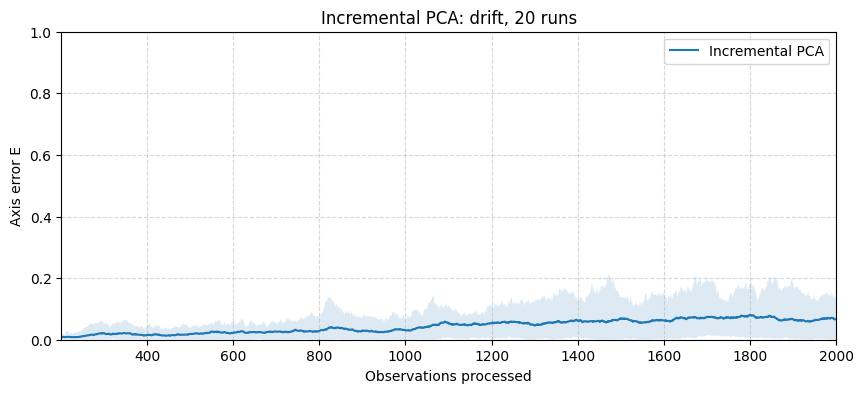

(<Figure size 1000x400 with 1 Axes>,
 <Axes: title={'center': 'Incremental PCA: drift, 20 runs'}, xlabel='Observations processed', ylabel='Axis error E'>)

In [85]:
# Raw axis error and its trailing average: one seed, two panels.
ut.plot_stationary_errors(
    [incremental_drift_errors], ['Incremental PCA'],
    warmup, smooth_window
)

# Accumulated raw error from observation 1, including the initial learning period.
total_curves = [np.cumsum(errors) for errors in [incremental_drift_errors]]
labels = ['Incremental PCA']
for total_error, label in zip(total_curves, labels):
    print(label, 'cumulative error from observation 1:', total_error[-1])
ut.plot_cumulative_error(total_curves, labels,
                      'Cumulative: incremental PCA, drift')

# Signed angular tracking error in degrees; SD excludes warm-up.
angle_curves = [axis_angle_error(directions, theta_drift)
                for directions in [incremental_drift_directions]]
labels = ['Incremental PCA']
for angles, label in zip(angle_curves, labels):
    print(label, 'tracking angle-error SD (degrees):', angles[warmup:].std())
ut.plot_angle_error(angle_curves, labels,
                 'Angle: incremental PCA, drift', warmup)

# Ground-truth population variance captured by the estimated axis, as a percentage.
percent_curves = [100 * (lam1 - (lam1 - lam2) * errors) / (lam1 + lam2)
                  for errors in [incremental_drift_errors]]
labels = ['Incremental PCA']
for percentages, label in zip(percent_curves, labels):
    print(label, 'mean captured variance after warm-up (%):',
          np.nanmean(percentages[warmup:]))
best_percent = 100 * lam1 / (lam1 + lam2)
ut.plot_captured_variance(percent_curves, labels,
                       'Captured: incremental PCA, drift', best_percent)

# Across-seed mean raw error and 10th-90th percentile band, not a confidence interval.
ut.plot_repeated_errors(
    [incremental_drift_runs], ['Incremental PCA'],
    'Incremental PCA: drift, 20 runs', start=0, warmup=warmup, upper_limit=1
)

**Plots.** Almost identical to cumulative PCA on this seed: with a direction that stays within $\sim25^\circ$ of its
average, the truncation changes little.

#### Repeated-run measurements

In [86]:
rows = []
runs = incremental_drift_runs
label = 'Incremental PCA'
run_means = runs[:, warmup:].mean(axis=1)
mean_error = run_means.mean()
sd_error = run_means.std(ddof=1)
temporal_sd = runs[:, warmup:].std(axis=1).mean()
rows.append([label, f'{mean_error:.5f}', f'{sd_error:.5f}', f'{temporal_sd:.5f}'])
ut.show_table(['Method', 'Mean E', 'SD of run means', 'Mean temporal SD'], rows)

| Method | Mean E | SD of run means | Mean temporal SD |
| --- | --- | --- | --- |
| Incremental PCA | 0.04376 | 0.02880 | 0.04348 |


### Results for this method

Mean axis error after warm-up over 20 seeds, against cumulative PCA (Section 1), which has the same weights.

| Method | Stationary | Abrupt, after the change | Abrupt, final segment | Recovered | Rotation | Drift |
|---|---|---|---|---|---|---|
| Cumulative PCA | 0.00014 | 0.488 | 0.276 | 0/20 | 0.296 | 0.0395 |
| Incremental PCA (rank-1 SVD) | 0.00015 | 0.562 | 0.419 | 0/20 | 0.355 | 0.0438 |

- **In stationary data truncation costs nothing**: the two methods have the same error, because the
  discarded component carries little information when the direction does not move.
- **When the direction moves, truncation makes things worse.** After the abrupt change the rank-1 update is
  further from the new direction than cumulative PCA ($0.562$ against $0.488$; final segment $0.419$
  against $0.276$), and the same holds in rotation and drift. The variance along the new direction falls
  in the discarded component at each step, so it cannot accumulate: only the part that rotates the
  retained axis is kept.
- **The implementation matches scikit-learn's `IncrementalPCA`** with one component on the abrupt streams
  (post-change error $0.5624$ against $0.5625$ in the earlier benchmark), although scikit-learn centres the
  data with the sample mean and uses a different update.
- **The same equal weights do not track**, as in Section 1: no run recovers after the change.
- **Angle (CSV).** In the final segment of the abrupt regime the rank-1 estimate is $40.4^\circ$ from the new
  direction, against $31.7^\circ$ for cumulative PCA; in rotation its mean lag is $-34.8^\circ$ against $-31.1^\circ$.

## 4. Rank-1 SVD PCA with fixed forgetting

The fixed gain of Section 2 combined with the rank-1 truncation of Section 3: old information is discounted by
$(1-\alpha)$ at every step, and only the leading axis and its variance are kept:

$$A_n=\operatorname{rank}_1\big((1-\alpha)A_{n-1}+\alpha\,x_nx_n^\top\big).$$

Each step is the step of Section 3 with the fixed $\alpha$ in place of $1/n$, and the gains are those of Section 2.
In 2D, with both components kept, this update is exactly the covariance update of
Section 2, so every difference between Sections 2 and 4 is due to truncation. As in Section 3, the variance
perpendicular to the current axis is discarded at every step and cannot be recovered. With forgetting, however, its
effect does not accumulate: like everything else in the estimate, it is discounted by $(1-\alpha)$ at every following
step.

**Sources.** Forgetting factor of Levy and Lindenbaum (2000) in the sequential SVD update, analysed by Ross et al.
(2008): it multiplies the retained singular values by $f$, i.e. the covariance by $f^2$, so here $f^2=1-\alpha$.
See `docs/literature_review.md`, Section 3.3.

### Stationary data

In [87]:
rank_one_svd_stationary_errors = {}
rank_one_svd_stationary_directions = {}
for alpha in gains:
    directions, covariance = rank1_svd_pca(X_stationary, alpha)
    rank_one_svd_stationary_directions[alpha] = directions.copy()
    errors = axis_error(directions, truth_stationary)
    rank_one_svd_stationary_errors[alpha] = errors

#### Single-run measurements

In [88]:
rows = []
for alpha in gains:
    errors = rank_one_svd_stationary_errors[alpha]
    label = f'alpha={alpha:g}'
    mean_error = errors[warmup:].mean()
    temporal_sd = errors[warmup:].std()
    rows.append([label, f'{mean_error:.5f}', f'{temporal_sd:.5f}'])
ut.show_table(['Method', 'Mean error after warm-up', 'Temporal error SD'], rows)

| Method | Mean error after warm-up | Temporal error SD |
| --- | --- | --- |
| alpha=0.005 | 0.00037 | 0.00061 |
| alpha=0.02 | 0.00118 | 0.00187 |
| alpha=0.1 | 0.00611 | 0.00901 |


#### Repeat with 20 seeds

Use a new stream for each seed. All baseline method sections use the same seed list. Rows in the saved array are runs, and columns are timesteps.

In [89]:
rank_one_svd_stationary_runs = {}
rank_one_svd_stationary_runtimes = {}
rank_one_svd_stationary_angles = {}
for alpha in gains:
    runs = []
    runtimes = []
    angles = []
    for run_seed in seeds:
        X_run, theta_run, truth_run = stationary_streams[run_seed]
        # Time only the PCA calculation, not generation or evaluation.
        start = time.perf_counter()
        directions, covariance = rank1_svd_pca(X_run, alpha)
        runtimes.append(time.perf_counter() - start)
        runs.append(axis_error(directions, truth_run))
        angles.append(axis_angle_error(directions, theta_run))
    rank_one_svd_stationary_runs[alpha] = np.array(runs)
    rank_one_svd_stationary_runtimes[alpha] = np.array(runtimes)
    rank_one_svd_stationary_angles[alpha] = np.array(angles)
    # Select this gain's arrays, rather than passing the entire dictionary.
    save_results('Rank-1 SVD PCA with fixed forgetting', 'stationary',
                 rank_one_svd_stationary_runs[alpha], rank_one_svd_stationary_runtimes[alpha],
                 alpha=alpha, angle_runs=rank_one_svd_stationary_angles[alpha], settings=benchmark_settings)

Saved Rank-1 SVD PCA with fixed forgetting, stationary, alpha=0.005 to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\baselines\pca_benchmark_results.csv
Saved Rank-1 SVD PCA with fixed forgetting, stationary, alpha=0.02 to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\baselines\pca_benchmark_results.csv
Saved Rank-1 SVD PCA with fixed forgetting, stationary, alpha=0.1 to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\baselines\pca_benchmark_results.csv


#### Computational cost

In [90]:
rows = []
for alpha in gains:
    runtimes = rank_one_svd_stationary_runtimes[alpha]
    label = f'alpha={alpha:g}'
    rows.append([label, runtimes.mean(), runtimes.min(), runtimes.max(), runtimes.std(ddof=1)])
ut.show_table(['Method', 'Mean seconds', 'Shortest seconds', 'Longest seconds', 'SD seconds'], rows)

| Method | Mean seconds | Shortest seconds | Longest seconds | SD seconds |
| --- | --- | --- | --- | --- |
| alpha=0.005 | 0.9049431549996371 | 0.27098109998041764 | 2.3058797999983653 | 0.5134782603884135 |
| alpha=0.02 | 0.9273741649987641 | 0.6730293000000529 | 1.4400551000144333 | 0.21604942847625025 |
| alpha=0.1 | 0.7960367649997352 | 0.5077834999538027 | 1.1695266999886371 | 0.16221784884706286 |


#### Repeated-run plot

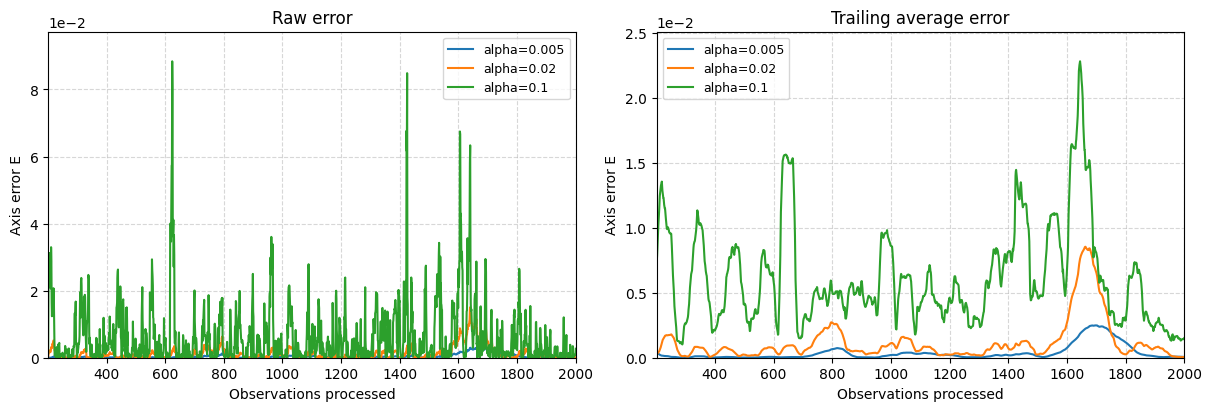

alpha=0.005 cumulative error from observation 1: 1.5147355986497009
alpha=0.02 cumulative error from observation 1: 2.9000466658483366
alpha=0.1 cumulative error from observation 1: 12.495277494088418


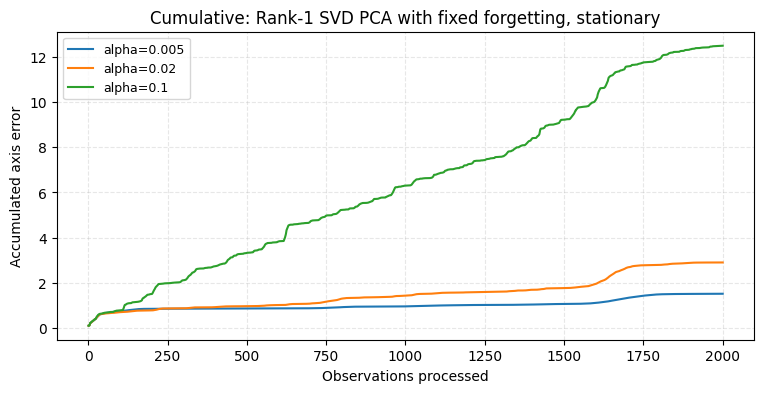

alpha=0.005 stationary angle SD (degrees): 0.7974851652472474
alpha=0.02 stationary angle SD (degrees): 1.780767852490265
alpha=0.1 stationary angle SD (degrees): 4.403136573805457


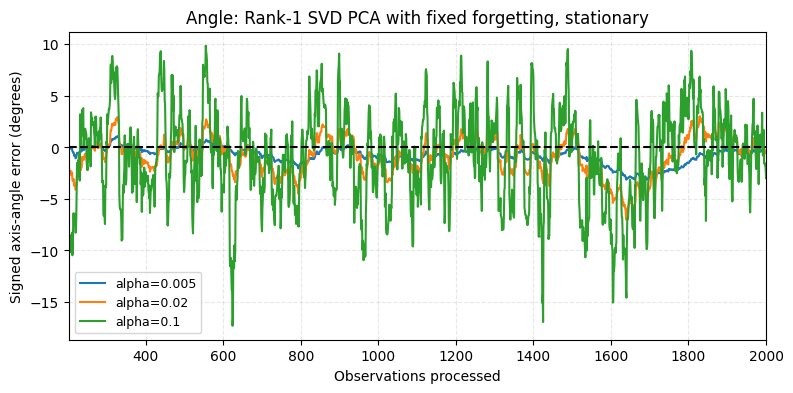

alpha=0.005 mean captured variance after warm-up (%): 90.87884289360098
alpha=0.02 mean captured variance after warm-up (%): 90.81257464319211
alpha=0.1 mean captured variance after warm-up (%): 90.40950419862017


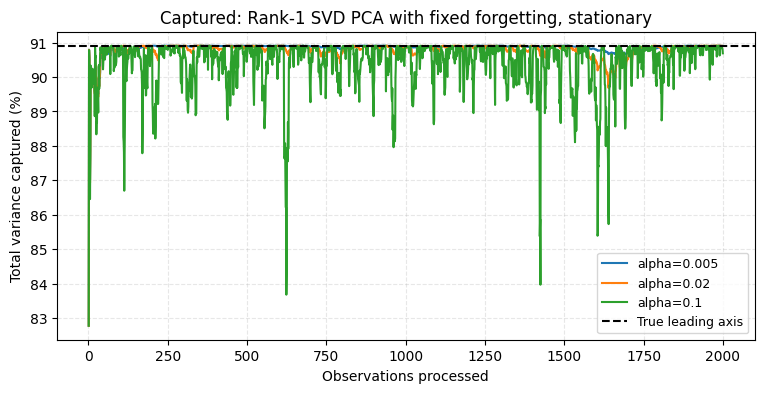

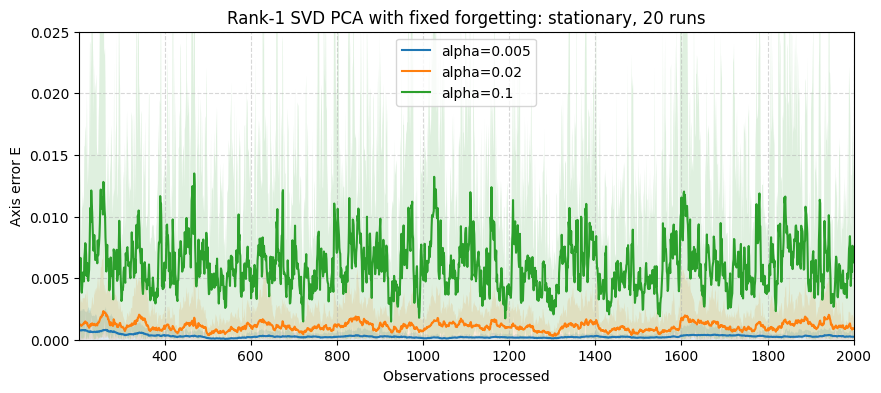

(<Figure size 1000x400 with 1 Axes>,
 <Axes: title={'center': 'Rank-1 SVD PCA with fixed forgetting: stationary, 20 runs'}, xlabel='Observations processed', ylabel='Axis error E'>)

In [91]:
# Raw axis error and its trailing average: one seed, two panels.
ut.plot_stationary_errors(
    [rank_one_svd_stationary_errors[alpha] for alpha in gains],
    [f'alpha={alpha:g}' for alpha in gains],
    warmup, smooth_window
)

# Accumulated raw error from observation 1, including the initial learning period.
total_curves = [np.cumsum(errors) for errors in [rank_one_svd_stationary_errors[alpha] for alpha in gains]]
labels = [f'alpha={alpha:g}' for alpha in gains]
for total_error, label in zip(total_curves, labels):
    print(label, 'cumulative error from observation 1:', total_error[-1])
ut.plot_cumulative_error(total_curves, labels,
                      'Cumulative: Rank-1 SVD PCA with fixed forgetting, stationary')

# Signed angular error in degrees; stationary SD excludes warm-up and any jump.
angle_curves = [axis_angle_error(directions, theta_stationary)
                for directions in [rank_one_svd_stationary_directions[alpha] for alpha in gains]]
labels = [f'alpha={alpha:g}' for alpha in gains]
for angles, label in zip(angle_curves, labels):
    print(label, 'stationary angle SD (degrees):', angles[warmup:].std())
ut.plot_angle_error(angle_curves, labels,
                 'Angle: Rank-1 SVD PCA with fixed forgetting, stationary', warmup)

# Ground-truth population variance captured by the estimated axis, as a percentage.
percent_curves = [100 * (lam1 - (lam1 - lam2) * errors) / (lam1 + lam2)
                  for errors in [rank_one_svd_stationary_errors[alpha] for alpha in gains]]
labels = [f'alpha={alpha:g}' for alpha in gains]
for percentages, label in zip(percent_curves, labels):
    print(label, 'mean captured variance after warm-up (%):',
          np.nanmean(percentages[warmup:]))
best_percent = 100 * lam1 / (lam1 + lam2)
ut.plot_captured_variance(percent_curves, labels,
                       'Captured: Rank-1 SVD PCA with fixed forgetting, stationary', best_percent)

# Across-seed mean raw error and 10th-90th percentile band, not a confidence interval.
ut.plot_repeated_errors(
    [rank_one_svd_stationary_runs[alpha] for alpha in gains], [f'alpha={alpha:g}' for alpha in gains],
    'Rank-1 SVD PCA with fixed forgetting: stationary, 20 runs', start=0, warmup=warmup, upper_limit=0.025
)

**Plots.** Almost identical to forgetting PCA. The spikes of $\alpha=0.1$ are a little smaller (raw error up to
$0.09$ against $0.13$; captured variance down to $84\%$ against $81\%$).

#### Repeated-run measurements

In [92]:
rows = []
for alpha in gains:
    runs = rank_one_svd_stationary_runs[alpha]
    label = f'alpha={alpha:g}'
    run_means = runs[:, warmup:].mean(axis=1)
    mean_error = run_means.mean()
    sd_error = run_means.std(ddof=1)
    temporal_sd = runs[:, warmup:].std(axis=1).mean()
    rows.append([label, f'{mean_error:.5f}', f'{sd_error:.5f}', f'{temporal_sd:.5f}'])
ut.show_table(['Method', 'Mean E', 'SD of run means', 'Mean temporal SD'], rows)

| Method | Mean E | SD of run means | Mean temporal SD |
| --- | --- | --- | --- |
| alpha=0.005 | 0.00027 | 0.00012 | 0.00037 |
| alpha=0.02 | 0.00108 | 0.00033 | 0.00148 |
| alpha=0.1 | 0.00608 | 0.00077 | 0.00913 |


### Abrupt-change data

In [93]:
rank_one_svd_abrupt_errors = {}
rank_one_svd_abrupt_directions = {}
for alpha in gains:
    directions, covariance = rank1_svd_pca(X_abrupt, alpha)
    rank_one_svd_abrupt_directions[alpha] = directions.copy()
    errors = axis_error(directions, truth_abrupt)
    rank_one_svd_abrupt_errors[alpha] = errors

#### Single-run measurements

In [94]:
rows = []
for alpha in gains:
    errors = rank_one_svd_abrupt_errors[alpha]
    label = f'alpha={alpha:g}'
    pre_error = errors[warmup:switch_step].mean()
    post_error = errors[switch_step:].mean()
    final_error = errors[-warmup:].mean()
    delay = recovery_delay(errors, switch_step, threshold=recovery_threshold, window=smooth_window, hold=recovery_hold)
    rows.append([label, f'{pre_error:.5f}', f'{post_error:.5f}', f'{final_error:.5f}', delay])
ut.show_table(['Method', 'Pre-change mean E', 'Post-change mean E', 'Final-segment mean E', 'Recovery delay'], rows)

| Method | Pre-change mean E | Post-change mean E | Final-segment mean E | Recovery delay |
| --- | --- | --- | --- | --- |
| alpha=0.005 | 0.00013 | 0.14353 | 0.00109 | 429.0 |
| alpha=0.02 | 0.00082 | 0.03600 | 0.00055 | 130.0 |
| alpha=0.1 | 0.00600 | 0.01200 | 0.00297 | 58.0 |


#### Repeat with 20 seeds

Use a new stream for each seed. All baseline method sections use the same seed list. Rows in the saved array are runs, and columns are timesteps.

In [95]:
rank_one_svd_abrupt_runs = {}
rank_one_svd_abrupt_runtimes = {}
rank_one_svd_abrupt_angles = {}
for alpha in gains:
    runs = []
    runtimes = []
    angles = []
    for run_seed in seeds:
        X_run, theta_run, truth_run = abrupt_streams[run_seed]
        # Time only the PCA calculation, not generation or evaluation.
        start = time.perf_counter()
        directions, covariance = rank1_svd_pca(X_run, alpha)
        runtimes.append(time.perf_counter() - start)
        runs.append(axis_error(directions, truth_run))
        angles.append(axis_angle_error(directions, theta_run))
    rank_one_svd_abrupt_runs[alpha] = np.array(runs)
    rank_one_svd_abrupt_runtimes[alpha] = np.array(runtimes)
    rank_one_svd_abrupt_angles[alpha] = np.array(angles)
    # Select this gain's arrays, rather than passing the entire dictionary.
    save_results('Rank-1 SVD PCA with fixed forgetting', 'abrupt',
                 rank_one_svd_abrupt_runs[alpha], rank_one_svd_abrupt_runtimes[alpha],
                 alpha=alpha, angle_runs=rank_one_svd_abrupt_angles[alpha], settings=benchmark_settings)

Saved Rank-1 SVD PCA with fixed forgetting, abrupt, alpha=0.005 to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\baselines\pca_benchmark_results.csv
Saved Rank-1 SVD PCA with fixed forgetting, abrupt, alpha=0.02 to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\baselines\pca_benchmark_results.csv
Saved Rank-1 SVD PCA with fixed forgetting, abrupt, alpha=0.1 to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\baselines\pca_benchmark_results.csv


#### Computational cost

In [96]:
rows = []
for alpha in gains:
    runtimes = rank_one_svd_abrupt_runtimes[alpha]
    label = f'alpha={alpha:g}'
    rows.append([label, runtimes.mean(), runtimes.min(), runtimes.max(), runtimes.std(ddof=1)])
ut.show_table(['Method', 'Mean seconds', 'Shortest seconds', 'Longest seconds', 'SD seconds'], rows)

| Method | Mean seconds | Shortest seconds | Longest seconds | SD seconds |
| --- | --- | --- | --- | --- |
| alpha=0.005 | 0.20741419500263875 | 0.11359409999568015 | 0.9076240999856964 | 0.17369247318180345 |
| alpha=0.02 | 0.2761357349983882 | 0.13195700000505894 | 1.3110646000131965 | 0.2772341350106452 |
| alpha=0.1 | 0.1868918899912387 | 0.12832679995335639 | 0.7145297999959439 | 0.13552876522998963 |


#### Repeated-run plot

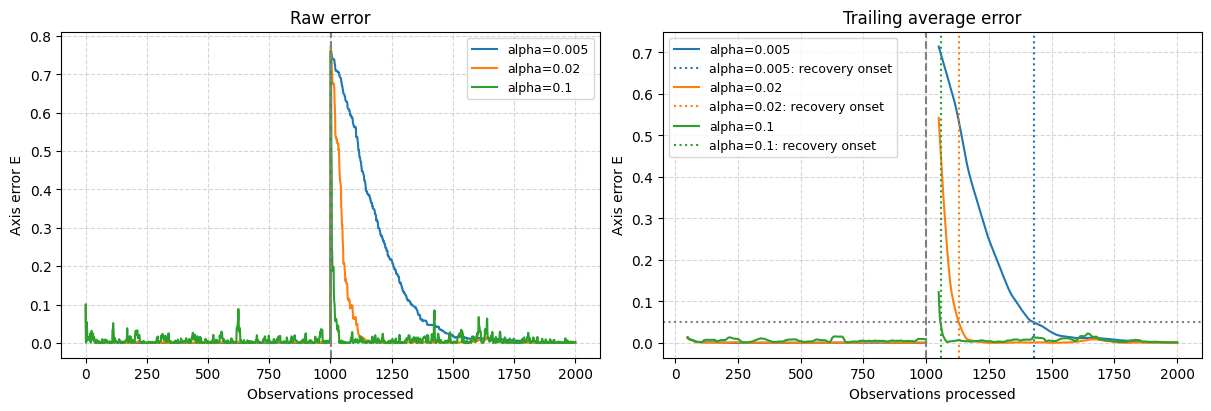

alpha=0.005 cumulative error from observation 1: 144.48756416967248
alpha=0.02 cumulative error from observation 1: 37.438677046283225
alpha=0.1 cumulative error from observation 1: 18.30123465644345


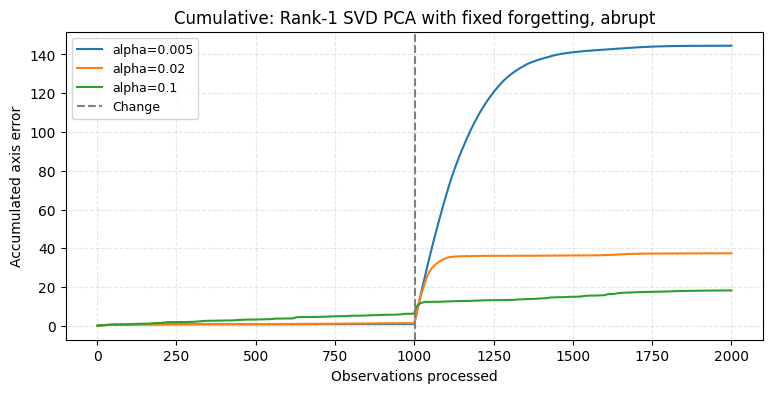

alpha=0.005 stationary angle SD (degrees): 0.570064129453741
alpha=0.02 stationary angle SD (degrees): 1.5097128275091576
alpha=0.1 stationary angle SD (degrees): 4.368645541978875


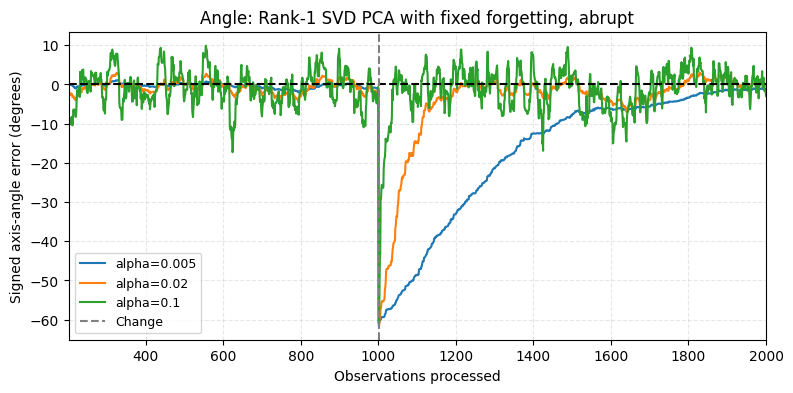

alpha=0.005 mean captured variance after warm-up (%): 84.38007795855448
alpha=0.02 mean captured variance after warm-up (%): 89.24263689862688
alpha=0.1 mean captured variance after warm-up (%): 90.14559705487677


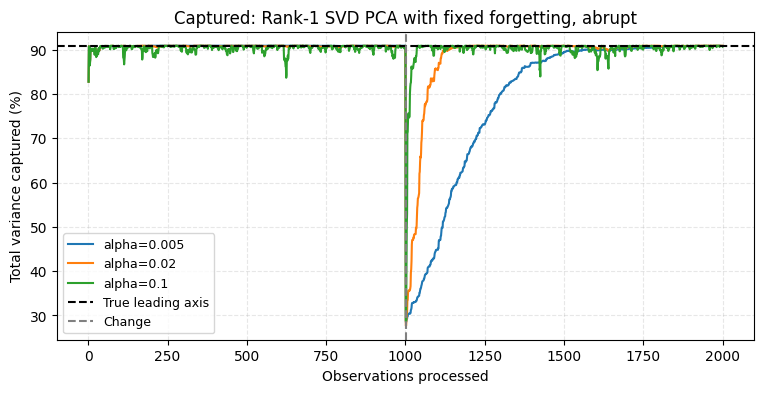

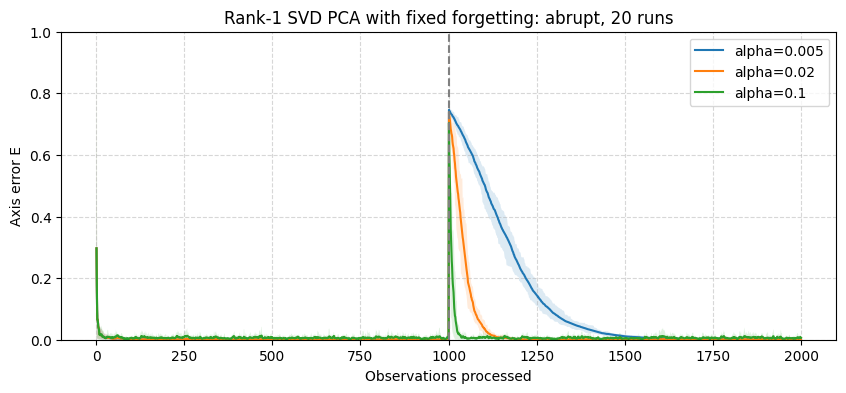

(<Figure size 1000x400 with 1 Axes>,
 <Axes: title={'center': 'Rank-1 SVD PCA with fixed forgetting: abrupt, 20 runs'}, xlabel='Observations processed', ylabel='Axis error E'>)

In [97]:
# Raw axis error and its trailing average: one seed, two panels.
ut.plot_abrupt_errors(
    [rank_one_svd_abrupt_errors[alpha] for alpha in gains],
    [f'alpha={alpha:g}' for alpha in gains],
    switch_step, smooth_window, recovery_threshold, recovery_hold
)

# Accumulated raw error from observation 1, including the initial learning period.
total_curves = [np.cumsum(errors) for errors in [rank_one_svd_abrupt_errors[alpha] for alpha in gains]]
labels = [f'alpha={alpha:g}' for alpha in gains]
for total_error, label in zip(total_curves, labels):
    print(label, 'cumulative error from observation 1:', total_error[-1])
ut.plot_cumulative_error(total_curves, labels,
                      'Cumulative: Rank-1 SVD PCA with fixed forgetting, abrupt', switch_step=switch_step)

# Signed angular error in degrees; stationary SD excludes warm-up and any jump.
angle_curves = [axis_angle_error(directions, theta_abrupt)
                for directions in [rank_one_svd_abrupt_directions[alpha] for alpha in gains]]
labels = [f'alpha={alpha:g}' for alpha in gains]
for angles, label in zip(angle_curves, labels):
    print(label, 'stationary angle SD (degrees):', angles[warmup:switch_step].std())
ut.plot_angle_error(angle_curves, labels,
                 'Angle: Rank-1 SVD PCA with fixed forgetting, abrupt', warmup, switch_step=switch_step)

# Ground-truth population variance captured by the estimated axis, as a percentage.
percent_curves = [100 * (lam1 - (lam1 - lam2) * errors) / (lam1 + lam2)
                  for errors in [rank_one_svd_abrupt_errors[alpha] for alpha in gains]]
labels = [f'alpha={alpha:g}' for alpha in gains]
for percentages, label in zip(percent_curves, labels):
    print(label, 'mean captured variance after warm-up (%):',
          np.nanmean(percentages[warmup:]))
best_percent = 100 * lam1 / (lam1 + lam2)
ut.plot_captured_variance(percent_curves, labels,
                       'Captured: Rank-1 SVD PCA with fixed forgetting, abrupt', best_percent, switch_step=switch_step)

# Across-seed mean raw error and 10th-90th percentile band, not a confidence interval.
ut.plot_repeated_errors(
    [rank_one_svd_abrupt_runs[alpha] for alpha in gains], [f'alpha={alpha:g}' for alpha in gains],
    'Rank-1 SVD PCA with fixed forgetting: abrupt, 20 runs', start=0, switch_step=switch_step, upper_limit=1
)

**Plots.** Same pattern as forgetting PCA, but slower. Every gain returns to the new axis, but more slowly, especially
$\alpha=0.005$ (cumulative error $144.5$ against $103.8$).

#### Repeated-run measurements

Read the median recovery delay together with the recovered-run count: the median includes only runs that recovered.

In [98]:
rows = []
for alpha in gains:
    runs = rank_one_svd_abrupt_runs[alpha]
    label = f'alpha={alpha:g}'
    pre_means = runs[:, warmup:switch_step].mean(axis=1)
    post_means = runs[:, switch_step:].mean(axis=1)
    final_means = runs[:, -warmup:].mean(axis=1)
    delays = []
    for errors in runs:
        delays.append(recovery_delay(errors, switch_step, threshold=recovery_threshold, window=smooth_window, hold=recovery_hold))
    delays = np.array(delays)
    recovered = np.isfinite(delays)
    median_delay = 'Not confirmed'
    if recovered.any():
        median_delay = float(np.median(delays[recovered]))
    rows.append([label,
                 f'{pre_means.mean():.5f} +/- {pre_means.std(ddof=1):.5f}',
                 f'{post_means.mean():.5f} +/- {post_means.std(ddof=1):.5f}',
                 f'{final_means.mean():.5f} +/- {final_means.std(ddof=1):.5f}',
                 f'{recovered.sum()}/{len(delays)}', median_delay])
ut.show_table(['Method', 'Pre-change E: mean +/- SD', 'Post-change E: mean +/- SD', 'Final E: mean +/- SD', 'Recovered runs', 'Median delay'], rows)

| Method | Pre-change E: mean +/- SD | Post-change E: mean +/- SD | Final E: mean +/- SD | Recovered runs | Median delay |
| --- | --- | --- | --- | --- | --- |
| alpha=0.005 | 0.00031 +/- 0.00015 | 0.12400 +/- 0.01069 | 0.00063 +/- 0.00052 | 20/20 | 374.5 |
| alpha=0.02 | 0.00109 +/- 0.00041 | 0.03146 +/- 0.00567 | 0.00122 +/- 0.00109 | 20/20 | 116.0 |
| alpha=0.1 | 0.00617 +/- 0.00124 | 0.01158 +/- 0.00313 | 0.00636 +/- 0.00248 | 20/20 | 56.0 |


Every seed recovers, as with forgetting PCA, but later: median delay $56$, $116$, $374.5$
against $53.5$, $91.5$, $260.5$, and post-change error $0.0116$, $0.0315$, $0.124$ against $0.0110$, $0.0234$, $0.0894$. The variance of the new direction cannot accumulate (as in Section 3), but the old regime is still forgotten, so the
estimate recovers: truncation slows it down without stopping it. The slower the gain, the larger the cost.

### Smooth rotation data

In [99]:
rank_one_svd_rotation_errors = {}
rank_one_svd_rotation_directions = {}
for alpha in gains:
    directions, covariance = rank1_svd_pca(X_rotation, alpha)
    rank_one_svd_rotation_directions[alpha] = directions.copy()
    errors = axis_error(directions, truth_rotation)
    rank_one_svd_rotation_errors[alpha] = errors

#### Single-run measurements

In [100]:
rows = []
for alpha in gains:
    errors = rank_one_svd_rotation_errors[alpha]
    label = f'alpha={alpha:g}'
    mean_error = errors[warmup:].mean()
    temporal_sd = errors[warmup:].std()
    rows.append([label, f'{mean_error:.5f}', f'{temporal_sd:.5f}'])
ut.show_table(['Method', 'Mean error after warm-up', 'Temporal error SD'], rows)

| Method | Mean error after warm-up | Temporal error SD |
| --- | --- | --- |
| alpha=0.005 | 0.04584 | 0.01630 |
| alpha=0.02 | 0.00580 | 0.00510 |
| alpha=0.1 | 0.00656 | 0.00993 |


#### Repeat with 20 seeds

Use the shared stream stored for each seed. All baseline method sections use the same seed list. Rows in the saved array are runs, and columns are timesteps.

In [101]:
rank_one_svd_rotation_runs = {}
rank_one_svd_rotation_runtimes = {}
rank_one_svd_rotation_angles = {}
for alpha in gains:
    runs = []
    runtimes = []
    angles = []
    for run_seed in seeds:
        X_run, theta_run, truth_run = rotation_streams[run_seed]
        # Time only the PCA calculation, not generation or evaluation.
        start = time.perf_counter()
        directions, covariance = rank1_svd_pca(X_run, alpha)
        runtimes.append(time.perf_counter() - start)
        runs.append(axis_error(directions, truth_run))
        angles.append(axis_angle_error(directions, theta_run))
    rank_one_svd_rotation_runs[alpha] = np.array(runs)
    rank_one_svd_rotation_runtimes[alpha] = np.array(runtimes)
    rank_one_svd_rotation_angles[alpha] = np.array(angles)
    # Select this gain's arrays, rather than passing the entire dictionary.
    save_results('Rank-1 SVD PCA with fixed forgetting', 'rotation',
                 rank_one_svd_rotation_runs[alpha], rank_one_svd_rotation_runtimes[alpha],
                 alpha=alpha, angle_runs=rank_one_svd_rotation_angles[alpha], settings=rotation_settings)

Saved Rank-1 SVD PCA with fixed forgetting, rotation, alpha=0.005 to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\baselines\pca_rotation_results_omega=0.001_dt=1.csv
Saved Rank-1 SVD PCA with fixed forgetting, rotation, alpha=0.02 to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\baselines\pca_rotation_results_omega=0.001_dt=1.csv
Saved Rank-1 SVD PCA with fixed forgetting, rotation, alpha=0.1 to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\baselines\pca_rotation_results_omega=0.001_dt=1.csv


#### Computational cost

In [102]:
rows = []
for alpha in gains:
    runtimes = rank_one_svd_rotation_runtimes[alpha]
    label = f'alpha={alpha:g}'
    rows.append([label, runtimes.mean(), runtimes.min(), runtimes.max(), runtimes.std(ddof=1)])
ut.show_table(['Method', 'Mean seconds', 'Shortest seconds', 'Longest seconds', 'SD seconds'], rows)

| Method | Mean seconds | Shortest seconds | Longest seconds | SD seconds |
| --- | --- | --- | --- | --- |
| alpha=0.005 | 0.16504448500636498 | 0.10693230002652854 | 0.5613498000311665 | 0.10208873157249858 |
| alpha=0.02 | 0.18508834501262755 | 0.10592090000864118 | 0.9640436999616213 | 0.18647647748101942 |
| alpha=0.1 | 0.17315507500316016 | 0.09863140003290027 | 0.6485614000121132 | 0.12834529038990264 |


#### Repeated-run plot

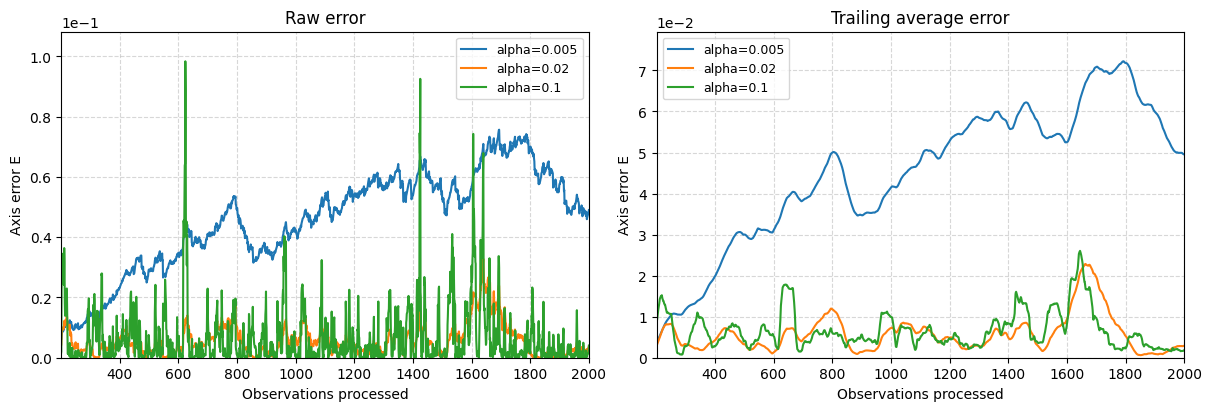

alpha=0.005 cumulative error from observation 1: 83.27695032616768
alpha=0.02 cumulative error from observation 1: 11.16815910533163
alpha=0.1 cumulative error from observation 1: 13.342215433033939


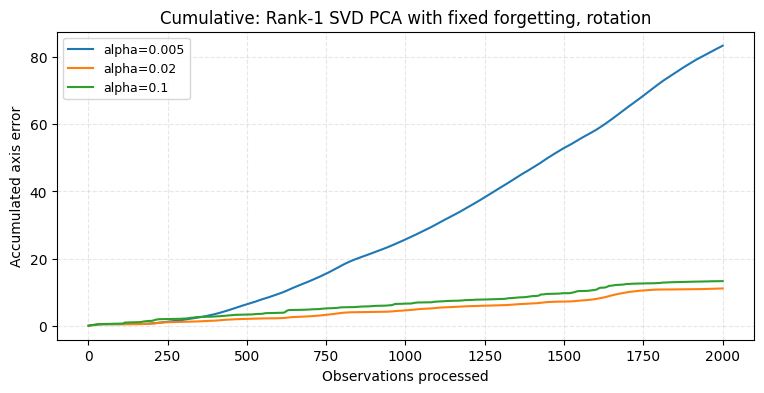

alpha=0.005 tracking angle-error SD (degrees): 2.494287643778277
alpha=0.02 tracking angle-error SD (degrees): 1.8358614047453465
alpha=0.1 tracking angle-error SD (degrees): 4.413635593230022


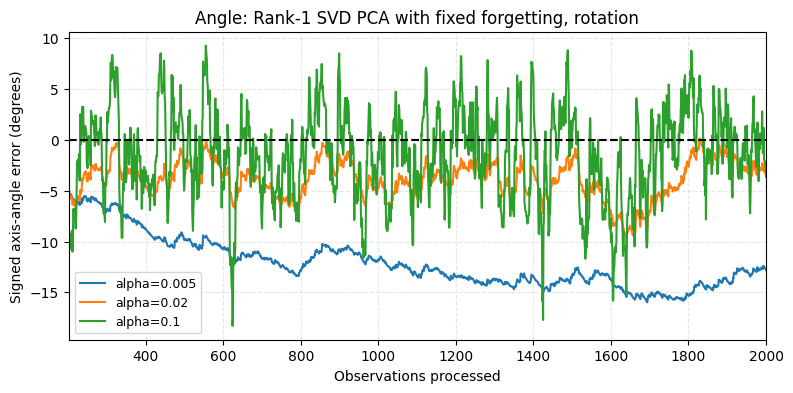

alpha=0.005 mean captured variance after warm-up (%): 87.15834352841831
alpha=0.02 mean captured variance after warm-up (%): 90.4342564968626
alpha=0.1 mean captured variance after warm-up (%): 90.37269820773437


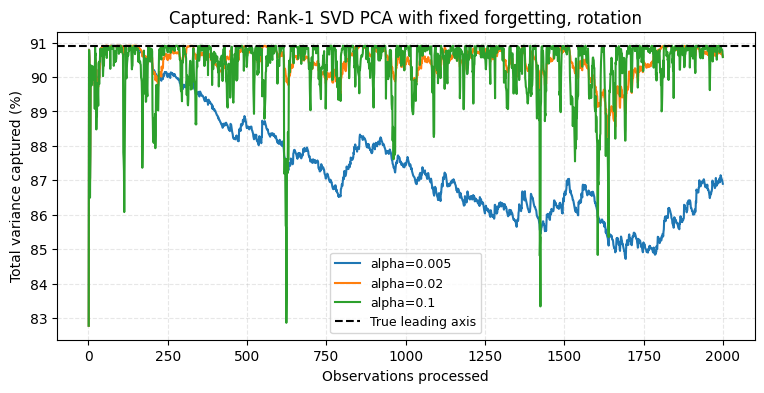

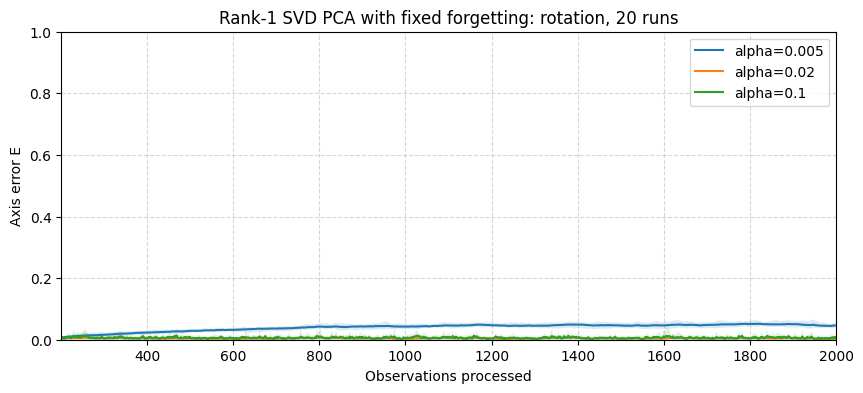

(<Figure size 1000x400 with 1 Axes>,
 <Axes: title={'center': 'Rank-1 SVD PCA with fixed forgetting: rotation, 20 runs'}, xlabel='Observations processed', ylabel='Axis error E'>)

In [103]:
# Raw axis error and its trailing average: one seed, two panels.
ut.plot_stationary_errors(
    [rank_one_svd_rotation_errors[alpha] for alpha in gains],
    [f'alpha={alpha:g}' for alpha in gains],
    warmup, smooth_window
)

# Accumulated raw error from observation 1, including the initial learning period.
total_curves = [np.cumsum(errors) for errors in [rank_one_svd_rotation_errors[alpha] for alpha in gains]]
labels = [f'alpha={alpha:g}' for alpha in gains]
for total_error, label in zip(total_curves, labels):
    print(label, 'cumulative error from observation 1:', total_error[-1])
ut.plot_cumulative_error(total_curves, labels,
                      'Cumulative: Rank-1 SVD PCA with fixed forgetting, rotation')

# Signed angular tracking error in degrees; SD excludes warm-up.
angle_curves = [axis_angle_error(directions, theta_rotation)
                for directions in [rank_one_svd_rotation_directions[alpha] for alpha in gains]]
labels = [f'alpha={alpha:g}' for alpha in gains]
for angles, label in zip(angle_curves, labels):
    print(label, 'tracking angle-error SD (degrees):', angles[warmup:].std())
ut.plot_angle_error(angle_curves, labels,
                 'Angle: Rank-1 SVD PCA with fixed forgetting, rotation', warmup)

# Ground-truth population variance captured by the estimated axis, as a percentage.
percent_curves = [100 * (lam1 - (lam1 - lam2) * errors) / (lam1 + lam2)
                  for errors in [rank_one_svd_rotation_errors[alpha] for alpha in gains]]
labels = [f'alpha={alpha:g}' for alpha in gains]
for percentages, label in zip(percent_curves, labels):
    print(label, 'mean captured variance after warm-up (%):',
          np.nanmean(percentages[warmup:]))
best_percent = 100 * lam1 / (lam1 + lam2)
ut.plot_captured_variance(percent_curves, labels,
                       'Captured: Rank-1 SVD PCA with fixed forgetting, rotation', best_percent)

# Across-seed mean raw error and 10th-90th percentile band, not a confidence interval.
ut.plot_repeated_errors(
    [rank_one_svd_rotation_runs[alpha] for alpha in gains], [f'alpha={alpha:g}' for alpha in gains],
    'Rank-1 SVD PCA with fixed forgetting: rotation, 20 runs', start=0, warmup=warmup, upper_limit=1
)

**Plots.** Same picture as forgetting PCA: the slow gain lags a little more ($12^\circ$–$15^\circ$), the fast gain is a
little less noisy.

#### Repeated-run measurements

In [104]:
rows = []
for alpha in gains:
    runs = rank_one_svd_rotation_runs[alpha]
    label = f'alpha={alpha:g}'
    run_means = runs[:, warmup:].mean(axis=1)
    mean_error = run_means.mean()
    sd_error = run_means.std(ddof=1)
    temporal_sd = runs[:, warmup:].std(axis=1).mean()
    rows.append([label, f'{mean_error:.5f}', f'{sd_error:.5f}', f'{temporal_sd:.5f}'])
ut.show_table(['Method', 'Mean E', 'SD of run means', 'Mean temporal SD'], rows)

| Method | Mean E | SD of run means | Mean temporal SD |
| --- | --- | --- | --- |
| alpha=0.005 | 0.04011 | 0.00292 | 0.01258 |
| alpha=0.02 | 0.00428 | 0.00103 | 0.00402 |
| alpha=0.1 | 0.00622 | 0.00087 | 0.00937 |


Truncation helps where noise dominates and hurts where lag dominates: rank-1 is better for
$\alpha=0.1$ ($0.00622$ against $0.00693$) and worse for $\alpha=0.02$ and $0.005$ ($0.00428$ and $0.0401$ against
$0.00383$ and $0.0314$).

### Random drift data

In [105]:
rank_one_svd_drift_errors = {}
rank_one_svd_drift_directions = {}
for alpha in gains:
    directions, covariance = rank1_svd_pca(X_drift, alpha)
    rank_one_svd_drift_directions[alpha] = directions.copy()
    errors = axis_error(directions, truth_drift)
    rank_one_svd_drift_errors[alpha] = errors

#### Single-run measurements

In [106]:
rows = []
for alpha in gains:
    errors = rank_one_svd_drift_errors[alpha]
    label = f'alpha={alpha:g}'
    mean_error = errors[warmup:].mean()
    temporal_sd = errors[warmup:].std()
    rows.append([label, f'{mean_error:.5f}', f'{temporal_sd:.5f}'])
ut.show_table(['Method', 'Mean error after warm-up', 'Temporal error SD'], rows)

| Method | Mean error after warm-up | Temporal error SD |
| --- | --- | --- |
| alpha=0.005 | 0.01404 | 0.01869 |
| alpha=0.02 | 0.00536 | 0.00807 |
| alpha=0.1 | 0.00778 | 0.01209 |


#### Repeat with 20 seeds

Use the shared stream stored for each seed. All baseline method sections use the same seed list. Rows in the saved array are runs, and columns are timesteps.

In [107]:
rank_one_svd_drift_runs = {}
rank_one_svd_drift_runtimes = {}
rank_one_svd_drift_angles = {}
for alpha in gains:
    runs = []
    runtimes = []
    angles = []
    for run_seed in seeds:
        X_run, theta_run, truth_run = drift_streams[run_seed]
        # Time only the PCA calculation, not generation or evaluation.
        start = time.perf_counter()
        directions, covariance = rank1_svd_pca(X_run, alpha)
        runtimes.append(time.perf_counter() - start)
        runs.append(axis_error(directions, truth_run))
        angles.append(axis_angle_error(directions, theta_run))
    rank_one_svd_drift_runs[alpha] = np.array(runs)
    rank_one_svd_drift_runtimes[alpha] = np.array(runtimes)
    rank_one_svd_drift_angles[alpha] = np.array(angles)
    # Select this gain's arrays, rather than passing the entire dictionary.
    save_results('Rank-1 SVD PCA with fixed forgetting', 'drift',
                 rank_one_svd_drift_runs[alpha], rank_one_svd_drift_runtimes[alpha],
                 alpha=alpha, angle_runs=rank_one_svd_drift_angles[alpha], settings=drift_settings)

Saved Rank-1 SVD PCA with fixed forgetting, drift, alpha=0.005 to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\baselines\pca_drift_results_Q=0.0001_dt=1.csv
Saved Rank-1 SVD PCA with fixed forgetting, drift, alpha=0.02 to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\baselines\pca_drift_results_Q=0.0001_dt=1.csv
Saved Rank-1 SVD PCA with fixed forgetting, drift, alpha=0.1 to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\baselines\pca_drift_results_Q=0.0001_dt=1.csv


#### Computational cost

In [108]:
rows = []
for alpha in gains:
    runtimes = rank_one_svd_drift_runtimes[alpha]
    label = f'alpha={alpha:g}'
    rows.append([label, runtimes.mean(), runtimes.min(), runtimes.max(), runtimes.std(ddof=1)])
ut.show_table(['Method', 'Mean seconds', 'Shortest seconds', 'Longest seconds', 'SD seconds'], rows)

| Method | Mean seconds | Shortest seconds | Longest seconds | SD seconds |
| --- | --- | --- | --- | --- |
| alpha=0.005 | 0.21655598500510678 | 0.12010180001379922 | 0.6161995000438765 | 0.11145157268565921 |
| alpha=0.02 | 0.21402632500394247 | 0.10301479999907315 | 0.8389379000291228 | 0.19010639105426108 |
| alpha=0.1 | 0.3668471500073792 | 0.12380239996127784 | 0.8382198000326753 | 0.19556506120518866 |


#### Repeated-run plot

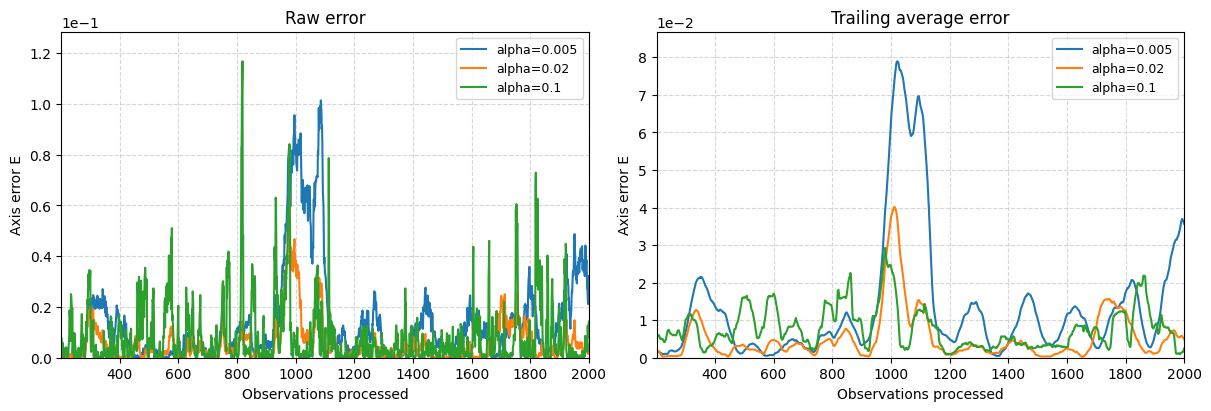

alpha=0.005 cumulative error from observation 1: 26.9869037057752
alpha=0.02 cumulative error from observation 1: 11.387455471221916
alpha=0.1 cumulative error from observation 1: 16.324486179075926


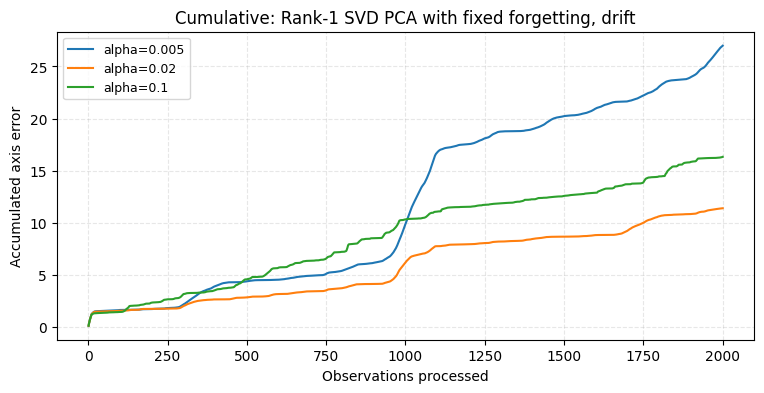

alpha=0.005 tracking angle-error SD (degrees): 5.687640696900274
alpha=0.02 tracking angle-error SD (degrees): 3.8179940660655802
alpha=0.1 tracking angle-error SD (degrees): 4.970818759095162


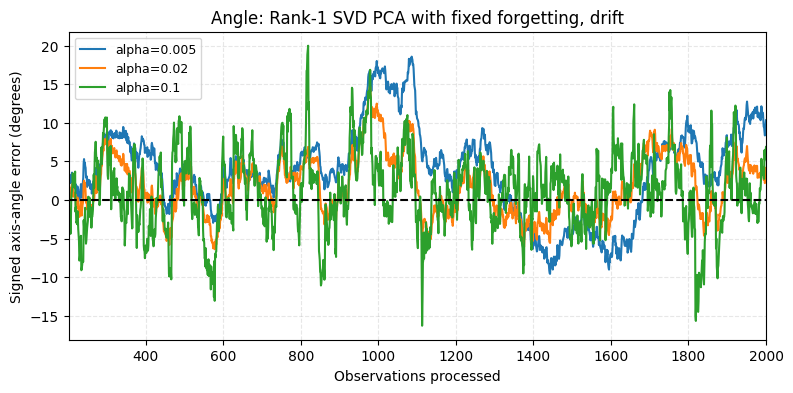

alpha=0.005 mean captured variance after warm-up (%): 89.76029041275129
alpha=0.02 mean captured variance after warm-up (%): 90.47017697890551
alpha=0.1 mean captured variance after warm-up (%): 90.27288949628894


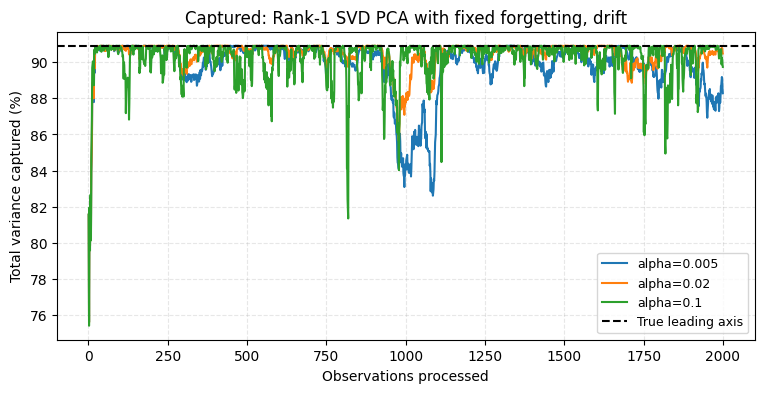

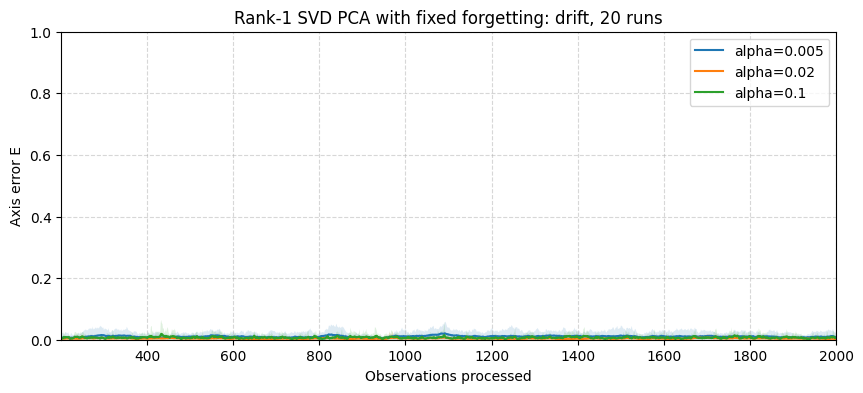

(<Figure size 1000x400 with 1 Axes>,
 <Axes: title={'center': 'Rank-1 SVD PCA with fixed forgetting: drift, 20 runs'}, xlabel='Observations processed', ylabel='Axis error E'>)

In [109]:
# Raw axis error and its trailing average: one seed, two panels.
ut.plot_stationary_errors(
    [rank_one_svd_drift_errors[alpha] for alpha in gains],
    [f'alpha={alpha:g}' for alpha in gains],
    warmup, smooth_window
)

# Accumulated raw error from observation 1, including the initial learning period.
total_curves = [np.cumsum(errors) for errors in [rank_one_svd_drift_errors[alpha] for alpha in gains]]
labels = [f'alpha={alpha:g}' for alpha in gains]
for total_error, label in zip(total_curves, labels):
    print(label, 'cumulative error from observation 1:', total_error[-1])
ut.plot_cumulative_error(total_curves, labels,
                      'Cumulative: Rank-1 SVD PCA with fixed forgetting, drift')

# Signed angular tracking error in degrees; SD excludes warm-up.
angle_curves = [axis_angle_error(directions, theta_drift)
                for directions in [rank_one_svd_drift_directions[alpha] for alpha in gains]]
labels = [f'alpha={alpha:g}' for alpha in gains]
for angles, label in zip(angle_curves, labels):
    print(label, 'tracking angle-error SD (degrees):', angles[warmup:].std())
ut.plot_angle_error(angle_curves, labels,
                 'Angle: Rank-1 SVD PCA with fixed forgetting, drift', warmup)

# Ground-truth population variance captured by the estimated axis, as a percentage.
percent_curves = [100 * (lam1 - (lam1 - lam2) * errors) / (lam1 + lam2)
                  for errors in [rank_one_svd_drift_errors[alpha] for alpha in gains]]
labels = [f'alpha={alpha:g}' for alpha in gains]
for percentages, label in zip(percent_curves, labels):
    print(label, 'mean captured variance after warm-up (%):',
          np.nanmean(percentages[warmup:]))
best_percent = 100 * lam1 / (lam1 + lam2)
ut.plot_captured_variance(percent_curves, labels,
                       'Captured: Rank-1 SVD PCA with fixed forgetting, drift', best_percent)

# Across-seed mean raw error and 10th-90th percentile band, not a confidence interval.
ut.plot_repeated_errors(
    [rank_one_svd_drift_runs[alpha] for alpha in gains], [f'alpha={alpha:g}' for alpha in gains],
    'Rank-1 SVD PCA with fixed forgetting: drift, 20 runs', start=0, warmup=warmup, upper_limit=1
)

**Plots.** Very close to forgetting PCA, with the same peaks around observation $1000$. Over 20 seeds the
truncation helps a little with $\alpha=0.1$ and costs a little with $\alpha=0.005$.

#### Repeated-run measurements

In [110]:
rows = []
for alpha in gains:
    runs = rank_one_svd_drift_runs[alpha]
    label = f'alpha={alpha:g}'
    run_means = runs[:, warmup:].mean(axis=1)
    mean_error = run_means.mean()
    sd_error = run_means.std(ddof=1)
    temporal_sd = runs[:, warmup:].std(axis=1).mean()
    rows.append([label, f'{mean_error:.5f}', f'{sd_error:.5f}', f'{temporal_sd:.5f}'])
ut.show_table(['Method', 'Mean E', 'SD of run means', 'Mean temporal SD'], rows)

| Method | Mean E | SD of run means | Mean temporal SD |
| --- | --- | --- | --- |
| alpha=0.005 | 0.01043 | 0.00367 | 0.01295 |
| alpha=0.02 | 0.00379 | 0.00068 | 0.00503 |
| alpha=0.1 | 0.00685 | 0.00086 | 0.01000 |


As in rotation, rank-1 is better where noise dominates ($\alpha=0.1$: $0.00685$ against
$0.00757$) and slightly worse where tracking error dominates ($\alpha=0.005$: $0.0104$ against $0.0093$); for
$\alpha=0.02$ the two are almost equal ($0.00379$ against $0.00366$), and it is still the best gain.

### Results for this method

Mean axis error after warm-up over 20 seeds, against forgetting PCA with the same gain (Section 2)
(abrupt: after the change, recovered runs, median delay).

| Gain | Method | Stationary | Abrupt, after the change | Rotation | Drift |
|---|---|---|---|---|---|
| $\alpha=0.1$ | forgetting | 0.00680 | 0.0110 (20/20, 53.5) | 0.00693 | 0.00757 |
| | rank-1 SVD | 0.00608 | 0.0116 (20/20, 56) | 0.00622 | 0.00685 |
| $\alpha=0.02$ | forgetting | 0.00121 | 0.0234 (20/20, 91.5) | 0.00383 | 0.00366 |
| | rank-1 SVD | 0.00108 | 0.0315 (20/20, 116) | 0.00428 | 0.00379 |
| $\alpha=0.005$ | forgetting | 0.00030 | 0.0894 (20/20, 260.5) | 0.0314 | 0.00926 |
| | rank-1 SVD | 0.00027 | 0.124 (20/20, 374.5) | 0.0401 | 0.0104 |

- **With forgetting, truncation does not prevent recovery**: every run recovers, for every gain. The error
  introduced at one step is discounted by $(1-\alpha)$ at the following steps, so it does not accumulate,
  unlike in Section 3 (no forgetting) and in the rank-1 sliding window of `02_sliding_window`, Section 5.
- **Whether this helps depends on what dominates.** In rotation and drift the rank-1 update is better with
  the large gain, where noise dominates ($0.00622$ against $0.00693$ in rotation), and worse with the small
  gain, where lag dominates ($0.0401$ against $0.0314$).
- In 2D, with both components kept, the SVD update is exactly the covariance update of Section 2 (Basic
  checks), so all these differences are due to truncation.

# Results

Mean axis error after warm-up over 20 seeds (abrupt: error after the change, recovered runs, median delay).

| Method | Stationary | Abrupt, after the change | Rotation | Drift |
|---|---|---|---|---|
| Cumulative ($\alpha_n=1/n$) | 0.00014 | 0.488 (0/20) | 0.296 | 0.0395 |
| Incremental, rank-1 SVD ($\alpha_n=1/n$) | 0.00015 | 0.562 (0/20) | 0.355 | 0.0438 |
| Forgetting, $\alpha=0.1$ | 0.00680 | 0.0110 (20/20, 53.5) | 0.00693 | 0.00757 |
| Forgetting, $\alpha=0.02$ | 0.00121 | 0.0234 (20/20, 91.5) | 0.00383 | 0.00366 |
| Forgetting, $\alpha=0.005$ | 0.00030 | 0.0894 (20/20, 260.5) | 0.0314 | 0.00926 |
| Rank-1 SVD forgetting, $\alpha=0.1$ | 0.00608 | 0.0116 (20/20, 56) | 0.00622 | 0.00685 |
| Rank-1 SVD forgetting, $\alpha=0.02$ | 0.00108 | 0.0315 (20/20, 116) | 0.00428 | 0.00379 |
| Rank-1 SVD forgetting, $\alpha=0.005$ | 0.00027 | 0.124 (20/20, 374.5) | 0.0401 | 0.0104 |

- **All four methods are the same recursion with different gains**, eq. (1) of the thesis proposal: the
  decreasing gain $\alpha_n=1/n$ (Sections 1 and 3) or a fixed gain $\alpha$ (Sections 2 and 4), applied to
  the full covariance (Sections 1 and 2) or to a rank-1 SVD (Sections 3 and 4).
- **Without forgetting the estimate does not track.** With $\alpha_n=1/n$ the error is the smallest in
  stationary data, but no run recovers after the abrupt change and the estimate cannot follow a moving
  direction.
- **A fixed gain trades noise for speed.** The stationary error grows about linearly with $\alpha$, as
  predicted by theory, while the recovery delay shrinks. In rotation and drift the best gain is
  intermediate.
- **Rank-1 truncation is a different point of the same trade-off**: slightly less noisy and slower with a
  fixed gain, harmful without forgetting. In 2D the full-rank SVD update coincides with the covariance
  update, so the comparison "SVD-based against covariance-based" is a comparison of truncated against full.
- **No fixed gain is best in every regime.** This is the trade-off that motivates choosing the gain over
  time; `04_sensitivity_analysis`, Part B, quantifies it on a finer grid of gains.
- **Cost.** Every method takes a few hundredths of a second for a stream of $2000$ observations; in 2D the
  time is dominated by the Python loop, not by the update.

## Basic checks

Check the recursions and verify that the repeated generator code really produces identical observations.

In [111]:
X_check, theta_check, truth_check = stationary_streams[0]
q, C = cumulative_pca(X_check[:100])
np.testing.assert_allclose(C, X_check[:100].T @ X_check[:100] / 100, atol=1e-12)

for alpha in gains:
    q, C = forgetting_pca(X_check[:100], alpha)
    expected = np.zeros((2, 2))
    for index in range(100):
        weight = alpha * (1 - alpha) ** (99 - index)
        x = X_check[index]
        expected += weight * np.outer(x, x)
    np.testing.assert_allclose(C, expected, atol=1e-12)

np.testing.assert_array_equal(X_check, stationary_streams[0][0])
np.testing.assert_array_equal(X_check, stationary_streams[0][0])
X_check = abrupt_streams[0][0]
np.testing.assert_array_equal(X_check, abrupt_streams[0][0])
np.testing.assert_array_equal(X_check, abrupt_streams[0][0])

short_X = X_check[:100]
full_q, full_C = incremental_pca(short_X, rank=2)
exact_q, exact_C = cumulative_pca(short_X)
np.testing.assert_allclose(full_C, exact_C, atol=1e-12)
np.testing.assert_allclose(axis_error(full_q, exact_q), 0, atol=1e-10)
q, C = incremental_pca(short_X)
assert np.isfinite(q).all()
np.testing.assert_allclose(np.linalg.norm(q, axis=1), 1, atol=1e-12)
np.testing.assert_allclose(axis_error(truth_check, -truth_check), 0, atol=1e-12)
assert recovery_delay(np.zeros(200), 0, threshold=recovery_threshold, window=smooth_window, hold=recovery_hold) == smooth_window
assert np.isnan(recovery_delay(np.ones(200), 0, threshold=recovery_threshold, window=smooth_window, hold=recovery_hold))
print('All checks passed.')

assert X_stationary is stationary_streams[seed][0]
assert X_abrupt is abrupt_streams[seed][0]
assert not X_stationary.flags.writeable
assert not X_abrupt.flags.writeable
print('Shared-data checks passed.')


All checks passed.
Shared-data checks passed.
